# Scalable photonic CV quantum reservoir computing — a native-Piquasso reproduction

**Paper reproduced:** J. García-Beni, G. L. Giorgi, M. C. Soriano and R. Zambrini,
*"Scalable Photonic Platform for Real-Time Quantum Reservoir Computing"*,
Physical Review Applied **20**, 014051 (2023) — DOI [10.1103/PhysRevApplied.20.014051](https://doi.org/10.1103/PhysRevApplied.20.014051),
arXiv:[2207.14031](https://arxiv.org/abs/2207.14031) (v2, 8 Jan 2023, used for every value quoted below).

> **Nature of the paper.** The 2023 paper is a *theoretical and numerical proposal*. It contains no experimental
> demonstration: every "result" it reports is a simulation of an idealised Gaussian model. This notebook reproduces
> those simulations. It does not reproduce any experiment.

### What this notebook reproduces

| # | Item | Paper location | Section here |
|---|---|---|---|
| 1 | Physical multimode Gaussian reservoir: $N$ modes per pulse, two random $\chi^{(2)}$ quadratic networks $S_1,S_2$ | Sec. II, Eqs. (1)–(2), App. C | 4.3, 5 |
| 2 | Squeezed-vacuum input encoding $r_k=1$, $\phi_k=3\pi s_k/4$ | Sec. III, Eqs. (C1)–(C3) | 4.2 |
| 3 | Recurrent optical-loop memory through a beam splitter of reflectivity $R$ | Eqs. (C12)–(C31), (F1)–(F2) | 4.4–4.5, 5 |
| 4 | Fading memory, initial-state forgetting, echo-state property $\rho(A)=\sqrt R<1$ | Eqs. (4)–(5), App. F | 4.6, 7 |
| 5 | Linear memory capacity | Fig. 2(a), App. B | 7.3, 9 |
| 6 | Degree-resolved information-processing capacity (Legendre, $d\le75$, $D\le5$) | Fig. 2(b), Eqs. (B1)–(B3) | 8, 9 |
| 7 | Ideal ($M\to\infty$) versus finite homodyne ensembles, $M^{-1/2}$ noise, SNR, $M'/M=R^{-2\Delta d}$ | Fig. 3, Eqs. (6)–(8), App. G | 10 |
| 8 | Scaling with $N$ under $R(N)=1-10/N^2$ and $M(N)=3N^6$ | Fig. 4, Eq. (9) | 11 |
| 9 | Santa Fe chaotic-laser one-step prediction, $N=12$, $R\in\{0.5,0.75,0.9\}$, $M\le10^6$ | Fig. 5, Sec. III D | 12 |
| 10 | Quantitative, status-labelled comparison with the paper | — | 13–14 |

### What is *not* reproduced (by design or because the paper gives no data)

* **No experiment.** The platform is simulated exactly as in the paper: Gaussian states, ideal homodyne detection, lossless loop.
* **Per-pulse conditional trajectories are not simulated.** The shared reservoir state is the *unconditional* reduced
  Gaussian state, as the paper argues in App. E (Eqs. E4–E5). Finite ensembles are modelled by drawing $M$ homodyne
  outcomes per round trip from that unconditional output state (Sec. 4.5 explains the consequences).
* **Encoding study (Fig. 6 / App. D)** and **SNR versus $N$ (Fig. 7)** are not required and are not recomputed. The
  paper's own values are used only where Sec. 13 needs them.
* **Fibre losses.** The paper assumes a lossless loop. Loss is implemented only as a *validated option*
  (`fiber_loss_theta = 0` by default) and is never used for any headline number.
* **No edge-of-chaos analysis, weak measurements, measurement feedback, external delay lines or classical surrogates.**
  Memory comes only from the recirculating optical loop.

### Implementation principles

* All quantum-optical dynamics use public **Piquasso** operations: `Vacuum`, `Covariance`, `Mean`, `Squeezing`,
  `Beamsplitter`, `GaussianTransform`, `Attenuator`, `HomodyneMeasurement`, `GaussianState.reduced`, plus the
  covariance and mean accessors.
* An independent NumPy covariance recurrence (`AnalyticCovarianceOracle`) is used **only** to validate Piquasso and to
  evaluate the paper's theoretical decompositions. It never produces reservoir features.
* Every figure, table, test and comparison is generated inside this notebook. The Santa Fe data are downloaded at
  runtime and checksum-verified. Checkpoints and outputs go only to the runtime's temporary directory, never to a repository.

**How to run:** `Runtime → Run all`. The default `RUN_MODE = "smoke"` is fast. Set `RUN_MODE = "validation"` or
`"paper"` in the next cell for the larger runs. Cost estimates are printed before every expensive cell.

In [1]:
# ======================= USER SWITCHES (the only cell that needs editing) =======================
RUN_MODE = "smoke"  # alternatives: "validation", "paper"
ENABLE_FINITE_SHOTS = True   # Sections 10-11 and the finite-M part of Section 12
ENABLE_SANTA_FE = True       # Section 12
SAVE_RESULTS = True          # figures / tables / JSON go to a temporary runtime directory only

## 2. Colab installation and environment

The next cell installs **pinned** versions of every dependency. It skips any package that is already installed at the
pinned version, so a local kernel prepared with the same pins installs nothing. Piquasso 8.0.1 requires `numba`, so
`numba` and `llvmlite` are pinned too; this avoids a NumPy/numba ABI mismatch on Colab. No GPU is needed: every
computation runs on the CPU.

In [2]:
import sys, subprocess, importlib, importlib.metadata as _md

PINNED = {
    "piquasso": "8.0.1", "numpy": "2.5.3", "scipy": "1.18.1", "numba": "0.67.0", "llvmlite": "0.49.0",
    "pandas": "3.0.6", "scikit-learn": "1.9.1", "matplotlib": "3.11.2", "seaborn": "0.13.2",
    "requests": "2.34.2", "tqdm": "4.70.1",
}

def _installed_version(pkg):
    try:
        return _md.version(pkg)
    except _md.PackageNotFoundError:
        return None

_preloaded = {m: sys.modules[m].__version__ for m in ("numpy", "scipy") if m in sys.modules}
_needed = [f"{p}=={v}" for p, v in PINNED.items() if _installed_version(p) != v]
if _needed:
    print("Installing pinned packages:", " ".join(_needed))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_needed])
    importlib.invalidate_caches()
else:
    print("All pinned packages are already installed.")
_stale = {m: v for m, v in _preloaded.items() if v != PINNED[m]}
if _stale:
    raise SystemExit(f"{_stale} were imported before the pinned install replaced them: "
                     "use Runtime -> Restart session, then Runtime -> Run all.")

All pinned packages are already installed.


In [3]:
import os, io, time, json, math, zlib, hashlib, platform, tempfile, pickle, shutil, warnings, itertools
from pathlib import Path

import numpy as np
import scipy, scipy.linalg as sla, scipy.special as ssp, scipy.stats as sst
import pandas as pd, sklearn, matplotlib, seaborn as sns, requests, tqdm as _tqdm_pkg, numba
import matplotlib.pyplot as plt
from tqdm.std import tqdm
from IPython.display import display, Markdown
import piquasso as pq
# Piquasso's own homodyne/general-dyne sampling kernel (the function HomodyneMeasurement dispatches to); see Sec. 10.
from piquasso._simulators.gaussian.simulation_steps import _get_generaldyne_samples as _pq_generaldyne_kernel

try:
    import google.colab  # noqa: F401
    RUNTIME = "Google Colab"
except ImportError:
    RUNTIME = "local Jupyter kernel"

def _cpu_name():
    try:
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()

def _gpu_name():
    if shutil.which("nvidia-smi") is None:
        return "none detected (not required)"
    out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                         capture_output=True, text=True)
    return out.stdout.strip() or "none detected (not required)"

def _ram():
    try:
        return f"{os.sysconf('SC_PHYS_PAGES') * os.sysconf('SC_PAGE_SIZE') / 1e9:.1f} GB"
    except (ValueError, AttributeError, OSError):
        return "unknown"

ENV = {
    "Python": sys.version.split()[0], "Piquasso": pq.__version__, "NumPy": np.__version__, "SciPy": scipy.__version__,
    "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__, "requests": requests.__version__, "tqdm": _tqdm_pkg.__version__, "numba": numba.__version__,
    "Runtime type": RUNTIME, "Platform": platform.platform(), "CPU": _cpu_name(), "Logical CPUs": os.cpu_count(),
    "RAM": _ram(), "GPU": _gpu_name(),
}
display(pd.DataFrame(ENV.items(), columns=["Item", "Value"]).set_index("Item"))
_mismatch = {p: _installed_version(p) for p, v in PINNED.items() if _installed_version(p) != v}
assert not _mismatch, f"Installed versions differ from the pins: {_mismatch}"

RESULTS_DIR = Path(tempfile.gettempdir()) / "garcia_beni_cv_qrc" / RUN_MODE
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Temporary runtime output directory:", RESULTS_DIR)
NOTEBOOK_T0 = time.time()

# Plot style: validated categorical palette in fixed order, one sequential blue ramp for ordered quantities (M).
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE_RAMP = ["#86b6ef", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "axes.grid": True, "grid.color": "#e4e4e4", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2.0, "lines.markersize": 5,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE), "legend.frameon": False, "font.size": 10,
})

def ramp(n):
    """n ordered colours from the sequential blue ramp (light = small, dark = large)."""
    return [BLUE_RAMP[i] for i in np.linspace(0, len(BLUE_RAMP) - 1, n).round().astype(int)]

def savefig(fig, name):
    if SAVE_RESULTS:
        fig.savefig(RESULTS_DIR / f"{name}.png", bbox_inches="tight")

def fmt_seconds(t):
    for unit, size in (("days", 86400), ("h", 3600), ("min", 60)):
        if t >= size:
            return f"{t / size:.1f} {unit}"
    return f"{t:.1f} s"

,Value
Item,
Python,3.12.14
Piquasso,8.0.1
NumPy,2.5.3
SciPy,1.18.1
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2
requests,2.34.2


Temporary runtime output directory: C:\Users\TONMOY~1\AppData\Local\Temp\garcia_beni_cv_qrc\smoke


## 3. Reproduction configuration

All parameters live in a single `GarciaBeniConfig` object. Values marked *paper* were read from the paper; the table
below gives the location of each. The first table lists the parameters shared by all modes. The second lists **every
parameter that changes between modes**, side by side, with the active mode marked `<== ACTIVE`.

Values checked against the paper text:
$\omega_i=1$, $g_{ij}\sim\mathcal U(0.1,0.3)$, $h_{ij}\sim\mathcal U(0.2,0.4)$, $\Delta t=1$ (Sec. III, p. 4–5);
$r_k=1$, $\phi_k=3\pi s_k/4$ (Sec. III, App. C; the same encoding is used for Santa Fe, Sec. III D);
$d_{\max}=75$, $D_{\max}=5$, $L=10^4$, $L'=5000$, $R^{L_m}<10^{-16}$ (App. B);
100 realisations per figure (Fig. 2 caption: "this average has been performed in every figure");
$M=300\ldots3\cdot10^6$ in powers of 10, $N=10$, $R=0.9$ (Fig. 3);
$R(N)=1-10N^{-2}$, $M(N)=3N^6$, constant $R=0.72$, $M=1.4\cdot10^5$ (Fig. 4 caption), where $R(6)=0.72$ and $M(6)\simeq1.4\cdot10^5$;
Santa Fe: 4000 points, $L=3000$, $R^{L_m}<10^{-8}$, $N=12$, $M\le10^6$ (Sec. III D, Fig. 5).

In [4]:
class GarciaBeniConfig(dict):
    """Active configuration with attribute access (COMMON parameters + the RUN_MODE preset + user switches)."""
    __getattr__ = dict.__getitem__

COMMON = dict(
    master_seed=20230714,
    omega=1.0, g_range=(0.1, 0.3), h_range=(0.2, 0.4), dt=1.0,          # paper, Sec. III
    r_squeeze=1.0, phi_coeff=3 * np.pi / 4,                               # paper, Sec. III / App. C
    input_low=-1.0, input_high=1.0,                                       # uniform inputs for Legendre IPC (App. B)
    hbar_piquasso=1.0,                                                    # makes Piquasso's covariance equal the paper's (Sec. 4.1)
    washout_tol_capacity=1e-16, washout_tol_santafe=1e-8,                 # paper, Eq. (B4) and Sec. III D
    d_max=75, D_max=5,                                                    # paper, App. B
    readout_rcond=1e-12, ridge=0.0,                                       # Moore-Penrose readout, Eq. (A6)
    ipc_surrogates_per_degree=20,                                         # false-positive capacity safeguard
    tol_convention=1e-10, tol_oracle=1e-8, tol_uncertainty=1e-8,
    homodyne_z=1e-4,                                                      # Piquasso default homodyne squeezing parameter
    shot_chunk=100_000, public_shot_chunk=5_000,                          # bounded-memory sampling batch sizes
    fiber_loss_theta=0.0,                                                 # lossless loop, as in the paper
    fading_steps=150, impulse_step=25, impulse_horizon=60,
    snr_d_max=40, snr_steps=200,
    santafe_n_points=4000, santafe_L_train=3000,                          # paper, Sec. III D
    scaling_C=10.0, scaling_M_coeff=3.0, scaling_M_power=6,               # paper, Fig. 4
    R_fading=[0.5, 0.75, 0.9], R_mem=[0.5, 0.75, 0.9, 0.97],
    R_ipc=[0.75, 0.9], R_fs=[0.9, 0.75], R_sf=[0.5, 0.75, 0.9],          # paper, Figs. 2, 3, 5
)

MODE_PRESETS = {
    "smoke": dict(
        N_ipc=[2, 3, 4], L_train=2000, L_test=1000, n_networks=3,
        N_mem=3, n_networks_mem=3, N_fading=3, n_networks_fading=3,
        N_fs=4, M_fs=[300, 3000, 30000], L_train_fs=1500, L_test_fs=500, n_networks_fs=2,
        M_public=[10, 30, 100, 300, 1000, 3000], M_kernel=[100, 1000, 10**4, 10**5, 10**6], n_rep_scaling=12,
        N_size=[4, 5], L_train_size=1500, L_test_size=750, n_networks_size=2,
        N_sf=4, M_sf=[100, 1000, 10**4], n_networks_sf=3, n_networks_sf_fs=3,
        homodyne_sampler="kernel", checkpoint=False),
    "validation": dict(
        N_ipc=[4, 5, 6, 7, 8], L_train=5000, L_test=2500, n_networks=10,
        N_mem=8, n_networks_mem=5, N_fading=6, n_networks_fading=10,
        N_fs=8, M_fs=[300, 3000, 30000, 300000], L_train_fs=3000, L_test_fs=1000, n_networks_fs=2,
        M_public=[10, 30, 100, 300, 1000, 3000, 10000], M_kernel=[100, 1000, 10**4, 10**5, 10**6], n_rep_scaling=30,
        N_size=[4, 5, 6], L_train_size=3000, L_test_size=1000, n_networks_size=3,
        N_sf=8, M_sf=[100, 1000, 10**4, 10**5], n_networks_sf=10, n_networks_sf_fs=5,
        homodyne_sampler="kernel", checkpoint=False),
    "paper": dict(
        N_ipc=[4, 5, 6, 7, 8, 9, 10], L_train=10000, L_test=5000, n_networks=100,
        N_mem=10, n_networks_mem=100, N_fading=10, n_networks_fading=100,
        N_fs=10, M_fs=[300, 3000, 30000, 300000, 3000000], L_train_fs=10000, L_test_fs=5000, n_networks_fs=100,
        M_public=[10, 30, 100, 300, 1000, 3000, 10000, 30000], M_kernel=[100, 1000, 10**4, 10**5, 10**6, 3 * 10**6],
        n_rep_scaling=50,
        N_size=[6, 7, 8, 9, 10, 11, 12], L_train_size=10000, L_test_size=5000, n_networks_size=100,
        N_sf=12, M_sf=[100, 1000, 10**4, 10**5, 10**6], n_networks_sf=100, n_networks_sf_fs=100,
        homodyne_sampler="kernel", checkpoint=True),
}
assert RUN_MODE in MODE_PRESETS, f"RUN_MODE must be one of {list(MODE_PRESETS)}"
assert all(set(p) == set(MODE_PRESETS["smoke"]) for p in MODE_PRESETS.values()), "presets must share keys"
CFG = GarciaBeniConfig({**COMMON, **MODE_PRESETS[RUN_MODE], "RUN_MODE": RUN_MODE,
                        "ENABLE_FINITE_SHOTS": ENABLE_FINITE_SHOTS, "ENABLE_SANTA_FE": ENABLE_SANTA_FE,
                        "SAVE_RESULTS": SAVE_RESULTS})
CONFIG_FINGERPRINT = hashlib.sha1(json.dumps(CFG, sort_keys=True, default=str).encode()).hexdigest()[:12]

def _fmt(v):
    return f"{v:.6g}" if isinstance(v, float) else str(v)

print(f"RUN_MODE = {RUN_MODE!r}   (config fingerprint {CONFIG_FINGERPRINT})")
display(pd.DataFrame([(k, _fmt(v)) for k, v in COMMON.items()], columns=["Shared parameter", "Value"])
        .set_index("Shared parameter"))
modes_table = pd.DataFrame({m: {k: _fmt(v) for k, v in p.items()} for m, p in MODE_PRESETS.items()})
modes_table.index.name = "Mode-dependent parameter"
modes_table = modes_table.rename(columns={RUN_MODE: f"{RUN_MODE}  <== ACTIVE"})
display(modes_table)
if SAVE_RESULTS:
    (RESULTS_DIR / "config.json").write_text(json.dumps(CFG, indent=1, default=str))

RUN_MODE = 'smoke'   (config fingerprint 78101d110571)


,Value
Shared parameter,
master_seed,20230714
omega,1
g_range,"(0.1, 0.3)"
h_range,"(0.2, 0.4)"
dt,1
r_squeeze,1
phi_coeff,2.35619
input_low,-1
input_high,1


,smoke <== ACTIVE,validation,paper
Mode-dependent parameter,,,
N_ipc,"[2, 3, 4]","[4, 5, 6, 7, 8]","[4, 5, 6, 7, 8, 9, 10]"
L_train,2000,5000,10000
L_test,1000,2500,5000
n_networks,3,10,100
N_mem,3,8,10
n_networks_mem,3,5,100
N_fading,3,6,10
n_networks_fading,3,10,100
N_fs,4,8,10


### Seeds

Every random object (networks, input strings, surrogate targets, homodyne samples) takes a **child seed** derived
deterministically from the master seed and a descriptive tag, through `numpy.random.SeedSequence`. Results therefore do
not depend on cell execution order, and any single realisation can be regenerated on its own. All seeds used are
recorded in `SEED_REGISTRY` and printed in Section 14.

In [5]:
SEED_REGISTRY = {}

def child_seed(*tags):
    """Deterministic 63-bit child seed from the master seed and descriptive tags."""
    words = [CFG.master_seed] + [zlib.crc32(repr(t).encode()) for t in tags]
    seed = int(np.random.SeedSequence(words).generate_state(1, dtype=np.uint64)[0]) >> 1
    SEED_REGISTRY[tags] = seed
    return seed

print("master seed:", CFG.master_seed)
print("example child seed ('networks', N=4, net=0):", child_seed("networks", 4, 0))

master seed: 20230714
example child seed ('networks', N=4, net=0): 3107300587690981944


## 4. Mathematical formulation

### 4.1 Gaussian conventions

**Paper convention (App. C).** The measured quadratures are $\hat x_i=\hat a_i+\hat a_i^\dagger$ (Sec. II) and
$\hat p_i=-i(\hat a_i-\hat a_i^\dagger)$. Hence
$$[\hat x_i,\hat p_j]=2i\,\delta_{ij},$$
which is the $\hbar=2$ convention written as $[\hat q_i,\hat p_j]=i\hbar\delta_{ij}$. For
$\hat{\boldsymbol\xi}=(\hat x_1,\hat p_1,\ldots,\hat x_N,\hat p_N)^T$ the covariance matrix is
$\sigma_{ij}=\tfrac12\langle\{\Delta\hat\xi_i,\Delta\hat\xi_j\}\rangle$. The vacuum has $\sigma=\mathbb 1$, and every
physical state satisfies $\sigma+i\Omega\ge0$ with $\Omega=\bigoplus_{i=1}^N\begin{pmatrix}0&1\\-1&0\end{pmatrix}$.

**Piquasso convention (checked in the installed source and in the tests below).** `pq.Config().hbar` defaults to 2.
Piquasso's quadratures satisfy $[\hat x,\hat p]=i\hbar$ with $\hat x=\sqrt{\hbar/2}(\hat a+\hat a^\dagger)$. Its
covariance matrix, however, is defined *without* the factor $\tfrac12$:
$$\sigma^{\rm PQ}_{ij}=\langle\hat Y_i\hat Y_j+\hat Y_j\hat Y_i\rangle-2\langle\hat Y_i\rangle\langle\hat Y_j\rangle,
\qquad \sigma^{\rm PQ}_{\rm vac}=\hbar\,\mathbb 1 .$$
Setting `hbar = 1` gives $\sigma^{\rm PQ}=2\,{\rm Cov}(\hat x)={\rm Cov}(\sqrt2\hat x)={\rm Cov}(\hat a+\hat a^\dagger)$,
which is exactly the paper's $\sigma$ (vacuum $=\mathbb 1$). Piquasso's homodyne sampler draws outcomes from
$\mathcal N(\mu,\sigma^{\rm PQ}_{xx}+\hbar z^2)$. For the zero-mean states used here, the samples therefore have exactly
the statistics of the paper's $\hat x_i=\hat a_i+\hat a_i^\dagger$ (vacuum variance 1), up to a detector term
$z^2=10^{-8}$.

**Numerical hygiene.** Piquasso stores the state as the complex moments $C=\langle a^\dagger a
angle$ and
$G=\langle aa
angle$. After many round trips its covariance accessor returns a matrix with round-off asymmetry. The
reservoir feeds the loop state back every round trip, and the antisymmetric part is amplified: it is not a covariance,
so the contraction $
ho(A)^2=R$ does not apply to it. `cov_of` therefore returns $	frac12(\sigma+\sigma^T)$. This is
exact for any physical state, and it keeps Piquasso within $10^{-14}$ of the oracle over hundreds of round trips (test 10).

**Ordering.** We use Piquasso's `xpxp_covariance_matrix`, i.e. $(x_1,p_1,x_2,p_2,\ldots)$. The `xxpp` ordering
$(x_1,\ldots,x_N,p_1,\ldots,p_N)$ is related to it by a fixed permutation, which is tested below.

In [6]:
HBAR = CFG.hbar_piquasso
TOL = CFG.tol_convention

def pq_config(seed=None, validate=False):
    return pq.Config(hbar=HBAR, validate=validate, seed_sequence=seed)

def execute(d, build, seed=None, shots=1, validate=False):
    """Run the Piquasso instructions emitted by `build()` on d modes and return the Result."""
    with pq.Program() as program:
        build()
    return pq.GaussianSimulator(d=d, config=pq_config(seed, validate)).execute(program, shots=shots)

def cov_of(state):
    """Dimensionless covariance in the paper's convention (vacuum = identity), xpxp ordering.

    Piquasso's internal (C, G) update leaves O(1e-16) round-off asymmetry in the covariance. Fed back through the
    loop, that antisymmetric component is NOT governed by the contracting covariance map and grows by ~10% per
    round trip. A covariance matrix is symmetric by definition, so we return its symmetric part.
    """
    cov = np.asarray(state.xpxp_covariance_matrix, float) / HBAR
    return 0.5 * (cov + cov.T)

def mean_of(state):
    return np.asarray(state.xpxp_mean_vector, float) / np.sqrt(HBAR)

def omega_xpxp(n):
    return np.kron(np.eye(n), np.array([[0.0, 1.0], [-1.0, 0.0]]))

def xxpp_to_xpxp_index(n):
    idx = np.empty(2 * n, dtype=int)
    idx[0::2], idx[1::2] = np.arange(n), np.arange(n, 2 * n)
    return idx

def x_block(cov):
    return cov[0::2, 0::2]

def uncertainty_min_eig(cov):
    """Smallest eigenvalue of sigma + i*Omega (>= 0 for a physical state, = 0 for a pure state)."""
    return float(np.linalg.eigvalsh(cov + 1j * omega_xpxp(len(cov) // 2)).min())

# ---------------------------------------------------------------- test registry (used again in Section 6)
TEST_REGISTRY, TEST_RESULTS = {}, {}

def physics_test(name, fundamental=True):
    def register(fn):
        TEST_REGISTRY[name] = (fn, fundamental)
        return fn
    return register

def run_test(name):
    fn, fundamental = TEST_REGISTRY[name]
    t0 = time.time()
    try:
        detail, ok = fn(), True
    except Exception as exc:  # a failing assertion or a crash both count as failure
        detail, ok = f"{type(exc).__name__}: {exc}", False
    TEST_RESULTS[name] = dict(test=name, passed=ok, fundamental=fundamental, detail=detail,
                              seconds=round(time.time() - t0, 2))
    print(("PASS  " if ok else "FAIL  ") + name + "  |  " + str(detail))
    return ok

@physics_test("01 vacuum covariance, hbar and [x,p]")
def test_vacuum_convention():
    def vac():
        pq.Q(all) | pq.Vacuum()
    with pq.Program() as prog:
        vac()
    default_state = pq.GaussianSimulator(d=2).execute(prog).state
    assert pq.Config().hbar == 2.0, "Piquasso default hbar changed"
    assert np.allclose(default_state.xpxp_covariance_matrix, 2 * np.eye(4), atol=TOL), "default vacuum is not 2*I"
    state = execute(2, vac).state
    assert np.allclose(cov_of(state), np.eye(4), atol=TOL), "hbar=1 vacuum is not I"
    xp, px = state.get_xp_string_moment([0, 2]), state.get_xp_string_moment([2, 0])   # xxpp indices: x0=0, p0=2
    xx = state.get_xp_string_moment([0, 0])
    assert abs((xp - px) - 1j * HBAR) < TOL, "[x,p] != i*hbar"
    assert abs(xx - HBAR / 2) < TOL, "<x^2>_vac != hbar/2"
    def vac_homodyne():
        pq.Q(all) | pq.Vacuum()
        pq.Q(0) | pq.HomodyneMeasurement(z=CFG.homodyne_z)
    shots = 4000
    X = np.asarray(execute(1, vac_homodyne, seed=child_seed("test", "vacuum-homodyne"), shots=shots).samples)[:, 0]
    var, se = X.var(), np.sqrt(2 / shots)
    assert abs(var - 1) < 5 * se, f"homodyne vacuum variance {var:.3f} != 1"
    return (f"default hbar=2 -> vacuum 2I; hbar=1 -> vacuum I, [x,p]={complex(xp - px):.2f}, <x^2>={xx.real:.2f} "
            f"(so sigma_PQ = 2 Cov(x) = Cov(a+a^dag)); homodyne Var(X)={var:.3f}+-{se:.3f}")

@physics_test("04 quadrature ordering xpxp <-> xxpp")
def test_ordering():
    def build():
        pq.Q(all) | pq.Vacuum()
        pq.Q(1) | pq.Squeezing(r=0.5, phi=0.3)
    state = execute(3, build).state
    c_xpxp, c_xxpp = cov_of(state), np.asarray(state.xxpp_covariance_matrix) / HBAR
    idx = xxpp_to_xpxp_index(3)
    assert np.allclose(c_xxpp[np.ix_(idx, idx)], c_xpxp, atol=TOL)
    touched = set(np.argwhere(np.abs(c_xpxp - np.eye(6)) > 1e-9).ravel().tolist())
    assert touched == {2, 3}, f"mode 1 should occupy xpxp indices 2,3, got {touched}"
    return "xpxp = (x1,p1,x2,p2,...); mode j occupies xpxp indices (2j, 2j+1); xxpp permutation verified"

run_test("01 vacuum covariance, hbar and [x,p]")
run_test("04 quadrature ordering xpxp <-> xxpp")

PASS  01 vacuum covariance, hbar and [x,p]  |  default hbar=2 -> vacuum 2I; hbar=1 -> vacuum I, [x,p]=0.00+1.00j, <x^2>=0.50 (so sigma_PQ = 2 Cov(x) = Cov(a+a^dag)); homodyne Var(X)=0.994+-0.022
PASS  04 quadrature ordering xpxp <-> xxpp  |  xpxp = (x1,p1,x2,p2,...); mode j occupies xpxp indices (2j, 2j+1); xxpp permutation verified


True

### 4.2 Squeezed input encoding

For every input $s_k$ the paper prepares an ancilla pulse of $N$ identical single-mode squeezed vacua,
$\sigma_{\rm anc}(s_k)=\bigoplus_{i=1}^N\sigma_{\rm sq}(s_k)$ (App. C), with $r_k=1$ and $\phi_k=\tfrac{3\pi}{4}s_k$
(Sec. III; the same encoding is used for Santa Fe, Sec. III D):
$$
\sigma_{\rm sq}(s_k)=\begin{pmatrix}c_+(s_k)&z(s_k)\\ z(s_k)&c_-(s_k)\end{pmatrix},\qquad
c_\pm=\cosh 2r_k\pm\cos\phi_k\sinh 2r_k,\qquad z=\sin\phi_k\sinh 2r_k .
$$

**Piquasso's squeezing gate** implements $\hat a\mapsto\cosh r\,\hat a-e^{i\varphi}\sinh r\,\hat a^\dagger$. Writing
$\hat x'=\hat a'+\hat a'^\dagger$ and $\hat p'=i(\hat a'^\dagger-\hat a')$:
$$
\hat x'=(\cosh r-\sinh r\cos\varphi)\hat x-\sinh r\sin\varphi\,\hat p,\qquad
\hat p'=(\cosh r+\sinh r\cos\varphi)\hat p-\sinh r\sin\varphi\,\hat x .
$$
Acting on the vacuum ($\sigma=\mathbb 1$) this gives
$$
\sigma^{\rm PQ}(r,\varphi)=\begin{pmatrix}\cosh2r-\sinh2r\cos\varphi & -\sinh2r\sin\varphi\\
-\sinh2r\sin\varphi & \cosh2r+\sinh2r\cos\varphi\end{pmatrix}.
$$
This equals the paper's $\sigma_{\rm sq}$ if and only if $\cos\varphi=-\cos\phi$ and $\sin\varphi=-\sin\phi$,
i.e. **$\varphi_{\rm PQ}=\phi_{\rm paper}+\pi$**. With the naive choice $\varphi=\phi$ the ancilla would be squeezed
along the orthogonal axis, which changes the encoding. The cell below verifies the mapping.

In [7]:
PQ_SQUEEZE_PHASE_OFFSET = np.pi   # derived above, verified below

def sigma_sq_paper(s, r=CFG.r_squeeze, coeff=CFG.phi_coeff):
    phi = coeff * s
    ch, sh = np.cosh(2 * r), np.sinh(2 * r)
    return np.array([[ch + np.cos(phi) * sh, np.sin(phi) * sh], [np.sin(phi) * sh, ch - np.cos(phi) * sh]])

def piquasso_squeezed_cov(s, offset=PQ_SQUEEZE_PHASE_OFFSET):
    def build():
        pq.Q(all) | pq.Vacuum()
        pq.Q(0) | pq.Squeezing(r=CFG.r_squeeze, phi=CFG.phi_coeff * s + offset)
    return cov_of(execute(1, build).state)

TEST_INPUTS = [-1.0, -0.6, -0.2, 0.0, 0.35, 0.8, 1.0]

@physics_test("02 squeezed-vacuum covariance vs Eqs. (C1)-(C3)")
def test_squeezed_covariance():
    errs = [np.abs(piquasso_squeezed_cov(s) - sigma_sq_paper(s)).max() for s in TEST_INPUTS]
    dets = [np.linalg.det(piquasso_squeezed_cov(s)) for s in TEST_INPUTS]
    assert max(errs) < 1e-10, f"max error {max(errs):.2e}"
    assert np.allclose(dets, 1.0, atol=1e-9), "squeezed vacuum must be pure (det sigma = 1)"
    return f"max |sigma_PQ - sigma_sq| = {max(errs):.1e} over {len(TEST_INPUTS)} inputs; det sigma = 1 (pure)"

@physics_test("03 squeezing-angle convention phi_PQ = phi_paper + pi")
def test_squeezing_angle():
    naive = max(np.abs(piquasso_squeezed_cov(s, offset=0.0) - sigma_sq_paper(s)).max() for s in TEST_INPUTS)
    right = max(np.abs(piquasso_squeezed_cov(s) - sigma_sq_paper(s)).max() for s in TEST_INPUTS)
    assert naive > 1.0 and right < 1e-10
    return f"offset pi: error {right:.1e};  naive offset 0: error {naive:.2f} (rejected)"

rows = []
for s in TEST_INPUTS:
    a, b = piquasso_squeezed_cov(s), sigma_sq_paper(s)
    rows.append(dict(s=s, phi_paper=CFG.phi_coeff * s, c_plus_paper=b[0, 0], c_plus_PQ=a[0, 0], z_paper=b[0, 1],
                     z_PQ=a[0, 1], c_minus_paper=b[1, 1], c_minus_PQ=a[1, 1], max_abs_error=np.abs(a - b).max()))
display(pd.DataFrame(rows).round(12))
run_test("02 squeezed-vacuum covariance vs Eqs. (C1)-(C3)")
run_test("03 squeezing-angle convention phi_PQ = phi_paper + pi")

,s,phi_paper,c_plus_paper,c_plus_PQ,z_paper,z_PQ,c_minus_paper,c_minus_PQ,max_abs_error
0,-1.00,-2.356194,1.197618,1.197618,-2.564578,-2.564578,6.326773,6.326773,0.0
1,-0.60,-1.413717,4.329562,4.329562,-3.582208,-3.582208,3.194830,3.194830,0.0
2,-0.20,-0.471239,6.993752,6.993752,-1.646560,-1.646560,0.530639,0.530639,0.0
3,0.00,0.000000,7.389056,7.389056,0.000000,-0.000000,0.135335,0.135335,0.0
4,0.35,0.824668,6.224111,6.224111,2.663285,2.663285,1.300280,1.300280,0.0
5,0.80,1.884956,2.641434,2.641434,3.449349,3.449349,4.882957,4.882957,0.0
6,1.00,2.356194,1.197618,1.197618,2.564578,2.564578,6.326773,6.326773,0.0


PASS  02 squeezed-vacuum covariance vs Eqs. (C1)-(C3)  |  max |sigma_PQ - sigma_sq| = 8.9e-16 over 7 inputs; det sigma = 1 (pure)
PASS  03 squeezing-angle convention phi_PQ = phi_paper + pi  |  offset pi: error 8.9e-16;  naive offset 0: error 7.25 (rejected)


True

### 4.3 Multimode quadratic networks

Each $\chi^{(2)}$ crystal is modelled by the paper's quadratic Hamiltonian (Eqs. 1–2),
$$
\hat H=\sum_i\omega_i\hat a_i^\dagger\hat a_i+\sum_{j>i}\left(g_{ij}\hat a_i^\dagger\hat a_j+i h_{ij}\hat a_i^\dagger\hat a_j^\dagger+\text{h.c.}\right),
$$
with $\omega_i=1$, $g_{ij}\sim\mathcal U(0.1,0.3)$, $h_{ij}\sim\mathcal U(0.2,0.4)$ and $\Delta t=1$. These values were
checked in Sec. III ("$\langle g\rangle=0.2$, $\langle h\rangle=0.3$, $\Delta g=\Delta h=0.1$ and the interaction time
inside each crystal is set to one"). Two independent draws give $S_1$ (fibre-path crystal) and $S_2$ (detector-path
crystal).

**1 — Hamiltonian matrix.** Write $\hat H=\sum_{ij}W_{ij}\hat a_i^\dagger\hat a_j+\tfrac12\sum_{ij}(V_{ij}\hat a_i^\dagger\hat a_j^\dagger+\bar V_{ij}\hat a_i\hat a_j)$
with $W=\mathrm{diag}(\omega)+G$, where $G_{ij}=G_{ji}=g_{ij}$, and $V_{ij}=V_{ji}=i h_{ij}$ ($V$ symmetric, zero diagonal).
With $\hat{\boldsymbol\alpha}=(\hat{\mathbf a},\hat{\mathbf a}^\dagger)$ this is
$\hat H=\tfrac12\hat{\boldsymbol\alpha}^\dagger H_c\hat{\boldsymbol\alpha}+\text{const}$, where
$H_c=\begin{pmatrix}W&V\\ \bar V&\bar W\end{pmatrix}$.

**2 — Heisenberg equations.** $\dot{\hat a}_k=i[\hat H,\hat a_k]=-i\sum_j(W_{kj}\hat a_j+V_{kj}\hat a_j^\dagger)$, i.e.
$\dot{\hat{\boldsymbol\alpha}}=-iK\hat{\boldsymbol\alpha}$ with $K=\begin{pmatrix}W&V\\-\bar V&-\bar W\end{pmatrix}=\sigma_zH_c$.

**3 — Symplectic generator.** With $\hat{\boldsymbol\xi}=(\hat{\mathbf x},\hat{\mathbf p})=T\hat{\boldsymbol\alpha}$, where
$T=\begin{pmatrix}\mathbb 1&\mathbb 1\\-i\mathbb 1&i\mathbb 1\end{pmatrix}$, we get
$\hat H=\tfrac12\hat{\boldsymbol\xi}^TH_1\hat{\boldsymbol\xi}$ with the real symmetric $H_1=T^{-\dagger}H_cT^{-1}$.
Because $[\hat\xi_i,\hat\xi_j]=2i\Omega_{ij}$ (paper convention), $\dot{\hat{\boldsymbol\xi}}=2\Omega H_1\hat{\boldsymbol\xi}$.

**4 — Symplectic evolution.** $S(\Delta t)=e^{2\Omega H_1\Delta t}=T\,S_c\,T^{-1}$, with $S_c=e^{-iK\Delta t}$, and
$S\Omega S^T=\Omega$. The paper's App. F writes $e^{\Omega H_1\Delta t}$ with its $H_1$ normalised to twice ours; the two
are the same map.

**5 — Bogoliubov form for Piquasso.** $S_c=\begin{pmatrix}P&A\\ \bar A&\bar P\end{pmatrix}$ with $P=[e^{-iK\Delta t}]_{11}$ and
$A=[e^{-iK\Delta t}]_{12}$, so $PP^\dagger-AA^\dagger=\mathbb 1$ and $PA^T=AP^T$. This is exactly the argument of
`pq.GaussianTransform(passive=P, active=A)`, whose docstring defines $S_{(c)}=\begin{pmatrix}P&A\\ \bar A&\bar P\end{pmatrix}$.
The covariance transforms as $\sigma\mapsto S\sigma S^T$.

**Stability (App. F).** Only positive-definite Hamiltonians are kept, $H_1>0\Leftrightarrow H_c>0$. By Williamson's
theorem the spectrum of $\Omega H_1$ is then purely imaginary, so every eigenvalue of $S$ has modulus 1 and
$\rho(S_1)=1$. **Draws with $H_c\not>0$ are rejected and redrawn, never clipped.** With all-to-all couplings the
rejection rate grows with $N$ (large at $N=12$).

In [8]:
class GaussianNetworkFactory:
    """Random quadratic chi^(2) networks of Eqs. (1)-(2) with stability rejection sampling."""

    def __init__(self, N, cfg=None):
        self.N, self.cfg = N, cfg or CFG

    def hamiltonian(self, rng):
        N, c = self.N, self.cfg
        iu = np.triu_indices(N, 1)
        g = rng.uniform(*c.g_range, size=len(iu[0]))
        h = rng.uniform(*c.h_range, size=len(iu[0]))
        W = c.omega * np.eye(N, dtype=complex)
        V = np.zeros((N, N), dtype=complex)
        W[iu], W[iu[::-1]] = g, g
        V[iu], V[iu[::-1]] = 1j * h, 1j * h
        return W, V

    @staticmethod
    def complex_hamiltonian(W, V):
        return np.block([[W, V], [V.conj(), W.conj()]])

    @staticmethod
    def _T(N):
        I = np.eye(N)
        return np.block([[I, I], [-1j * I, 1j * I]])

    @classmethod
    def real_hamiltonian(cls, W, V):
        """H1 (xpxp) with H = 1/2 xi^T H1 xi, xi = (x, p), x = a + a^dag."""
        N = len(W)
        Ti = np.linalg.inv(cls._T(N))
        H1 = Ti.conj().T @ cls.complex_hamiltonian(W, V) @ Ti
        assert np.abs(H1.imag).max() < 1e-12
        idx = xxpp_to_xpxp_index(N)
        return H1.real[np.ix_(idx, idx)]

    @staticmethod
    def bogoliubov(W, V, dt):
        N = len(W)
        U = sla.expm(-1j * dt * np.block([[W, V], [-V.conj(), -W.conj()]]))
        return U[:N, :N], U[:N, N:]

    @classmethod
    def real_symplectic(cls, P, A):
        """Real symplectic matrix (xpxp) of the Bogoliubov map a -> P a + A a^dag."""
        N = len(P)
        T = cls._T(N)
        S = T @ np.block([[P, A], [A.conj(), P.conj()]]) @ np.linalg.inv(T)
        assert np.abs(S.imag).max() < 1e-10
        idx = xxpp_to_xpxp_index(N)
        return S.real[np.ix_(idx, idx)]

    def draw(self, rng):
        rejected = 0
        while True:
            W, V = self.hamiltonian(rng)
            Hc = self.complex_hamiltonian(W, V)
            if np.linalg.eigvalsh(Hc).min() > 0:
                break
            rejected += 1                      # unstable draw: reject and redraw (never clip)
        P, A = self.bogoliubov(W, V, self.cfg.dt)
        return dict(W=W, V=V, Hc=Hc, H1=self.real_hamiltonian(W, V), P=P, A=A,
                    S=self.real_symplectic(P, A), rejected=rejected)

    def draw_pair(self, seed):
        """Two independent crystals (S1: fibre path, S2: detector path) from one child seed."""
        rng = np.random.default_rng(seed)
        return self.draw(rng), self.draw(rng)

def random_valid_cov(N, rng, nu_max=3.0):
    """A random physical mixed Gaussian covariance: symplectic * thermal * symplectic^T."""
    S = GaussianNetworkFactory(N).draw(rng)["S"]
    return S @ np.diag(np.repeat(rng.uniform(1.0, nu_max, N), 2)) @ S.T

@physics_test("06 symplecticity of S1,S2 and Piquasso GaussianTransform action")
def test_symplectic():
    worst = dict(sympl=0.0, bogo=0.0, gen=0.0, pq=0.0)
    rng = np.random.default_rng(child_seed("test", "symplectic"))
    for N in (2, 4, 6):
        for net in GaussianNetworkFactory(N).draw_pair(child_seed("test", "networks", N)):
            S, P, A, Om = net["S"], net["P"], net["A"], omega_xpxp(N)
            worst["sympl"] = max(worst["sympl"], np.abs(S @ Om @ S.T - Om).max())
            worst["bogo"] = max(worst["bogo"], np.abs(P @ P.conj().T - A @ A.conj().T - np.eye(N)).max(),
                                np.abs(P @ A.T - A @ P.T).max())
            worst["gen"] = max(worst["gen"], np.abs(sla.expm(2 * Om @ net["H1"] * CFG.dt) - S).max())
            cov_in = random_valid_cov(N, rng)
            def build():
                pq.Q(all) | pq.Covariance(cov=cov_in)
                pq.Q(all) | pq.GaussianTransform(passive=P, active=A)
            worst["pq"] = max(worst["pq"], np.abs(cov_of(execute(N, build).state) - S @ cov_in @ S.T).max()
                              / np.abs(cov_in).max())
    assert max(worst.values()) < 1e-9, worst
    return ("max |S Om S^T - Om| = {sympl:.1e}; Bogoliubov constraints {bogo:.1e}; |exp(2 Om H1 dt) - S| = {gen:.1e}; "
            "Piquasso GaussianTransform vs S sigma S^T (rel.) = {pq:.1e}").format(**worst)

@physics_test("07 stability of accepted networks (H>0, |eig S|=1, rho(A)=sqrt R)")
def test_stability():
    for N in (2, 4, 8):
        for net in GaussianNetworkFactory(N).draw_pair(child_seed("test", "stability", N)):
            assert np.linalg.eigvalsh(net["Hc"]).min() > 0
            assert np.linalg.eigvalsh(net["H1"]).min() > 0
            assert np.abs(np.abs(np.linalg.eigvals(net["S"])) - 1).max() < 1e-8
            for R in (0.5, 0.75, 0.9):
                rho = np.abs(np.linalg.eigvals(np.sqrt(R) * net["S"])).max()
                assert abs(rho - np.sqrt(R)) < 1e-8
    rng = np.random.default_rng(child_seed("test", "rejection-rate"))
    rejected = [GaussianNetworkFactory(12).draw(rng)["rejected"] for _ in range(20)]
    rate = sum(rejected) / (sum(rejected) + 20)
    return f"H_c>0, H1>0, |eig S|=1, rho(sqrt(R) S1)=sqrt(R) for N in (2,4,8); rejection rate at N=12: {rate:.2f}"

example = GaussianNetworkFactory(4).draw_pair(child_seed("example-network", 4))
for name, net in zip(("S1", "S2"), example):
    print(f"{name}: rejected draws = {net['rejected']}, min eig(H_c) = {np.linalg.eigvalsh(net['Hc']).min():.3f}, "
          f"max |S Om S^T - Om| = {np.abs(net['S'] @ omega_xpxp(4) @ net['S'].T - omega_xpxp(4)).max():.2e}, "
          f"max ||eig S| - 1| = {np.abs(np.abs(np.linalg.eigvals(net['S'])) - 1).max():.1e}")
run_test("06 symplecticity of S1,S2 and Piquasso GaussianTransform action")
run_test("07 stability of accepted networks (H>0, |eig S|=1, rho(A)=sqrt R)")

S1: rejected draws = 0, min eig(H_c) = 0.427, max |S Om S^T - Om| = 2.22e-16, max ||eig S| - 1| = 8.9e-16
S2: rejected draws = 0, min eig(H_c) = 0.348, max |S Om S^T - Om| = 5.55e-16, max ||eig S| - 1| = 1.3e-15
PASS  06 symplecticity of S1,S2 and Piquasso GaussianTransform action  |  max |S Om S^T - Om| = 6.7e-16; Bogoliubov constraints 6.7e-16; |exp(2 Om H1 dt) - S| = 5.6e-16; Piquasso GaussianTransform vs S sigma S^T (rel.) = 5.3e-16
PASS  07 stability of accepted networks (H>0, |eig S|=1, rho(A)=sqrt R)  |  H_c>0, H1>0, |eig S|=1, rho(sqrt(R) S1)=sqrt(R) for N in (2,4,8); rejection rate at N=12: 0.94


True

### 4.4 Beam-splitter coupling

The paper's beam splitter (Eq. C14) acts on the pair (reservoir mode, ancilla mode) as
$$
B_R=\begin{pmatrix}\sqrt R\,\mathbb 1_2&\sqrt T\,\mathbb 1_2\\-\sqrt T\,\mathbb 1_2&\sqrt R\,\mathbb 1_2\end{pmatrix},\qquad T=1-R,
$$
so the loop receives $\sqrt R\,(\text{reservoir})+\sqrt T\,(\text{ancilla})$ and the detector path receives
$-\sqrt T\,(\text{reservoir})+\sqrt R\,(\text{ancilla})$.

Piquasso's `Beamsplitter(theta, phi)` has transfer matrix $U=\begin{pmatrix}t&-\bar r\\ r&t\end{pmatrix}$ with $t=\cos\theta$ and
$r=e^{i\phi}\sin\theta$. With $\phi=\pi$ this gives $U=\begin{pmatrix}\cos\theta&\sin\theta\\-\sin\theta&\cos\theta\end{pmatrix}$,
which is $B_R$ for $\cos\theta=\sqrt R$. **The reflectivity is therefore $R=\cos^2\theta$** (not $\sin^2\theta$). The test
below determines this experimentally in three ways:

1. by sending squeezed light into the loop port and measuring how much of it stays in the loop;
2. from the signs of the first moments;
3. from the full $4\times4$ symplectic action on a correlated input.

In [9]:
def beam_splitter_theta(R):
    return float(np.arccos(np.sqrt(R)))            # verified convention: R = cos^2(theta), phi = pi

def paper_bs_matrix(R):
    return np.block([[np.sqrt(R) * np.eye(2), np.sqrt(1 - R) * np.eye(2)],
                     [-np.sqrt(1 - R) * np.eye(2), np.sqrt(R) * np.eye(2)]])

@physics_test("05 beam-splitter reflectivity convention R = cos^2(theta)")
def test_beam_splitter():
    rows, rng = [], np.random.default_rng(child_seed("test", "bs"))
    for R in (0.5, 0.75, 0.9):
        theta = beam_splitter_theta(R)
        def squeezed_in():
            pq.Q(all) | pq.Vacuum()
            pq.Q(0) | pq.Squeezing(r=1.0, phi=np.pi)       # anti-squeezed x in the loop port
            pq.Q(0, 1) | pq.Beamsplitter(theta=theta, phi=np.pi)
        c_in = piquasso_squeezed_cov(0.0)
        c_out = cov_of(execute(2, squeezed_in).state)
        R_meas = (c_out[0, 0] - 1) / (c_in[0, 0] - 1)
        def displaced():
            pq.Q(all) | pq.Mean(mean=np.array([1.0, 0.0, 0.0, 0.0]))
            pq.Q(0, 1) | pq.Beamsplitter(theta=theta, phi=np.pi)
        mu = mean_of(execute(2, displaced).state)
        cov_in = random_valid_cov(2, rng)                  # correlated, mixed two-mode input
        def generic():
            pq.Q(all) | pq.Covariance(cov=cov_in)
            pq.Q(0, 1) | pq.Beamsplitter(theta=theta, phi=np.pi)
        B = paper_bs_matrix(R)
        err = np.abs(cov_of(execute(2, generic).state) - B @ cov_in @ B.T).max()
        rows.append(dict(R=R, theta=theta, cos2=np.cos(theta) ** 2, sin2=np.sin(theta) ** 2, R_measured=R_meas,
                         loop_mean=mu[0], detector_mean=mu[2], sqrtR=np.sqrt(R), minus_sqrtT=-np.sqrt(1 - R),
                         full_matrix_error=err))
        assert abs(R_meas - np.cos(theta) ** 2) < 1e-10
        assert R == 0.5 or abs(R_meas - np.sin(theta) ** 2) > 1e-3     # cos^2 = sin^2 only at R = 1/2
        assert abs(mu[0] - np.sqrt(R)) < 1e-10 and abs(mu[2] + np.sqrt(1 - R)) < 1e-10 and err < 1e-10
    display(pd.DataFrame(rows).round(12))
    return "R_measured = cos^2(theta) (sin^2 rejected); mean signs and full 4x4 action match B_R of Eq. (C14)"

run_test("05 beam-splitter reflectivity convention R = cos^2(theta)")

,R,theta,cos2,sin2,R_measured,loop_mean,detector_mean,sqrtR,minus_sqrtT,full_matrix_error
0,0.50,0.785398,0.50,0.50,0.50,0.707107,-0.707107,0.707107,-0.707107,0.0
1,0.75,0.523599,0.75,0.25,0.75,0.866025,-0.500000,0.866025,-0.500000,0.0
2,0.90,0.321751,0.90,0.10,0.90,0.948683,-0.316228,0.948683,-0.316228,0.0


PASS  05 beam-splitter reflectivity convention R = cos^2(theta)  |  R_measured = cos^2(theta) (sin^2 rejected); mean signs and full 4x4 action match B_R of Eq. (C14)


True

### 4.5 Recurrent reservoir channel

**Mode routing.** Modes $0\ldots N-1$ are the loop (fibre) pulse and modes $N\ldots2N-1$ the ancilla/detector pulse.

```mermaid
flowchart LR
  L["loop pulse sigma_k (N modes)"] --> BS{"N beam splitters<br/>R = cos^2 theta"}
  A["ancilla: N squeezed vacua<br/>r=1, phi=3 pi s_k/4"] --> BS
  BS -- "sqrt(R) loop + sqrt(T) anc" --> C1["chi(2) crystal S1"] --> F["fibre, tau_rt"] -- "reduced state sigma_(k+1)" --> L
  BS -- "-sqrt(T) loop + sqrt(R) anc" --> C2["chi(2) crystal S2"] --> HD["multimode homodyne of all x_i"]
```

```
 sigma_k (loop, modes 0..N-1) ──┐        ┌── S1 ── fibre ── reduce to loop modes ──► sigma_{k+1}
                                 ├─ BS(R) ┤
 sigma_anc(s_k) (modes N..2N-1) ─┘        └── S2 ── homodyne x_1..x_N ──► O_ij^(k) = <X_i X_j> - <X_i><X_j>
```

**One round trip executed natively by Piquasso** (`NativePiquassoCVReservoir.round_trip`):
(1) `Covariance` prepares $\sigma_k\oplus\mathbb 1_{2N}$; (2) `Squeezing(r=1, φ=3πs_k/4+π)` on every ancilla mode;
(3)–(4) `Beamsplitter(θ, π)` on each pair $(i, N+i)$; (5) `GaussianTransform(P_1,A_1)` on the loop modes and
`GaussianTransform(P_2,A_2)` on the detector modes; (6) optional fibre `Attenuator` (off in the paper model);
(7) `state.reduced(detector modes)` gives the output covariance, or `HomodyneMeasurement` gives samples;
(8) `state.reduced(loop modes)` gives the **unconditional** loop state $\sigma_{k+1}$, which (9) is prepared again in
the next round trip.

**Covariance recurrence.** Starting from $\Gamma_0=\sigma_k\oplus\sigma_{\rm anc}(s_k)$ and applying
$(S_1\oplus S_2)B_R$ (Eqs. C16–C20):
$$
\sigma_{\rm fiber}=S_1(R\sigma_k+T\sigma_{\rm anc})S_1^T,\quad
\sigma_{\rm HD}=S_2(T\sigma_k+R\sigma_{\rm anc})S_2^T,\quad
\sigma_{\rm corr}=\sqrt{RT}\,S_1(\sigma_k-\sigma_{\rm anc})S_2^T .
$$
The unconditional reduced loop state is the $\sigma_{\rm fiber}$ block. Including an optional fibre loss (attenuator
angle $\theta_L$, i.e. transmissivity $\cos^2\theta_L$, applied after $S_1$):
$$
\boxed{\sigma_{k+1}=A\sigma_kA^T+B\sigma_{\rm anc}(s_k)B^T+Y,\qquad A=\cos\theta_L\sqrt R\,S_1,\ \ B=\cos\theta_L\sqrt{T}\,S_1,\ \ Y=\sin^2\theta_L\,\mathbb 1}
$$
The paper's lossless model has $\theta_L=0\Rightarrow Y=0$. The beam splitter adds no vacuum noise, because both of its
input ports are used.

**Readout.** Homodyne detection of all $x$ quadratures (Piquasso $z\to$ detector variance $z^2=10^{-8}$, i.e. the
$\sigma_m\to0$ limit of Eq. C9) gives the $N(N+1)/2$ observables
$O^{(k)}_{ij}=[\sigma_{\rm HD}^{(k)}]_{x_ix_j}$, $j\ge i$.

**Why the unconditional state.** Each of the $M$ pulses is conditioned on its own measurement record (Eqs. C22–C23).
Ensemble averages over pulses nevertheless reproduce the unconditional dynamics (App. E, Eqs. E4–E5); this is what
the paper uses and what the reservoir state here is. The finite-$M$ model (Sec. 10) draws $M$ fresh homodyne outcomes
per round trip from the unconditional output state. This gives the correct statistics of each round-trip estimate,
but it ignores the correlations between successive estimates of the same physical pulse.

### 4.6 Fading memory

Unrolling the lossless recurrence from an initial loop state $\sigma_0$:
$$
\sigma_k=R^k S_1^k\sigma_0S_1^{kT}+\sum_{j=1}^{k}T R^{j-1}S_1^j\sigma_{\rm anc}(s_{k-j})S_1^{jT},
$$
and therefore (Eqs. 4, E4–E6), after tracing out the $p$ quadratures,
$$
\sigma^{(k)}_{\rm ideal}=\sum_{d=0}^{\infty}\gamma^{(k)}_d+\sigma_m,\qquad
\gamma_0^{(k)}=R\,{\rm Tr}_p\{S_2\sigma_{\rm anc}(s_k)S_2^T\},\qquad
\gamma_d^{(k)}=(1-R)^2R^{d-1}{\rm Tr}_p\{S_2S_1^d\sigma_{\rm anc}(s_{k-d})S_1^{dT}S_2^T\}\ (d\ge1).
$$
Each $\gamma_d$ depends on a *single* past input. The $(1-R)^2$ comes from two transmissions (into the loop and out to
the detector), and $R^{d-1}$ from $d-1$ reflections inside the loop. Because $S_1$ is symplectic with unimodular
eigenvalues, $\|S_1^d(\cdot)S_1^{dT}\|$ stays bounded and oscillates. After averaging over networks and inputs only
$R^{d-1}$ survives (App. E), so $\|\gamma_d\|\propto(1-R)^2R^{d-1}$.

**Echo-state property (App. F).** The quadrature operators obey $\hat{\mathbf r}_{k+1}=A\hat{\mathbf r}_k+B\hat{\mathbf r}^{\rm anc}_k$
with $A=\sqrt R S_1$. Since $\rho(S_1)=1$ for a stable $H_1$, $\rho(A)=\sqrt R<1$ for every $R<1$. That is both the
echo-state and the fading-memory condition. Four different decays follow, and all are measured separately in Section 7:

| quantity | law per round trip | origin |
|---|---|---|
| first moments $\boldsymbol\mu_k$ (displaced initial states) | $\propto R^{k/2}$ | $\boldsymbol\mu_{k+1}=A\boldsymbol\mu_k$ |
| covariance difference of two initial states $\|\sigma^{(1)}_k-\sigma^{(2)}_k\|$ | $\propto R^{k}$ | $\Delta_{k+1}=A\Delta_kA^T$, $\rho(A)^2=R$ |
| memory response to one input $\|\partial O^{(k+d)}/\partial s_k\|$ | $\propto(1-R)^2R^{d-1}$ | the $\gamma_d$ above |
| measured signal-to-noise $\langle\lvert\gamma_d/\xi_M\rvert\rangle$ | $\sqrt M(1-R)^2R^{d-1}$ | $\xi_M\propto M^{-1/2}$ (App. G) |

The last line implies that resolving $\Delta d$ extra delays costs $M'/M=R^{-2\Delta d}$ times more pulses (Eq. 7).

## 5. Native Piquasso implementation

All classes are defined in this notebook:

* `GarciaBeniConfig` (Sec. 3) and `GaussianNetworkFactory` (Sec. 4.3).
* `NativePiquassoCVReservoir`: the primary reservoir. Each round trip is one Piquasso program on $2N$ modes.
* `AnalyticCovarianceOracle`: an independent NumPy recurrence, used for validation and theory only.
* `LinearReadout`: the Moore–Penrose linear readout with bias (Eqs. A2–A6).
* `CapacityAnalyzer`: linear memory capacity $C_d$ and memory depth.
* `IPCAnalyzer`: Legendre information-processing capacity with a false-positive safeguard.
* `OnlineMoments` + `FiniteShotEstimator`: bounded-memory, chunk-exact estimators computed from Piquasso homodyne samples.

In [10]:
def feature_dim(N):
    return N * (N + 1) // 2

def washout_length(R, tol, minimum=0):
    """Smallest L_m with R**L_m < tol (paper: Eq. B4 / Sec. III D), and at least `minimum`."""
    return max(int(np.floor(np.log(tol) / np.log(R))) + 1, minimum)

class NativePiquassoCVReservoir:
    """Garcia-Beni recurrent photonic reservoir; every round trip is executed by Piquasso."""

    def __init__(self, N, R, networks, cfg=None, loss_theta=None):
        self.cfg = cfg or CFG
        self.N, self.R = N, float(R)
        self.net1, self.net2 = networks
        self.theta_bs = beam_splitter_theta(R)
        self.loss_theta = self.cfg.fiber_loss_theta if loss_theta is None else loss_theta
        self.loop_modes, self.detector_modes = tuple(range(N)), tuple(range(N, 2 * N))
        self.simulator = pq.GaussianSimulator(d=2 * N, config=pq_config())
        self._iu = np.triu_indices(N)

    def program(self, cov_loop, mean_loop, s):
        N, c = self.N, self.cfg
        with pq.Program() as program:
            pq.Q(all) | pq.Covariance(cov=sla.block_diag(cov_loop, np.eye(2 * N)))   # loop state (x) vacuum ancillas
            if mean_loop is not None:
                pq.Q(all) | pq.Mean(mean=np.concatenate([mean_loop, np.zeros(2 * N)]))
            for i in self.detector_modes:                                           # squeezed-vacuum input encoding
                pq.Q(i) | pq.Squeezing(r=c.r_squeeze, phi=c.phi_coeff * s + PQ_SQUEEZE_PHASE_OFFSET)
            for i in range(N):                                                      # loop/ancilla coupling, R = cos^2
                pq.Q(i, N + i) | pq.Beamsplitter(theta=self.theta_bs, phi=np.pi)
            pq.Q(*self.loop_modes) | pq.GaussianTransform(passive=self.net1["P"], active=self.net1["A"])
            pq.Q(*self.detector_modes) | pq.GaussianTransform(passive=self.net2["P"], active=self.net2["A"])
            if self.loss_theta:
                for i in self.loop_modes:
                    pq.Q(i) | pq.Attenuator(theta=self.loss_theta)
        return program

    def round_trip(self, cov_loop, mean_loop, s):
        """One round trip: returns (next loop cov, next loop mean, detector cov, full 2N-mode Piquasso state)."""
        state = self.simulator.execute(self.program(cov_loop, mean_loop, s)).state
        loop, detector = state.reduced(self.loop_modes), state.reduced(self.detector_modes)
        return cov_of(loop), (None if mean_loop is None else mean_of(loop)), cov_of(detector), state

    def features(self, cov_detector):
        return x_block(cov_detector)[self._iu]

    def run(self, inputs, cov0=None, mean0=None, keep_loop=False, keep_output=False):
        N, T = self.N, len(inputs)
        cov = np.eye(2 * N) if cov0 is None else np.array(cov0, float)
        mean = None if mean0 is None else np.array(mean0, float)
        out = {"features": np.empty((T, feature_dim(N)))}
        if keep_loop:
            out["loop_cov"] = np.empty((T, 2 * N, 2 * N))
            if mean is not None:
                out["loop_mean"] = np.empty((T, 2 * N))
        if keep_output:
            out["output_cov"] = np.empty((T, 2 * N, 2 * N))
        for k, s in enumerate(inputs):
            cov, mean, cov_out, _ = self.round_trip(cov, mean, s)
            out["features"][k] = self.features(cov_out)
            if keep_loop:
                out["loop_cov"][k] = cov
                if mean is not None:
                    out["loop_mean"][k] = mean
            if keep_output:
                out["output_cov"][k] = cov_out
        return out

class AnalyticCovarianceOracle:
    """Independent NumPy recurrence (Eqs. C28-C29 + optional loss). Validation and theory ONLY."""

    def __init__(self, N, R, networks, cfg=None, loss_theta=None):
        cfg = cfg or CFG
        loss = cfg.fiber_loss_theta if loss_theta is None else loss_theta
        self.N, self.R, self.T = N, float(R), 1.0 - float(R)
        self.S1, self.S2 = networks[0]["S"], networks[1]["S"]
        self.A = np.cos(loss) * np.sqrt(R) * self.S1
        self.B = np.cos(loss) * np.sqrt(1 - R) * self.S1
        self.Y = np.sin(loss) ** 2 * np.eye(2 * N)
        self._iu = np.triu_indices(N)

    def sigma_anc(self, s):
        return np.kron(np.eye(self.N), sigma_sq_paper(s))

    def step(self, cov_loop, s):
        sa = self.sigma_anc(s)
        new_loop = self.A @ cov_loop @ self.A.T + self.B @ sa @ self.B.T + self.Y
        output = self.S2 @ (self.T * cov_loop + self.R * sa) @ self.S2.T
        return new_loop, output

    def run(self, inputs, cov0=None):
        cov = np.eye(2 * self.N) if cov0 is None else cov0
        loops, outs = [], []
        for s in inputs:
            cov, out = self.step(cov, s)
            loops.append(cov)
            outs.append(out)
        return np.array(loops), np.array(outs)

    def gamma(self, d, s):
        """x-block of gamma_d (Eq. E6) for the lossless model: contribution of input s at delay d."""
        sa = self.sigma_anc(s)
        if d == 0:
            G = self.R * self.S2 @ sa @ self.S2.T
        else:
            Sd = self.S2 @ np.linalg.matrix_power(self.S1, d)
            G = self.T ** 2 * self.R ** (d - 1) * Sd @ sa @ Sd.T
        return x_block(G)

def nmse(y, y_hat):
    """Paper Eq. (A5): sum (y_hat - y)^2 / sum y^2, column-wise."""
    return ((y_hat - y) ** 2).sum(0) / (y ** 2).sum(0)

class LinearReadout:
    """y = w0 + w^T v; weights by the Moore-Penrose pseudo-inverse (Eq. A6) on standardised features."""

    def __init__(self, rcond=None, ridge=None):
        self.rcond = CFG.readout_rcond if rcond is None else rcond
        self.ridge = CFG.ridge if ridge is None else ridge

    def _design(self, F):
        return np.hstack([np.ones((len(F), 1)), (F - self.mu) / self.sd])

    def fit(self, F, Y):
        self.mu, sd = F.mean(0), F.std(0)
        self.sd = np.where(sd > 0, sd, 1.0)
        V = self._design(F)
        if self.ridge > 0:
            self.W = np.linalg.solve(V.T @ V + self.ridge * np.eye(V.shape[1]), V.T @ Y)
        else:
            self.W = np.linalg.lstsq(V, Y, rcond=self.rcond)[0]
        return self

    def predict(self, F):
        return self._design(F) @ self.W

def lagged(s, start, length, d):
    """s_{k-d} for k = start ... start+length-1 (requires start >= d)."""
    assert start >= d
    return s[start - d: start - d + length]

def legendre_normalized(D, x):
    """sqrt(2D+1) P_D(x): unit second moment for x ~ U(-1,1)."""
    return np.sqrt(2 * D + 1) * ssp.eval_legendre(D, x)

class CapacityAnalyzer:
    """Linear memory capacity C_d = max(0, 1 - NMSE_d) for targets s_{k-d} (App. B)."""

    def __init__(self, d_max=None):
        self.d_max = CFG.d_max if d_max is None else d_max

    def _targets(self, s, start, length):
        return np.column_stack([lagged(s, start, length, d) for d in range(self.d_max + 1)])

    def linear_capacity(self, F_tr, s_tr, start_tr, F_te, s_te, start_te):
        readout = LinearReadout().fit(F_tr, self._targets(s_tr, start_tr, len(F_tr)))
        return np.clip(1 - nmse(self._targets(s_te, start_te, len(F_te)), readout.predict(F_te)), 0, None)

    @staticmethod
    def memory_depth(C, level=0.5):
        """Delay at which C_d first drops below `level` (linear interpolation); d_max if it never does."""
        below = np.flatnonzero(C < level)
        if len(below) == 0:
            return float(len(C) - 1)
        i = below[0]
        if i == 0:
            return 0.0
        return float(i - 1 + (C[i - 1] - level) / (C[i - 1] - C[i]))

class IPCAnalyzer:
    """IPC of Eqs. (B1)-(B3): targets P_D(s_{k-d}), D=1..D_max, d=0..d_max, with a surrogate-based threshold."""

    def __init__(self, seed, d_max=None, D_max=None, n_surrogates=None):
        self.d_max = CFG.d_max if d_max is None else d_max
        self.D_max = CFG.D_max if D_max is None else D_max
        self.n_sur = CFG.ipc_surrogates_per_degree if n_surrogates is None else n_surrogates
        self.rng = np.random.default_rng(seed)

    def _targets(self, s, start, length):
        return np.column_stack([legendre_normalized(D, lagged(s, start, length, d))
                                for D in range(1, self.D_max + 1) for d in range(self.d_max + 1)])

    def _surrogates(self, length):
        u = self.rng.uniform(CFG.input_low, CFG.input_high, size=(length, self.n_sur))
        return np.column_stack([legendre_normalized(D, u[:, j]) for D in range(1, self.D_max + 1)
                                for j in range(self.n_sur)])

    def capacities(self, F_tr, s_tr, start_tr, F_te, s_te, start_te):
        n_real = self.D_max * (self.d_max + 1)
        Y_tr = np.hstack([self._targets(s_tr, start_tr, len(F_tr)), self._surrogates(len(F_tr))])
        Y_te = np.hstack([self._targets(s_te, start_te, len(F_te)), self._surrogates(len(F_te))])
        C = np.clip(1 - nmse(Y_te, LinearReadout().fit(F_tr, Y_tr).predict(F_te)), 0, None)
        C_raw, C_sur = C[:n_real].reshape(self.D_max, self.d_max + 1), C[n_real:]
        threshold = float(C_sur.max())                     # largest capacity of targets with zero true capacity
        C_thr = np.where(C_raw > threshold, C_raw, 0.0)
        D_out, n_kept = F_tr.shape[1], int((C_thr > 0).sum())
        sv = np.linalg.svd(F_te - F_te.mean(0), compute_uv=False)
        rank = int((sv > 1e-9 * sv[0]).sum())               # effective number of independent observables
        tol = 3 * np.sqrt(n_kept * 2.0 / len(F_te)) + n_kept * float(C_sur.mean())
        by_degree = C_thr.sum(1)
        return dict(C_raw=C_raw, C=C_thr, threshold=threshold, surrogate_mean=float(C_sur.mean()),
                    by_degree=by_degree, total=float(by_degree.sum()), D_out=D_out,
                    normalized=float(by_degree.sum() / D_out), rank=rank, per_rank=float(by_degree.sum() / rank),
                    bound_tolerance=tol, n_kept=n_kept)

def check_ipc_bound(ipc, label=""):
    assert ipc["total"] <= ipc["D_out"] + ipc["bound_tolerance"], (
        f"{label}: IPC {ipc['total']:.3f} exceeds N(N+1)/2 = {ipc['D_out']} + tol {ipc['bound_tolerance']:.3f}")

class OnlineMoments:
    """Chan-Golub-LeVeque streaming mean/covariance + raw 4th-order sums; exact under any chunking."""

    def __init__(self, N, fourth_order=False):
        self.n, self.mean, self.M2 = 0, np.zeros(N), np.zeros((N, N))
        self.fourth = fourth_order
        if fourth_order:
            self.S22, self.S31 = np.zeros((N, N)), np.zeros((N, N))

    def update(self, X):
        m = len(X)
        mb = X.mean(0)
        Xc = X - mb
        n = self.n + m
        delta = mb - self.mean
        self.mean = self.mean + delta * (m / n)
        self.M2 = self.M2 + Xc.T @ Xc + np.outer(delta, delta) * (self.n * m / n)
        self.n = n
        if self.fourth:
            X2 = X * X
            self.S22 += X2.T @ X2          # sum X_i^2 X_j^2
            self.S31 += (X2 * X).T @ X     # sum X_i^3 X_j
        return self

    def result(self):
        out = {"n": self.n, "mean": self.mean.copy(), "cov": self.M2 / self.n}   # O_ij = <XiXj>_M - <Xi>_M<Xj>_M
        if self.fourth:
            out["m22"], out["m31"] = self.S22 / self.n, self.S31 / self.n
        return out

class FiniteShotEstimator:
    """Finite homodyne ensembles of M pulses, sampled by Piquasso from the unconditional output state.

    sampler="public": pq.HomodyneMeasurement executed by GaussianSimulator(shots=m).
    sampler="kernel": the same Piquasso sampling routine that HomodyneMeasurement dispatches to, called without
                      building one post-measurement state per shot (same outcomes; see test 15).
    """

    def __init__(self, N, seed, sampler=None, chunk=None, z=None):
        self.N, self.seed = N, seed
        self.sampler = sampler or CFG.homodyne_sampler
        assert self.sampler in ("public", "kernel")
        self.z = CFG.homodyne_z if z is None else z
        self.chunk = chunk or (CFG.public_shot_chunk if self.sampler == "public" else CFG.shot_chunk)
        self.simulator = pq.GaussianSimulator(d=N, config=pq_config(seed))
        self.modes = tuple(range(N))
        self.detection_cov = np.array([[self.z ** 2, 0.0], [0.0, self.z ** -2]])   # HomodyneMeasurement(z) definition

    def sample(self, cov, m):
        """m homodyne outcomes (X_1..X_N) of the N-mode Gaussian state with covariance `cov` (xpxp)."""
        with pq.Program() as program:
            pq.Q(all) | pq.Covariance(cov=cov)
            if self.sampler == "public":
                pq.Q(all) | pq.HomodyneMeasurement(z=self.z)
        if self.sampler == "public":
            X = np.asarray(self.simulator.execute(program, shots=int(m)).samples, dtype=float)
        else:
            state = self.simulator.execute(program).state
            X = _pq_generaldyne_kernel(state, self.modes, int(m), self.detection_cov)
        return X[:, 0::2] / np.sqrt(HBAR)       # x outcomes; the p columns belong to the z -> 0 detector port

    def estimate(self, cov, M_list, fourth_order=False):
        """Nested estimates for every M in M_list from one stream of max(M_list) pulses, sampled in chunks."""
        acc, snapshots = OnlineMoments(self.N, fourth_order), {}
        for M in sorted({int(m) for m in M_list}):
            while acc.n < M:
                acc.update(self.sample(cov, min(self.chunk, M - acc.n)))
            snapshots[M] = acc.result()
        return snapshots

def wick_fourth_moments(cov_x):
    """Zero-mean Gaussian: <Xi^2 Xj^2> = s_ii s_jj + 2 s_ij^2, <Xi^3 Xj> = 3 s_ii s_ij (Isserlis)."""
    d = np.diag(cov_x)
    return np.outer(d, d) + 2 * cov_x ** 2, 3 * d[:, None] * cov_x

# ------------------------------------------------------------------ runtime estimates and checkpoints
_BENCH_STEP, _BENCH_SHOT, COST_LOG = {}, {}, []

def bench_round_trip(N):
    if N not in _BENCH_STEP:
        res = NativePiquassoCVReservoir(N, 0.8, GaussianNetworkFactory(N).draw_pair(child_seed("bench", N)))
        res.run(np.zeros(3))
        t0 = time.perf_counter()
        res.run(np.linspace(-1, 1, 20))
        _BENCH_STEP[N] = (time.perf_counter() - t0) / 20
    return _BENCH_STEP[N]

def bench_shot(N):
    """(seconds per shot vector, seconds of overhead per estimator call) for the configured sampler."""
    key = (N, CFG.homodyne_sampler)
    if key not in _BENCH_SHOT:
        est = FiniteShotEstimator(N, seed=child_seed("bench-shots", N))
        cov = np.eye(2 * N)
        t0 = time.perf_counter(); est.estimate(cov, [10]); t1 = time.perf_counter()
        m = 20000 if est.sampler == "kernel" else 500
        est.estimate(cov, [m]); t2 = time.perf_counter()
        _BENCH_SHOT[key] = ((t2 - t1) / m, t1 - t0)
    return _BENCH_SHOT[key]

def announce_cost(label, steps_by_N, shots_by_N=None, calls_by_N=None, memory_bytes=0):
    """Print the estimated runtime / memory of an experiment before running it."""
    t = sum(n * bench_round_trip(N) for N, n in steps_by_N.items())
    for N, n in (shots_by_N or {}).items():
        t += n * bench_shot(N)[0]
    for N, n in (calls_by_N or {}).items():
        t += n * bench_shot(N)[1]
    chunk_mem = max([8 * 2 * N * CFG.shot_chunk for N in (shots_by_N or {})] + [0])
    COST_LOG.append(dict(experiment=label, estimated_seconds=t, mode=RUN_MODE))
    print(f"[cost] {label}: ~{fmt_seconds(t)} on this machine | Piquasso round trips: "
          f"{sum(steps_by_N.values()):,} | homodyne shot vectors: {sum((shots_by_N or {}).values()):,.0f} | "
          f"peak extra memory ~{(memory_bytes + chunk_mem) / 1e6:.0f} MB")
    return t

_MEMO = {}
CKPT_DIR = RESULTS_DIR / f"checkpoints_{CONFIG_FINGERPRINT}"

def checkpointed(key, compute):
    """In-memory cache; in paper mode also resumable pickles in the temporary runtime directory."""
    if key in _MEMO:
        return _MEMO[key]
    path = CKPT_DIR / (hashlib.sha1(repr(key).encode()).hexdigest()[:16] + ".pkl")
    if CFG.checkpoint and path.exists():
        _MEMO[key] = pickle.loads(path.read_bytes())
        return _MEMO[key]
    value = compute()
    if CFG.checkpoint:
        CKPT_DIR.mkdir(parents=True, exist_ok=True)
        path.write_bytes(pickle.dumps(value))
    _MEMO[key] = value
    return value

def networks_for(N, net_id, family="networks"):
    return GaussianNetworkFactory(N).draw_pair(child_seed(family, N, net_id))

print("Implementation loaded. Piquasso round-trip time: " +
      ", ".join(f"N={N}: {bench_round_trip(N) * 1e3:.2f} ms" for N in sorted({2, 4, CFG.N_mem, max(CFG.N_ipc)})))

Implementation loaded. Piquasso round-trip time: N=2: 0.96 ms, N=3: 1.15 ms, N=4: 1.15 ms


## 6. Unit and physics validation

Tests 01–07 were defined and run in Section 4. The cell below adds tests 08–18 and runs the full suite into a
pass/fail table. **If any fundamental test fails, the notebook stops here with an error.**

In [11]:
def _test_setup(N=3, R=0.75, tag="t"):
    nets = networks_for(N, 0, family=f"test-{tag}")
    return nets, NativePiquassoCVReservoir(N, R, nets), AnalyticCovarianceOracle(N, R, nets)

@physics_test("08 physical uncertainty sigma + i Omega >= 0 for every covariance")
def test_uncertainty():
    worst = np.inf
    for N, R in ((2, 0.5), (3, 0.9), (4, 0.75)):
        nets, res, _ = _test_setup(N, R, "unc")
        s = np.random.default_rng(child_seed("test", "unc", N)).uniform(-1, 1, 60)
        out = res.run(s, keep_loop=True, keep_output=True)
        worst = min(worst, min(uncertainty_min_eig(c) for c in itertools.chain(out["loop_cov"], out["output_cov"])))
    assert worst > -CFG.tol_uncertainty, worst
    return f"min eigenvalue of sigma + i Omega over 360 loop/output covariances = {worst:.2e}"

@physics_test("09 one-step native Piquasso vs analytic oracle (validate=True and False)")
def test_one_step():
    nets, res, orc = _test_setup(3, 0.6, "one")
    cov0 = random_valid_cov(3, np.random.default_rng(child_seed("test", "one-step")))
    loop, _, out, _ = res.round_trip(cov0, None, 0.37)
    loop_o, out_o = orc.step(cov0, 0.37)
    res.simulator = pq.GaussianSimulator(d=6, config=pq_config(validate=True))
    loop_v, _, out_v, _ = res.round_trip(cov0, None, 0.37)
    err = max(np.abs(loop - loop_o).max() / np.abs(loop_o).max(), np.abs(out - out_o).max() / np.abs(out_o).max())
    err_v = max(np.abs(loop_v - loop).max(), np.abs(out_v - out).max())
    assert err < CFG.tol_oracle and err_v < 1e-12, (err, err_v)
    return f"relative error {err:.1e}; validated-vs-fast Piquasso execution difference {err_v:.1e}"

@physics_test("10 multistep native Piquasso vs analytic oracle (300 round trips)")
def test_multistep():
    worst = 0.0
    for N, R in ((2, 0.9), (4, 0.75)):
        nets, res, orc = _test_setup(N, R, "multi")
        s = np.random.default_rng(child_seed("test", "multi", N)).uniform(-1, 1, 300)
        out = res.run(s, keep_loop=True, keep_output=True)
        loops, outs = orc.run(s)
        worst = max(worst, np.abs(out["loop_cov"] - loops).max() / np.abs(loops).max(),
                    np.abs(out["output_cov"] - outs).max() / np.abs(outs).max())
    assert worst < CFG.tol_oracle, worst
    return f"max relative error over 300 steps (N=2, R=0.9 and N=4, R=0.75): {worst:.1e}"

@physics_test("11 loop subsystem reduction (unconditional reduced state)")
def test_loop_reduction():
    nets, res, orc = _test_setup(3, 0.7, "red")
    cov0 = random_valid_cov(3, np.random.default_rng(child_seed("test", "red")))
    loop, _, _, full_state = res.round_trip(cov0, None, -0.4)
    full = cov_of(full_state)
    e1 = np.abs(full[:6, :6] - loop).max()
    e2 = np.abs(loop - orc.step(cov0, -0.4)[0]).max()
    assert e1 < 1e-12 and e2 < 1e-9, (e1, e2)
    return f"reduced(loop modes) = submatrix of joint state ({e1:.1e}) = oracle sigma_fiber ({e2:.1e})"

@physics_test("12 output subsystem covariance and gamma_d decomposition (Eqs. 4, E6)")
def test_output_subsystem():
    nets, res, orc = _test_setup(3, 0.7, "out")
    s = np.random.default_rng(child_seed("test", "out")).uniform(-1, 1, 41)
    out = res.run(s, keep_output=True)
    k = 40
    recon = sum(orc.gamma(d, s[k - d]) for d in range(k + 1))
    Sk = orc.S2 @ np.linalg.matrix_power(orc.S1, k)        # initial vacuum loop state: T R^k S2 S1^k I S1^kT S2^T
    recon = recon + orc.T * orc.R ** k * x_block(Sk @ Sk.T)
    err = np.abs(x_block(out["output_cov"][k]) - recon).max() / np.abs(recon).max()
    e_out = np.abs(out["output_cov"][k] - orc.run(s)[1][k]).max()
    assert err < 1e-9 and e_out < 1e-8, (err, e_out)
    return f"sigma_HD matches oracle ({e_out:.1e}); sum_d gamma_d + initial term reproduces it ({err:.1e})"

@physics_test("13 deterministic repeatability (networks, trajectories, homodyne samples)")
def test_repeatability():
    a, b = networks_for(3, 7), networks_for(3, 7)
    assert all(np.array_equal(x["S"], y["S"]) for x, y in zip(a, b))
    s = np.random.default_rng(child_seed("test", "rep")).uniform(-1, 1, 30)
    f1 = NativePiquassoCVReservoir(3, 0.8, a).run(s)["features"]
    f2 = NativePiquassoCVReservoir(3, 0.8, b).run(s)["features"]
    assert np.array_equal(f1, f2)
    x1 = FiniteShotEstimator(3, seed=11).sample(np.eye(6), 100)
    x2 = FiniteShotEstimator(3, seed=11).sample(np.eye(6), 100)
    x3 = FiniteShotEstimator(3, seed=12).sample(np.eye(6), 100)
    assert np.array_equal(x1, x2) and not np.array_equal(x1, x3)
    return "identical seeds -> bit-identical networks, features and samples; different seeds differ"

@physics_test("14 feature dimension D_out = N(N+1)/2")
def test_feature_dim():
    for N in (2, 3, 5):
        f = NativePiquassoCVReservoir(N, 0.5, networks_for(N, 0, "test-dim")).run([0.1, -0.2])["features"]
        assert f.shape == (2, N * (N + 1) // 2), f.shape
    return "D_out = 3, 6, 15 for N = 2, 3, 5"

@physics_test("15 Piquasso homodyne: kernel path = public HomodyneMeasurement outcomes")
def test_sampler_identity():
    nets, res, _ = _test_setup(3, 0.75, "samp")
    cov = res.run(np.random.default_rng(1).uniform(-1, 1, 20), keep_output=True)["output_cov"][-1]
    xp = FiniteShotEstimator(3, seed=2024, sampler="public").sample(cov, 3000)
    xk = FiniteShotEstimator(3, seed=2024, sampler="kernel").sample(cov, 3000)
    # Result.samples returns the outcomes in an order shuffled with the configured seed; the multiset is identical.
    diff = np.abs(xp[np.lexsort(xp.T)] - xk[np.lexsort(xk.T)]).max()
    assert diff < 1e-6, f"sample multisets differ by {diff:.2e}"
    se = np.sqrt((np.diag(x_block(cov))[:, None] * np.diag(x_block(cov))[None, :] + x_block(cov) ** 2) / 3000)
    z = np.abs(np.cov(xp.T, bias=True) - x_block(cov)) / se
    assert z.max() < 5, z.max()
    return (f"3000 shots: same outcomes (max |diff| {diff:.1e}: round-off amplified by the 1/z^2=1e8 p-port "
            f"variance; the public API also re-orders them); "
            f"sample covariance within {z.max():.1f} standard errors of sigma_xx")

@physics_test("16 chunked online estimator = single-batch estimator")
def test_chunked():
    X = FiniteShotEstimator(4, seed=5).sample(random_valid_cov(4, np.random.default_rng(3)), 10007)
    one = OnlineMoments(4, True).update(X).result()
    acc = OnlineMoments(4, True)
    for i in range(0, len(X), 997):
        acc.update(X[i:i + 997])
    many = acc.result()
    ref = np.cov(X.T, bias=True)
    e = max(np.abs(one["cov"] - many["cov"]).max(), np.abs(one["cov"] - ref).max()) / np.abs(ref).max()
    e4 = max(np.abs(one["m22"] - many["m22"]).max() / np.abs(one["m22"]).max(),
             np.abs(one["m31"] - many["m31"]).max() / np.abs(one["m31"]).max())
    assert e < 1e-12 and e4 < 1e-12, (e, e4)
    return f"covariance rel. diff {e:.1e}, fourth moments rel. diff {e4:.1e} (11 chunks vs 1 batch)"

@physics_test("17 optional fibre loss (Piquasso Attenuator) vs oracle with Y = sin^2(theta_L) I")
def test_loss():
    nets = networks_for(3, 0, "test-loss")
    s = np.random.default_rng(child_seed("test", "loss")).uniform(-1, 1, 50)
    out = NativePiquassoCVReservoir(3, 0.8, nets, loss_theta=0.3).run(s, keep_loop=True)
    loops, _ = AnalyticCovarianceOracle(3, 0.8, nets, loss_theta=0.3).run(s)
    err = np.abs(out["loop_cov"] - loops).max() / np.abs(loops).max()
    assert err < CFG.tol_oracle, err
    return f"relative error {err:.1e} (loss is NOT part of the paper model; default theta_L = 0)"

@physics_test("18 Legendre targets orthonormal under U(-1,1)")
def test_legendre():
    u = np.random.default_rng(child_seed("test", "legendre")).uniform(-1, 1, 400000)
    G = np.array([[np.mean(legendre_normalized(a, u) * legendre_normalized(b, u)) for b in range(1, 6)]
                  for a in range(1, 6)])
    assert np.abs(G - np.eye(5)).max() < 0.02, G
    return f"max |<P_a P_b> - delta_ab| = {np.abs(G - np.eye(5)).max():.4f} (Monte Carlo, 4e5 samples)"

for name in TEST_REGISTRY:
    if name not in TEST_RESULTS:
        run_test(name)
TEST_TABLE = pd.DataFrame(sorted(TEST_RESULTS.values(), key=lambda r: r["test"]))
display(TEST_TABLE.assign(result=TEST_TABLE.passed.map({True: "PASS", False: "FAIL"}))
        [["test", "result", "fundamental", "detail", "seconds"]])
if SAVE_RESULTS:
    TEST_TABLE.to_csv(RESULTS_DIR / "validation_tests.csv", index=False)
_failed = TEST_TABLE[(~TEST_TABLE.passed) & TEST_TABLE.fundamental]
if len(_failed):
    raise RuntimeError("Fundamental physics validation failed; stopping:\n" + _failed.to_string())
print(f"All {len(TEST_TABLE)} validation tests passed.")

PASS  08 physical uncertainty sigma + i Omega >= 0 for every covariance  |  min eigenvalue of sigma + i Omega over 360 loop/output covariances = 5.45e-02
PASS  09 one-step native Piquasso vs analytic oracle (validate=True and False)  |  relative error 2.4e-16; validated-vs-fast Piquasso execution difference 0.0e+00


PASS  10 multistep native Piquasso vs analytic oracle (300 round trips)  |  max relative error over 300 steps (N=2, R=0.9 and N=4, R=0.75): 1.4e-15
PASS  11 loop subsystem reduction (unconditional reduced state)  |  reduced(loop modes) = submatrix of joint state (0.0e+00) = oracle sigma_fiber (1.8e-15)
PASS  12 output subsystem covariance and gamma_d decomposition (Eqs. 4, E6)  |  sigma_HD matches oracle (3.6e-15); sum_d gamma_d + initial term reproduces it (7.9e-16)
PASS  13 deterministic repeatability (networks, trajectories, homodyne samples)  |  identical seeds -> bit-identical networks, features and samples; different seeds differ
PASS  14 feature dimension D_out = N(N+1)/2  |  D_out = 3, 6, 15 for N = 2, 3, 5


PASS  15 Piquasso homodyne: kernel path = public HomodyneMeasurement outcomes  |  3000 shots: same outcomes (max |diff| 1.6e-07: round-off amplified by the 1/z^2=1e8 p-port variance; the public API also re-orders them); sample covariance within 2.3 standard errors of sigma_xx
PASS  16 chunked online estimator = single-batch estimator  |  covariance rel. diff 4.1e-16, fourth moments rel. diff 2.2e-16 (11 chunks vs 1 batch)
PASS  17 optional fibre loss (Piquasso Attenuator) vs oracle with Y = sin^2(theta_L) I  |  relative error 1.0e-15 (loss is NOT part of the paper model; default theta_L = 0)


PASS  18 Legendre targets orthonormal under U(-1,1)  |  max |<P_a P_b> - delta_ab| = 0.0048 (Monte Carlo, 4e5 samples)


,test,result,fundamental,detail,seconds
0,"01 vacuum covariance, hbar and [x,p]",PASS,True,default hbar=2 -> vacuum 2I; hbar=1 -> vacuum ...,0.90
1,02 squeezed-vacuum covariance vs Eqs. (C1)-(C3),PASS,True,max |sigma_PQ - sigma_sq| = 8.9e-16 over 7 inp...,0.00
2,03 squeezing-angle convention phi_PQ = phi_pap...,PASS,True,offset pi: error 8.9e-16; naive offset 0: err...,0.00
3,04 quadrature ordering xpxp <-> xxpp,PASS,True,"xpxp = (x1,p1,x2,p2,...); mode j occupies xpxp...",0.00
4,05 beam-splitter reflectivity convention R = c...,PASS,True,R_measured = cos^2(theta) (sin^2 rejected); me...,0.01
5,"06 symplecticity of S1,S2 and Piquasso Gaussia...",PASS,True,max |S Om S^T - Om| = 6.7e-16; Bogoliubov cons...,0.06
6,"07 stability of accepted networks (H>0, |eig S...",PASS,True,"H_c>0, H1>0, |eig S|=1, rho(sqrt(R) S1)=sqrt(R...",0.04
7,08 physical uncertainty sigma + i Omega >= 0 f...,PASS,True,min eigenvalue of sigma + i Omega over 360 loo...,0.20
8,09 one-step native Piquasso vs analytic oracle...,PASS,True,relative error 2.4e-16; validated-vs-fast Piqu...,0.01
9,10 multistep native Piquasso vs analytic oracl...,PASS,True,"max relative error over 300 steps (N=2, R=0.9 ...",0.65


All 18 validation tests passed.


## 7. Fading-memory demonstration

Three independent demonstrations, all produced by the native Piquasso reservoir. The analytic oracle appears only as
the dashed "theory" reference.

### 7.1 Initial-state forgetting

Two physically valid initial loop states are driven by the *same* input string:
1. the vacuum;
2. a random displaced, squeezed, thermal, correlated state, $\sigma_0=S\,{\rm diag}(\nu)\,S^T$ with $\nu_i\in[1,4]$
   and a random mean $\boldsymbol\mu_0$.

We measure $D_k=\|\sigma^{(1)}_k-\sigma^{(2)}_k\|_F$ (loop covariance), the output-feature distance, and
$\|\boldsymbol\mu^{(1)}_k-\boldsymbol\mu^{(2)}_k\|$. The theory predicts per-round-trip contraction rates $R$, $R$ and
$\sqrt R$ respectively, modulated by the bounded oscillation of $S_1^k$.

[cost] 7.1 initial-state forgetting: ~3.1 s on this machine | Piquasso round trips: 2,700 | homodyne shot vectors: 0 | peak extra memory ~0 MB


,R,quantity,fitted_rate,sem,theory,final_over_initial
0,0.50,loop covariance ||dsigma||_F,0.50009,0.00007,0.50000,0.00000
1,0.50,output features,0.50045,0.00010,0.50000,0.00000
2,0.50,first moments ||dmu||,0.70720,0.00006,0.70711,0.00000
3,0.75,loop covariance ||dsigma||_F,0.75003,0.00003,0.75000,0.00000
4,0.75,output features,0.75049,0.00028,0.75000,0.00000
5,0.75,first moments ||dmu||,0.86603,0.00001,0.86603,0.00000
6,0.90,loop covariance ||dsigma||_F,0.90003,0.00001,0.90000,0.00000
7,0.90,output features,0.90002,0.00011,0.90000,0.00000
8,0.90,first moments ||dmu||,0.94871,0.00002,0.94868,0.00041


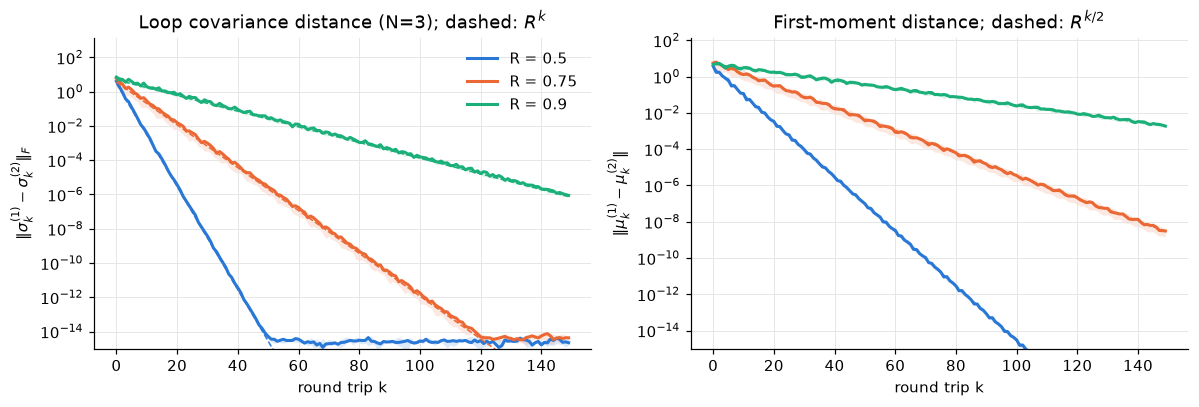

OK    [7.1] covariance contraction rate, R=0.5: expected 0.5 (rho(A)^2); observed 0.5001
OK    [7.1] first-moment contraction rate, R=0.5: expected 0.7071 (rho(A)); observed 0.7072
OK    [7.1] covariance contraction rate, R=0.75: expected 0.75 (rho(A)^2); observed 0.7500
OK    [7.1] first-moment contraction rate, R=0.75: expected 0.8660 (rho(A)); observed 0.8660
OK    [7.1] covariance contraction rate, R=0.9: expected 0.9 (rho(A)^2); observed 0.9000
OK    [7.1] first-moment contraction rate, R=0.9: expected 0.9487 (rho(A)); observed 0.9487
Two different initial states converge under identical inputs for every R tested (echo-state property).


In [12]:
TREND_CHECKS = []

def record_check(section, check, expected, observed, passed):
    TREND_CHECKS.append(dict(section=section, check=check, expected=expected, observed=observed, passed=bool(passed)))
    print(("OK    " if passed else "MISS  ") + f"[{section}] {check}: expected {expected}; observed {observed}")

def fit_rate(y, rel_floor=1e-12, k_min=3):
    """Per-step contraction rate from a log-linear fit of y_k (k >= k_min, y above round-off)."""
    k = np.arange(len(y))
    ok = (k >= k_min) & (y > rel_floor * y.max())
    fit = sst.linregress(k[ok], np.log(y[ok]))
    return float(np.exp(fit.slope)), float(np.exp(fit.slope) * fit.stderr)

def forgetting_run(N, R, net_id, steps):
    nets = networks_for(N, net_id)
    rng = np.random.default_rng(child_seed("forgetting", N, R, net_id))
    s = rng.uniform(CFG.input_low, CFG.input_high, steps)
    cov2, mean2 = random_valid_cov(N, rng, nu_max=4.0), rng.normal(0.0, 2.0, 2 * N)
    res = NativePiquassoCVReservoir(N, R, nets)
    a = res.run(s, mean0=np.zeros(2 * N), keep_loop=True)
    b = res.run(s, cov0=cov2, mean0=mean2, keep_loop=True)
    return dict(D=np.linalg.norm(a["loop_cov"] - b["loop_cov"], axis=(1, 2)),
                D_out=np.linalg.norm(a["features"] - b["features"], axis=1),
                mu=np.linalg.norm(a["loop_mean"] - b["loop_mean"], axis=1))

N_f, steps_f = CFG.N_fading, CFG.fading_steps
announce_cost("7.1 initial-state forgetting",
              {N_f: 2 * steps_f * CFG.n_networks_fading * len(CFG.R_fading)})
FORGET = {R: [forgetting_run(N_f, R, n, steps_f) for n in range(CFG.n_networks_fading)] for R in CFG.R_fading}

rows = []
for R, runs in FORGET.items():
    for q, theory in (("D", R), ("D_out", R), ("mu", np.sqrt(R))):
        rates = np.array([fit_rate(r[q])[0] for r in runs])
        rows.append(dict(R=R, quantity={"D": "loop covariance ||dsigma||_F", "D_out": "output features",
                                        "mu": "first moments ||dmu||"}[q],
                         fitted_rate=rates.mean(), sem=rates.std(ddof=1) / np.sqrt(len(rates)) if len(rates) > 1 else 0,
                         theory=theory, final_over_initial=np.median([r[q][-1] / r[q][0] for r in runs])))
FORGET_TABLE = pd.DataFrame(rows)
display(FORGET_TABLE.round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for i, R in enumerate(CFG.R_fading):
    D = np.array([r["D"] for r in FORGET[R]]); mu = np.array([r["mu"] for r in FORGET[R]])
    k = np.arange(steps_f)
    for ax, Y, rate in ((axes[0], D, R), (axes[1], mu, np.sqrt(R))):
        med = np.median(Y, 0)
        ax.fill_between(k, Y.min(0), Y.max(0), color=PALETTE[i], alpha=0.15, lw=0)
        ax.semilogy(k, med, color=PALETTE[i], label=f"R = {R}")
        ax.semilogy(k, med[3] * rate ** (k - 3.0), "--", color=PALETTE[i], lw=1)
axes[0].set(title=f"Loop covariance distance (N={N_f}); dashed: $R^k$", xlabel="round trip k",
            ylabel=r"$\|\sigma^{(1)}_k-\sigma^{(2)}_k\|_F$", ylim=(1e-15, None))
axes[1].set(title=r"First-moment distance; dashed: $R^{k/2}$", xlabel="round trip k",
            ylabel=r"$\|\mu^{(1)}_k-\mu^{(2)}_k\|$", ylim=(1e-15, None))
axes[0].legend()
fig.tight_layout(); savefig(fig, "fig7_1_initial_state_forgetting"); plt.show()

for R in CFG.R_fading:
    sub = FORGET_TABLE[FORGET_TABLE.R == R].set_index("quantity")
    rate = sub.loc["loop covariance ||dsigma||_F", "fitted_rate"]
    record_check("7.1", f"covariance contraction rate, R={R}", f"{R} (rho(A)^2)", f"{rate:.4f}", abs(rate - R) < 0.05)
    rate_mu = sub.loc["first moments ||dmu||", "fitted_rate"]
    record_check("7.1", f"first-moment contraction rate, R={R}", f"{np.sqrt(R):.4f} (rho(A))", f"{rate_mu:.4f}",
                 abs(rate_mu - np.sqrt(R)) < 0.05)
    ratio = sub.loc["loop covariance ||dsigma||_F", "final_over_initial"]
    assert ratio < 1e-4, f"initial states did not converge for R={R}: ratio {ratio:.2e}"
print("Two different initial states converge under identical inputs for every R tested (echo-state property).")

### 7.2 Input impulse response

Two input strings that differ **only** at round trip $k_0$ are compared: $s'_{k_0}=s_{k_0}\mp1$, with identical inputs
before and after. By linearity of the covariance dynamics, the feature difference at $k_0+d$ is exactly
$\gamma_d(s_{k_0})-\gamma_d(s'_{k_0})$. Its envelope must decay as $(1-R)^2R^{d-1}$. Below, Piquasso is compared with
that exact prediction, and the envelope rate is fitted.

[cost] 7.2 impulse response: ~1.8 s on this machine | Piquasso round trips: 1,548 | homodyne shot vectors: 0 | peak extra memory ~0 MB


OK    [7.2] impulse-response envelope rate, R=0.5: expected 0.5; observed 0.5001
OK    [7.2] impulse-response envelope rate, R=0.75: expected 0.75; observed 0.7503
OK    [7.2] impulse-response envelope rate, R=0.9: expected 0.9; observed 0.9011


,R,max_rel_diff_native_vs_exact,envelope_rate,theory_rate,sem
0,0.50,3.963870e-16,0.500078,0.50,0.000573
1,0.75,2.136787e-16,0.750260,0.75,0.000312
2,0.90,2.257757e-16,0.901064,0.90,0.000733


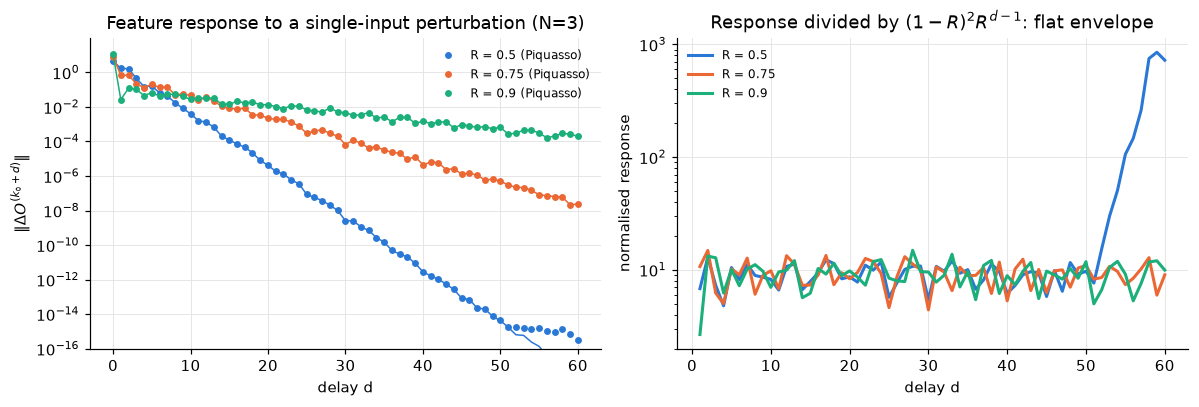

In [13]:
def impulse_run(N, R, net_id):
    k0, H = CFG.impulse_step, CFG.impulse_horizon
    nets = networks_for(N, net_id)
    s = np.random.default_rng(child_seed("impulse", N, R, net_id)).uniform(CFG.input_low, CFG.input_high, k0 + H + 1)
    s2 = s.copy()
    s2[k0] = s[k0] - np.sign(s[k0])                   # stays inside [-1, 1]
    res = NativePiquassoCVReservoir(N, R, nets)
    native = np.linalg.norm(res.run(s)["features"][k0:] - res.run(s2)["features"][k0:], axis=1)
    orc, iu = AnalyticCovarianceOracle(N, R, nets), np.triu_indices(N)
    theory = np.array([np.linalg.norm((orc.gamma(d, s[k0]) - orc.gamma(d, s2[k0]))[iu]) for d in range(H + 1)])
    return native, theory

announce_cost("7.2 impulse response", {N_f: 2 * (CFG.impulse_step + CFG.impulse_horizon + 1)
                                       * CFG.n_networks_fading * len(CFG.R_fading)})
IMPULSE = {R: [impulse_run(N_f, R, n) for n in range(CFG.n_networks_fading)] for R in CFG.R_fading}
rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for i, R in enumerate(CFG.R_fading):
    nat = np.array([a for a, _ in IMPULSE[R]]); th = np.array([b for _, b in IMPULSE[R]])
    mask = th > 1e-12 * th.max()
    rel = np.abs(nat - th)[mask].max() / th.max()
    d = np.arange(nat.shape[1])
    rate = np.array([fit_rate(x[1:], k_min=0)[0] for x in nat])
    rows.append(dict(R=R, max_rel_diff_native_vs_exact=rel, envelope_rate=rate.mean(), theory_rate=R,
                     sem=rate.std(ddof=1) / np.sqrt(len(rate)) if len(rate) > 1 else 0))
    med = np.median(nat, 0)
    axes[0].semilogy(d, med, "o", ms=3.5, color=PALETTE[i], label=f"R = {R} (Piquasso)")
    axes[0].semilogy(d, np.median(th, 0), "-", lw=1, color=PALETTE[i])
    axes[1].semilogy(d[1:], med[1:] / ((1 - R) ** 2 * R ** (d[1:] - 1.0)), color=PALETTE[i], label=f"R = {R}")
    record_check("7.2", f"impulse-response envelope rate, R={R}", f"{R}", f"{rate.mean():.4f}", abs(rate.mean() - R) < 0.05)
    assert rel < 1e-8, f"native impulse response deviates from the exact gamma_d prediction ({rel:.1e})"
IMPULSE_TABLE = pd.DataFrame(rows)
display(IMPULSE_TABLE)
axes[0].set(title=f"Feature response to a single-input perturbation (N={N_f})", xlabel="delay d",
            ylabel=r"$\|\Delta O^{(k_0+d)}\|$", ylim=(1e-16, None))
axes[0].legend(fontsize=8)
axes[1].set(title=r"Response divided by $(1-R)^2R^{d-1}$: flat envelope", xlabel="delay d",
            ylabel="normalised response")
axes[1].legend(fontsize=8)
fig.tight_layout(); savefig(fig, "fig7_2_impulse_response"); plt.show()

### 7.3 Delayed-input reconstruction (linear memory capacity)

A linear readout (Eq. A6) is trained to reconstruct $y_k=s_{k-d}$ for each delay $d$. The capacity is
$C_d=\max(0,1-{\rm NMSE}_d)$, with NMSE as in Eq. (A5), computed on an **independent** test string. Training and
testing use two separate input strings, each preceded by its own washout $R^{L_m}<10^{-16}$, with $L_m\ge d_{\max}$ so
that every delayed target exists. Inputs are i.i.d. $\mathcal U(-1,1)$.

The same runs also provide the IPC of Sections 8–9. They are cached, and in paper mode also checkpointed.

[cost] 7.3 memory vs R (cached runs are reused, so this is an upper bound): ~53.8 s on this machine | Piquasso round trips: 46,584 | homodyne shot vectors: 0 | peak extra memory ~18 MB



7.3 memory vs R:   0%|          | 0/12 [00:00<?, ?it/s]


7.3 memory vs R:  25%|██▌       | 3/12 [00:10<00:30,  3.42s/it]


7.3 memory vs R:  50%|█████     | 6/12 [00:20<00:20,  3.47s/it]


7.3 memory vs R:  75%|███████▌  | 9/12 [00:32<00:11,  3.70s/it]

...


[cost] 7.3 memory vs N (R=0.9) (cached runs are reused, so this is an upper bound): ~36.2 s on this machine | Piquasso round trips: 33,300 | homodyne shot vectors: 0 | peak extra memory ~18 MB



7.3 memory vs N (R=0.9):   0%|          | 0/9 [00:00<?, ?it/s]


7.3 memory vs N (R=0.9):  33%|███▎      | 3/9 [00:10<00:20,  3.45s/it]


7.3 memory vs N (R=0.9): 100%|██████████| 9/9 [00:23<00:00,  2.58s/it]


7.3 memory vs N (R=0.9): 100%|██████████| 9/9 [00:23<00:00,  2.66s/it]

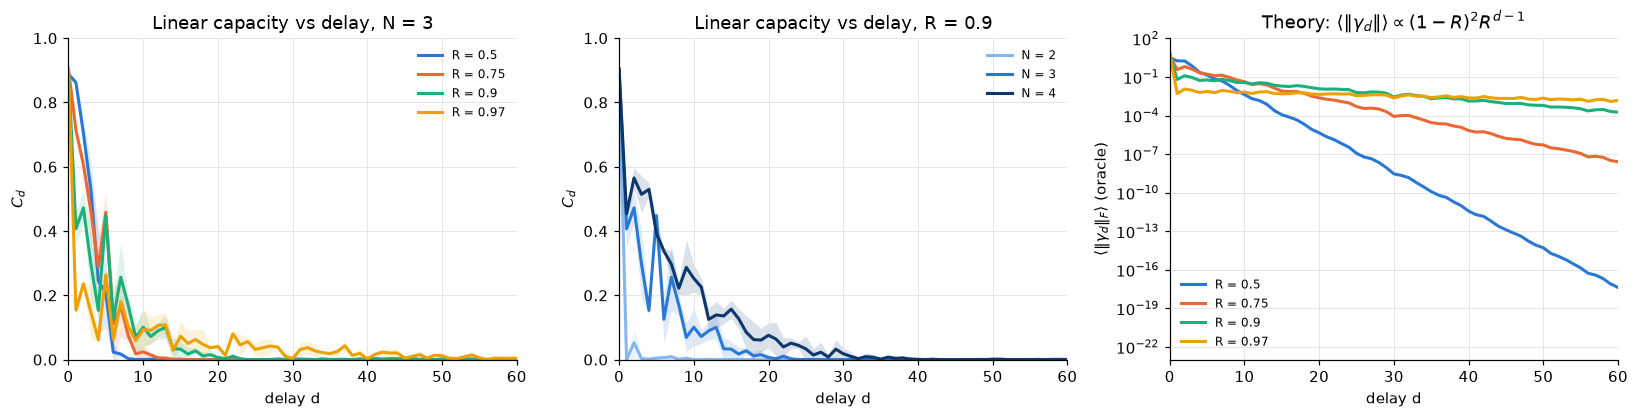

,depth_C05,tail_C005,MC,normalized_IPC,depth_C05_sem,tail_C005_sem,MC_sem,normalized_IPC_sem
R,,,,,,,,
0.50,3.031,5.862,3.548,1.012,0.149,0.178,0.056,0.009
0.75,2.827,7.575,3.865,0.995,0.244,0.846,0.043,0.009
0.90,0.821,10.630,3.844,0.936,0.066,1.412,0.015,0.025
0.97,0.541,8.380,3.745,0.902,0.015,3.091,0.291,0.047


,depth_C05,tail_C005,MC,total_IPC,normalized_IPC,depth_C05_sem,tail_C005_sem,MC_sem,total_IPC_sem,normalized_IPC_sem
N,,,,,,,,,,
2,0.441,0.944,0.995,2.017,0.672,0.005,0.000,0.048,0.011,0.004
3,0.821,10.630,3.844,5.615,0.936,0.066,1.412,0.015,0.150,0.025
4,0.900,20.028,6.340,9.455,0.946,0.036,2.915,0.245,0.207,0.021


OK    [7.3] increasing R extends memory (tail where C_d<0.05, R=0.5 -> 0.75 -> 0.9): expected increasing; observed [5.9, 7.6, 10.6]
OK    [7.3] increasing N increases linear memory capacity sum_d C_d (R=0.9): expected increasing; observed [0.99, 3.84, 6.34]
OK    [7.3] very high R weakens injected/observable signal: |gamma_1|(0.97)/|gamma_1|(0.5): expected ~((1-0.97)/(1-0.5))^2 = 0.0036; observed 0.0028


In [14]:
def ideal_capacity_run(N, R, net_id, L=None, L_test=None):
    L = CFG.L_train if L is None else L
    L_test = CFG.L_test if L_test is None else L_test

    def compute():
        nets = networks_for(N, net_id)
        res = NativePiquassoCVReservoir(N, R, nets)
        Lm = washout_length(R, CFG.washout_tol_capacity, CFG.d_max)
        lo, hi = CFG.input_low, CFG.input_high
        s_tr = np.random.default_rng(child_seed("inputs-train", N, R, net_id)).uniform(lo, hi, Lm + L)
        s_te = np.random.default_rng(child_seed("inputs-test", N, R, net_id)).uniform(lo, hi, Lm + L_test)
        F_tr, F_te = res.run(s_tr)["features"][Lm:], res.run(s_te)["features"][Lm:]
        lin = CapacityAnalyzer().linear_capacity(F_tr, s_tr, Lm, F_te, s_te, Lm)
        ipc = IPCAnalyzer(child_seed("surrogates", N, R, net_id)).capacities(F_tr, s_tr, Lm, F_te, s_te, Lm)
        check_ipc_bound(ipc, f"N={N} R={R} net={net_id}")
        return dict(N=N, R=R, net=net_id, washout=Lm, linear=lin, depth=CapacityAnalyzer.memory_depth(lin),
                    tail=CapacityAnalyzer.memory_depth(lin, 0.05), MC=float(lin.sum()), ipc=ipc)

    return checkpointed(("ideal-capacity", N, R, net_id, L, L_test), compute)

def run_ideal_grid(Ns, Rs, n_nets, label):
    jobs = [(N, R, n) for N in Ns for R in Rs for n in range(n_nets)]
    steps = {}
    for N, R, _ in jobs:
        steps[N] = steps.get(N, 0) + 2 * washout_length(R, CFG.washout_tol_capacity, CFG.d_max) + CFG.L_train + CFG.L_test
    announce_cost(label + " (cached runs are reused, so this is an upper bound)", steps,
                  memory_bytes=8 * (CFG.L_train + CFG.L_test) * (feature_dim(max(Ns)) + 2 * CFG.D_max * (CFG.d_max + 1)))
    return [ideal_capacity_run(*job) for job in tqdm(jobs, desc=label, mininterval=10, file=sys.stdout)]

def results_frame(runs):
    rows = []
    for r in runs:
        ipc = r["ipc"]
        row = dict(N=r["N"], R=r["R"], net=r["net"], washout=r["washout"], depth_C05=r["depth"], tail_C005=r["tail"],
                   MC=r["MC"], total_IPC=ipc["total"], D_out=ipc["D_out"], normalized_IPC=ipc["normalized"],
                   threshold=ipc["threshold"], rank=ipc["rank"], IPC_per_rank=ipc["per_rank"])
        for D, name in enumerate(["linear", "quadratic", "cubic", "quartic", "quintic"][:CFG.D_max]):
            row[name] = ipc["by_degree"][D]
        rows.append(row)
    return pd.DataFrame(rows)

def mean_sem(df, by, cols):
    g = df.groupby(by)[cols]
    return g.mean().join(g.sem().fillna(0.0), rsuffix="_sem")

MEM_RUNS = run_ideal_grid([CFG.N_mem], CFG.R_mem, CFG.n_networks_mem, "7.3 memory vs R")
NSWEEP_RUNS = run_ideal_grid(CFG.N_ipc, [0.9], CFG.n_networks, "7.3 memory vs N (R=0.9)")
MEM_DF, NSWEEP_DF = results_frame(MEM_RUNS), results_frame(NSWEEP_RUNS)

# theory panel: average magnitude of the delayed terms gamma_d (oracle; averaged over networks and inputs)
d_axis = np.arange(0, CFG.d_max + 1)
GAMMA_MAG = {}
for R in CFG.R_mem:
    acc = []
    for n in range(CFG.n_networks_mem):
        orc = AnalyticCovarianceOracle(CFG.N_mem, R, networks_for(CFG.N_mem, n))
        s_draw = np.random.default_rng(child_seed("gamma-mag", R, n)).uniform(-1, 1, 20)
        acc.append([np.mean([np.linalg.norm(orc.gamma(d, s)) for s in s_draw]) for d in d_axis])
    GAMMA_MAG[R] = np.mean(acc, 0)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for i, R in enumerate(CFG.R_mem):
    C = np.array([r["linear"] for r in MEM_RUNS if r["R"] == R])
    axes[0].plot(d_axis, C.mean(0), color=PALETTE[i], label=f"R = {R}")
    axes[0].fill_between(d_axis, C.mean(0) - C.std(0), C.mean(0) + C.std(0), color=PALETTE[i], alpha=0.15, lw=0)
    axes[2].semilogy(d_axis, GAMMA_MAG[R], color=PALETTE[i], label=f"R = {R}")
for j, N in enumerate(CFG.N_ipc):
    C = np.array([r["linear"] for r in NSWEEP_RUNS if r["N"] == N])
    col = ramp(len(CFG.N_ipc))[j]
    axes[1].plot(d_axis, C.mean(0), color=col, label=f"N = {N}")
    axes[1].fill_between(d_axis, C.mean(0) - C.std(0), C.mean(0) + C.std(0), color=col, alpha=0.15, lw=0)
axes[0].set(title=f"Linear capacity vs delay, N = {CFG.N_mem}", xlabel="delay d", ylabel="$C_d$", xlim=(0, 60), ylim=(0, 1))
axes[1].set(title="Linear capacity vs delay, R = 0.9", xlabel="delay d", ylabel="$C_d$", xlim=(0, 60), ylim=(0, 1))
axes[2].set(title=r"Theory: $\langle\|\gamma_d\|\rangle\propto(1-R)^2R^{d-1}$", xlabel="delay d",
            ylabel=r"$\langle\|\gamma_d\|_F\rangle$ (oracle)", xlim=(0, 60))
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "fig7_3_linear_memory"); plt.show()

mem_summary = mean_sem(MEM_DF, "R", ["depth_C05", "tail_C005", "MC", "normalized_IPC"])
n_summary = mean_sem(NSWEEP_DF, "N", ["depth_C05", "tail_C005", "MC", "total_IPC", "normalized_IPC"])
display(mem_summary.round(3)); display(n_summary.round(3))

tails = mem_summary["tail_C005"].loc[[0.5, 0.75, 0.9]].values
record_check("7.3", "increasing R extends memory (tail where C_d<0.05, R=0.5 -> 0.75 -> 0.9)", "increasing",
             np.round(tails, 1).tolist(), np.all(np.diff(tails) > 0))
mcs = n_summary["MC"].values
record_check("7.3", "increasing N increases linear memory capacity sum_d C_d (R=0.9)", "increasing",
             np.round(mcs, 2).tolist(), np.all(np.diff(mcs) > 0))
g1 = {R: GAMMA_MAG[R][1] for R in CFG.R_mem}
record_check("7.3", "very high R weakens injected/observable signal: |gamma_1|(0.97)/|gamma_1|(0.5)",
             f"~((1-0.97)/(1-0.5))^2 = {(0.03 / 0.5) ** 2:.4f}", f"{g1[0.97] / g1[0.5]:.4f}",
             g1[0.97] / g1[0.5] < 0.05)

## 8. Information-processing capacity

**Definition (App. B).** For every target $\bar y$ the capacity is
$C_{\bar y}=\max\left[0,1-\min_{\mathbf W}{\rm NMSE}_{L'}(\mathbf y,\bar{\mathbf y})\right]$, where the readout is trained
on $L$ steps and evaluated on $L'$ independent test steps. The IPC is ${\rm IPC}=\sum_{\bar y}C_{\bar y}$ over the
orthogonal family
$$
\bar y^{(d)}_D(s_k)=\mathcal P_D(s_{k-d}),\qquad d=0,\ldots,d_{\max}=75,\quad D=1,\ldots,D_{\max}=5,
$$
where $\mathcal P_D$ is the *normalised* Legendre polynomial. The ranges $d_{\max}=75$ and $D_{\max}=5$ are stated
explicitly in App. B. The paper does not state the input distribution. The Legendre family is orthogonal for
$s\sim\mathcal U(-1,1)$, so that distribution is used, with $\mathcal P_D=\sqrt{2D+1}\,P_D$ (unit second moment; test 18).
The paper uses only single-delay terms. This is consistent with Eq. (4): the ideal covariance is a *sum* of functions
of single delayed inputs, so cross-delay products carry no capacity.

**Safeguards against false-positive capacity.**
1. Every capacity is measured on an independent test string, never on the training data.
2. The readout is simultaneously asked to reproduce $5\times20$ *surrogate* targets $\mathcal P_D(u_k)$, where $u$ is an
   independent uniform string with zero true capacity. The largest surrogate capacity $\theta$ is used as a threshold,
   and capacities $\le\theta$ are set to zero.
3. The total must satisfy ${\rm IPC}\le N(N+1)/2+\tau$. The tolerance
   $\tau=3\sqrt{2n_{\rm kept}/L'}+n_{\rm kept}\bar C_{\rm sur}$ reflects the finite-$L'$ fluctuation of the $n_{\rm kept}$
   retained terms and the mean surrogate bias. `check_ipc_bound` asserts this for every run.

The normalised IPC is ${\rm IPC}/[N(N+1)/2]$; the paper finds it saturates at $\simeq1$ (Fig. 2b).

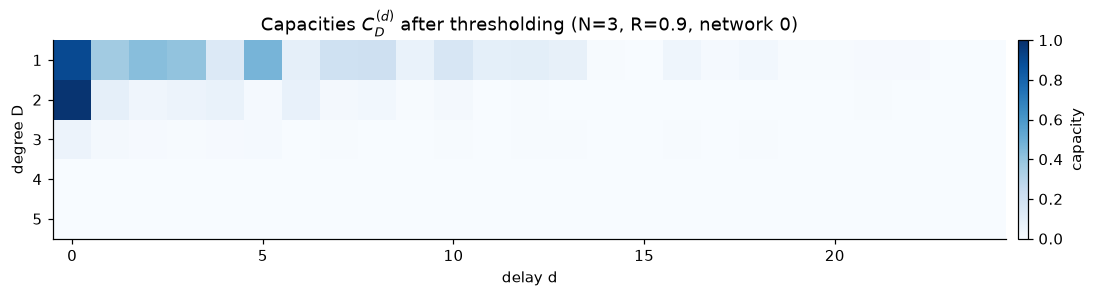

,"N=3, R=0.9"
linear capacity,3.8301
quadratic capacity,1.4071
cubic capacity,0.1455
quartic capacity,0.0000
quintic capacity,0.0000
total IPC,5.3827
N(N+1)/2,6.0000
normalised IPC,0.8971
surrogate threshold,0.0047
terms kept,47.0000


IPC <= N(N+1)/2 (within the statistical tolerance) holds for every ideal run computed so far.


In [15]:
rep = ideal_capacity_run(CFG.N_mem, 0.9, 0)
ipc = rep["ipc"]
last = max(int(np.flatnonzero(ipc["C"].sum(0) > 0).max()) + 3, 10)
fig, ax = plt.subplots(figsize=(11, 2.8))
im = ax.imshow(ipc["C"][:, :last], aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest",
               extent=(-0.5, last - 0.5, CFG.D_max + 0.5, 0.5))
ax.set(xlabel="delay d", ylabel="degree D", yticks=range(1, CFG.D_max + 1),
       title=f"Capacities $C_D^{{(d)}}$ after thresholding (N={CFG.N_mem}, R=0.9, network 0)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="capacity", pad=0.01)
fig.tight_layout(); savefig(fig, "fig8_ipc_heatmap"); plt.show()

names = ["linear", "quadratic", "cubic", "quartic", "quintic"]
display(pd.DataFrame({
    **{f"{n} capacity": [ipc["by_degree"][i]] for i, n in enumerate(names[:CFG.D_max])},
    "total IPC": [ipc["total"]], "N(N+1)/2": [ipc["D_out"]], "normalised IPC": [ipc["normalized"]],
    "surrogate threshold": [ipc["threshold"]], "terms kept": [ipc["n_kept"]], "bound tolerance": [ipc["bound_tolerance"]],
}).T.rename(columns={0: f"N={CFG.N_mem}, R=0.9"}).round(4))
for key, value in _MEMO.items():
    if key[0] == "ideal-capacity":
        check_ipc_bound(value["ipc"], str(key))
print("IPC <= N(N+1)/2 (within the statistical tolerance) holds for every ideal run computed so far.")

## 9. Ideal paper reproduction ($M\to\infty$)

This section reproduces Fig. 2: linear capacity versus delay for the two largest $N$ at $R=0.75$ and $R=0.9$, the
degree-resolved IPC versus $N$ for $R=0.9$, and the total and normalised IPC for both reflectivities. Every point is
averaged over `n_networks` independent network pairs and input strings. The paper uses 100 (Fig. 2 caption, checked);
the active mode uses the value printed in the configuration table. The paper's panel (b) mixes two y-scales; here total
and normalised IPC are drawn in separate panels.

**Note on $N=2$ (smoke mode only).** With a single coupling pair, $\omega_1=\omega_2$, identical ancilla modes and a
vacuum start, the whole model is symmetric under exchanging the two modes. Hence $\sigma_{11}=\sigma_{22}$ at every
round trip, only two observables are independent, and the normalised IPC is capped at $2/3$. This is a structural
property of the paper's model at $N=2$, not a numerical failure; the paper starts at $N=4$. The table therefore also
reports `IPC_per_rank`, the IPC divided by the number of numerically independent observables.

[cost] 9 ideal IPC grid (cached runs are reused, so this is an upper bound): ~1.1 min on this machine | Piquasso round trips: 62,622 | homodyne shot vectors: 0 | peak extra memory ~18 MB



9 ideal IPC grid:   0%|          | 0/18 [00:00<?, ?it/s]


9 ideal IPC grid:  72%|███████▏  | 13/18 [00:12<00:04,  1.00it/s]


9 ideal IPC grid: 100%|██████████| 18/18 [00:20<00:00,  1.17s/it]

linear  quadratic  cubic  quartic  quintic  total_IPC  normalized_IPC  \
N R                                                                             
2 0.75   1.293      0.561  0.109    0.008    0.002      1.974           0.658   
  0.90   0.978      0.898  0.113    0.019    0.008      2.017           0.672   
3 0.75   3.845      1.754  0.346    0.023    0.000      5.969           0.995   
  0.90   3.817      1.577  0.217    0.004    0.000      5.615           0.936   
4 0.75   6.114      3.084  0.640    0.068    0.008      9.914           0.991   
  0.90   6.326      2.504  0.571    0.051    0.004      9.455           0.946   

        IPC_per_rank  rank  depth_C05  ...  cubic_sem  quartic_sem  \
N R                                    ...                           
2 0.75         0.987   2.0      0.417  ...      0.004        0.001   
  0.90         1.008   2.0      0.441  ...      0.007        0.009   
3 0.75         0.995   6.0      2.827  ...      0.057        0.007   
  0.90         0.936   6.0      0.821  ...      0.087        0.004   
4 0.75         0.991  10.0      5.702  ...      0.137        0.007   
  0.90         0.946  10.0      0.900  ...      0.107        0.027   

        quintic_sem  total_IPC_sem  normalized_IPC_sem  IPC_per_rank_sem  \
N R                                                                        
2 0.75        0.002          0.023               0.008             0.012   
  0.90        0.006          0.011               0.004             0.005   
3 0.75        0.000          0.055               0.009             0.009   
  0.90        0.000          0.150               0.025             0.025   
4 0.75        0.006          0.318               0.032             0.032   
  0.90        0.002          0.207               0.021             0.021   

        rank_sem  depth_C05_sem  MC_sem  D_out  
N R                                             
2 0.75       0.0          0.019   0.066      3  
  0.90       0.0          0.005   0.048      3  
3 0.75       0.0          0.244   0.043      6  
  0.90       0.0          0.066   0.015      6  
4 0.75       0.0          0.318   0.206     10  
  0.90       0.0          0.036   0.245     10  

[6 rows x 23 columns]

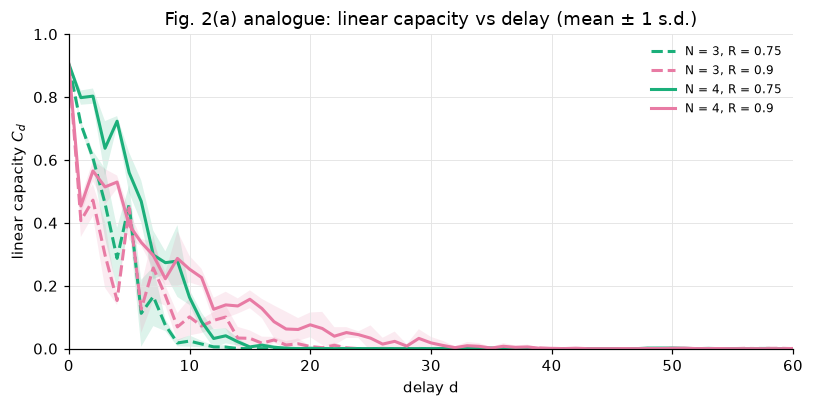

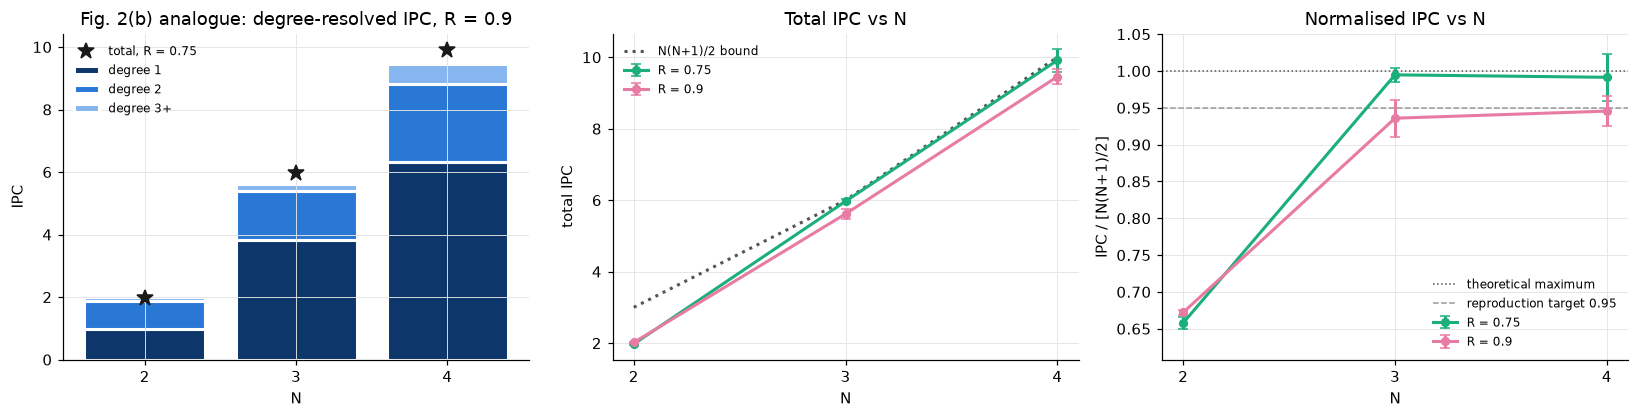

N=2 exchange symmetry: max |P S P^T - S| = 3.3e-16; max |sigma_11 - sigma_22| = 5.3e-15 -> only 2 of 3 observables are independent (IPC/[N(N+1)/2] <= 2/3).
OK    [9] normalised ideal IPC >= 0.95 target, N=3, R=0.75: expected >= 0.95; observed 0.995 ± 0.009
MISS  [9] normalised ideal IPC >= 0.95 target, N=3, R=0.9: expected >= 0.95; observed 0.936 ± 0.025
OK    [9] normalised ideal IPC >= 0.95 target, N=4, R=0.75: expected >= 0.95; observed 0.991 ± 0.032
MISS  [9] normalised ideal IPC >= 0.95 target, N=4, R=0.9: expected >= 0.95; observed 0.946 ± 0.021


,degree-1 fraction,degree-2 fraction,degree-3+ fraction
N,,,
2,0.485,0.445,0.070
3,0.680,0.281,0.039
4,0.669,0.265,0.066


In [16]:
IDEAL_RUNS = run_ideal_grid(CFG.N_ipc, CFG.R_ipc, CFG.n_networks, "9 ideal IPC grid")
IDEAL_DF = results_frame(IDEAL_RUNS)
deg_cols = ["linear", "quadratic", "cubic", "quartic", "quintic"][:CFG.D_max]
IDEAL_SUMMARY = mean_sem(IDEAL_DF, ["N", "R"], deg_cols + ["total_IPC", "normalized_IPC", "IPC_per_rank", "rank",
                                                           "depth_C05", "MC"])
IDEAL_SUMMARY["D_out"] = [feature_dim(N) for N, _ in IDEAL_SUMMARY.index]
display(IDEAL_SUMMARY.round(3))
if SAVE_RESULTS:
    IDEAL_DF.to_csv(RESULTS_DIR / "ideal_runs.csv", index=False)

cols_R = {0.75: PALETTE[2], 0.9: PALETTE[4]}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for N, ls in zip(sorted(CFG.N_ipc)[-2:], ("--", "-")):
    for R in CFG.R_ipc:
        C = np.array([r["linear"] for r in IDEAL_RUNS if r["N"] == N and r["R"] == R])
        ax.plot(d_axis, C.mean(0), ls, color=cols_R[R], label=f"N = {N}, R = {R}")
        ax.fill_between(d_axis, C.mean(0) - C.std(0), C.mean(0) + C.std(0), color=cols_R[R], alpha=0.15, lw=0)
ax.set(xlabel="delay d", ylabel="linear capacity $C_d$", xlim=(0, 60), ylim=(0, 1),
       title="Fig. 2(a) analogue: linear capacity vs delay (mean ± 1 s.d.)")
ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "fig9a_linear_capacity"); plt.show()

Ns = sorted(CFG.N_ipc)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
S9 = IDEAL_SUMMARY.xs(0.9, level="R")
bottom = np.zeros(len(Ns))
groups = [("degree 1", ["linear"]), ("degree 2", ["quadratic"]), ("degree 3+", deg_cols[2:])]
for (label, cols), col in zip(groups, ramp(3)[::-1]):
    h = S9[cols].sum(axis=1).values
    axes[0].bar(Ns, h, bottom=bottom, color=col, edgecolor="white", linewidth=2, label=label, width=0.8)
    bottom += h
S75 = IDEAL_SUMMARY.xs(0.75, level="R") if 0.75 in CFG.R_ipc else None
if S75 is not None:
    axes[0].plot(Ns, S75["total_IPC"].values, "*", ms=11, color="#1a1a19", label="total, R = 0.75")
axes[0].set(xlabel="N", ylabel="IPC", title="Fig. 2(b) analogue: degree-resolved IPC, R = 0.9", xticks=Ns)
axes[0].legend(fontsize=8)
for R in CFG.R_ipc:
    S = IDEAL_SUMMARY.xs(R, level="R")
    axes[1].errorbar(Ns, S["total_IPC"], yerr=S["total_IPC_sem"], marker="o", color=cols_R[R], label=f"R = {R}", capsize=3)
    axes[2].errorbar(Ns, S["normalized_IPC"], yerr=S["normalized_IPC_sem"], marker="o", color=cols_R[R], label=f"R = {R}",
                     capsize=3)
axes[1].plot(Ns, [feature_dim(N) for N in Ns], ":", color="#555", label="N(N+1)/2 bound")
axes[1].set(xlabel="N", ylabel="total IPC", title="Total IPC vs N", xticks=Ns)
axes[2].axhline(1.0, ls=":", color="#555", lw=1, label="theoretical maximum")
axes[2].axhline(0.95, ls="--", color="#999", lw=1, label="reproduction target 0.95")
axes[2].set(xlabel="N", ylabel="IPC / [N(N+1)/2]", title="Normalised IPC vs N", xticks=Ns,
            ylim=(min(0.8, IDEAL_SUMMARY["normalized_IPC"].min() - 0.05), 1.05))
for ax in axes[1:]:
    ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "fig9b_ipc_vs_N"); plt.show()

if 2 in CFG.N_ipc:
    nets2 = networks_for(2, 0)
    F2 = NativePiquassoCVReservoir(2, 0.75, nets2).run(
        np.random.default_rng(child_seed("n2-symmetry")).uniform(-1, 1, 50))["features"]
    P = np.array([[0, 0, 1, 0], [0, 0, 0, 1], [1, 0, 0, 0], [0, 1, 0, 0]], float)   # xpxp exchange of modes 1 <-> 2
    sym = max(np.abs(P @ n["S"] @ P.T - n["S"]).max() for n in nets2)
    print(f"N=2 exchange symmetry: max |P S P^T - S| = {sym:.1e}; max |sigma_11 - sigma_22| = "
          f"{np.abs(F2[:, 0] - F2[:, 2]).max():.1e} -> only 2 of 3 observables are independent (IPC/[N(N+1)/2] <= 2/3).")
    assert sym < 1e-12 and np.abs(F2[:, 0] - F2[:, 2]).max() < 1e-10
for (N, R), row in IDEAL_SUMMARY.iterrows():
    if N == 2:
        continue                    # structural ceiling 2/3 (exchange symmetry), see the note above
    record_check("9", f"normalised ideal IPC >= 0.95 target, N={N}, R={R}", ">= 0.95",
                 f"{row['normalized_IPC']:.3f} ± {row['normalized_IPC_sem']:.3f}", row["normalized_IPC"] >= 0.95)
fr = (S9[deg_cols].div(S9["total_IPC"], axis=0))
display(pd.DataFrame({"degree-1 fraction": fr["linear"], "degree-2 fraction": fr["quadratic"],
                      "degree-3+ fraction": fr[deg_cols[2:]].sum(axis=1)}).round(3))

## 10. Finite homodyne ensemble

### 10.1 Estimator and native sampling

At every round trip $k$, the $M$ pulses of the physical ensemble are measured with homodyne detection of all $x$
quadratures. The paper's estimator (Sec. II) is
$$
\widehat O^{(k)}_{ij}=\frac1M\sum_{m=1}^{M}X^{(k,m)}_iX^{(k,m)}_j-\bar X^{(k)}_i\bar X^{(k)}_j .
$$
Shots are drawn in bounded-memory chunks of at most `shot_chunk` pulses and merged with the Chan–Golub–LeVeque update.
For chunks $a,b$ with sizes $n_a,n_b$, means $\bar x_a,\bar x_b$ and co-moment matrices $M_{2,a},M_{2,b}$:
$$
\bar x=\bar x_a+\delta\,\tfrac{n_b}{n},\qquad M_2=M_{2,a}+M_{2,b}+\delta\delta^T\tfrac{n_an_b}{n},\qquad\delta=\bar x_b-\bar x_a,\ n=n_a+n_b .
$$
This is algebraically identical to the one-batch estimator and numerically stable (test 16). Raw fourth-order sums,
needed for Santa Fe, are additive and therefore also exact under chunking. Estimates for several ensemble sizes
$M_1<M_2<\dots$ are *nested*: each one uses the first $M_j$ pulses of a single stream, just as a larger physical
ensemble contains a smaller one.

**Who generates the samples.** Every outcome is produced by Piquasso from the Piquasso output state:
* `sampler="public"` executes `pq.HomodyneMeasurement` through `GaussianSimulator.execute(program, shots=m)`. Piquasso
  8.0.1 builds one post-measurement Gaussian state per shot on this path, which costs about 0.3–0.4 ms per shot.
* `sampler="kernel"` calls the routine that `HomodyneMeasurement` itself dispatches to
  (`_get_generaldyne_samples`: the same state, detector covariance ${\rm diag}(z^2,z^{-2})$ and random generator). It
  only skips the per-shot post-measurement states, which this protocol never uses because the reservoir state is
  unconditional. Test 15 shows that both paths return the same outcomes. This is **not** NumPy sampling from our own
  covariance.

The public path is used for the headline $M^{-1/2}$ law below and for every validation test. The kernel is used for
the long sequences, where the public path would need weeks (see the timings printed below). NumPy
multivariate-normal sampling from a covariance we construct ourselves is never used.

In [17]:
# Piquasso's sampler calls numpy's multivariate_normal with tol=1e-7 on a covariance whose p-port entries are
# 1/z^2 = 1e8 (the z -> 0 homodyne limit). Round-off at that scale trips numpy's PSD self-check although the matrix
# is PSD; the resulting samples are verified statistically (tests 01, 15, Sec. 10.2 and 12.2). The warning is muted.
warnings.filterwarnings("ignore", message="covariance is not symmetric positive-semidefinite")

if ENABLE_FINITE_SHOTS:
    _cov = np.eye(2 * CFG.N_fs)
    for smp, m in (("public", 400), ("kernel", 100000)):
        est = FiniteShotEstimator(CFG.N_fs, seed=child_seed("throughput", smp), sampler=smp)
        est.sample(_cov, 10)
        t0 = time.perf_counter(); est.sample(_cov, m); dt = time.perf_counter() - t0
        print(f"{smp:>6} Piquasso homodyne sampling, N={CFG.N_fs}: {dt / m * 1e6:8.2f} us per shot vector")
else:
    print("ENABLE_FINITE_SHOTS = False: Sections 10-11 and the finite-M part of Section 12 are skipped.")

public Piquasso homodyne sampling, N=4:   257.01 us per shot vector
kernel Piquasso homodyne sampling, N=4:     0.12 us per shot vector


### 10.2 Statistical error $\propto M^{-1/2}$

The output state of a washed-out reservoir ($N=N_{\rm fs}$, $R=0.9$) is sampled repeatedly, using nested ensembles
within each repetition, and the error $\|\widehat O-\sigma_{xx}\|_F$ is recorded. For Gaussian data the Wishart
distribution predicts ${\rm RMS}=\sqrt{\sum_{ij}(\sigma_{ii}\sigma_{jj}+\sigma_{ij}^2)/M}$ to leading order. The exponent
is fitted by least squares on $\log$ error versus $\log M$ separately for each repetition. The estimates for different
$M$ within one repetition share pulses (nested ensembles), so the independent units are the repetitions: we report the
mean slope with a Student-$t$ 95% confidence interval over repetitions. The paper's Eq. (6) text says "${\rm Var}(\xi_M)\propto M^{-1/2}$"; its App. G (Eq. G2) uses the
standard deviation $\propto M^{-1/2}$, and that is the statement tested here.

[cost] 10.2 M^-1/2 scaling (public sampler): ~8.8 s on this machine | Piquasso round trips: 0 | homodyne shot vectors: 36,000 | peak extra memory ~6 MB



public sampler:   0%|          | 0/12 [00:00<?, ?it/s]


public sampler: 100%|██████████| 12/12 [00:09<00:00,  1.33it/s]


[cost] 10.2 M^-1/2 scaling (kernel sampler): ~2.0 s on this machine | Piquasso round trips: 0 | homodyne shot vectors: 12,000,000 | peak extra memory ~6 MB



kernel sampler:   0%|          | 0/12 [00:00<?, ?it/s]


kernel sampler: 100%|██████████| 12/12 [00:01<00:00,  7.12it/s]

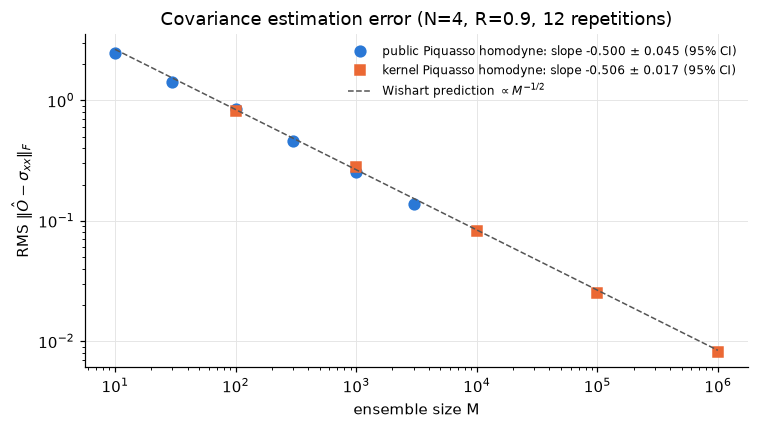

,slope,ci95_half_width,M_range
public,-0.50031,0.045052,10..3000
kernel,-0.50634,0.016859,100..1000000


OK    [10.2] finite-shot error exponent (public sampler): expected -0.5 ± 0.1; observed -0.500 ± 0.045
OK    [10.2] finite-shot error exponent (kernel sampler): expected -0.5 ± 0.1; observed -0.506 ± 0.017


In [18]:
def fit_loglog(M_values, errors):
    """Exponent of error ~ M^a. Estimates for different M within one repetition share pulses (nested ensembles), so
    one slope is fitted per independent repetition and the CI is a Student-t interval over repetitions."""
    slopes = np.array([np.polyfit(np.log(M_values), np.log(e), 1)[0] for e in np.asarray(errors)])
    se = slopes.std(ddof=1) / np.sqrt(len(slopes))
    return slopes.mean(), sst.t.ppf(0.975, len(slopes) - 1) * se, se

SCALING = {}
if ENABLE_FINITE_SHOTS:
    N_s = CFG.N_fs
    res_s = NativePiquassoCVReservoir(N_s, 0.9, networks_for(N_s, 0))
    Lm_s = washout_length(0.9, CFG.washout_tol_capacity)
    cov_out = res_s.run(np.random.default_rng(child_seed("scaling-inputs")).uniform(-1, 1, Lm_s + 1),
                        keep_output=True)["output_cov"][-1]
    Sx = x_block(cov_out)
    wishart = lambda M: np.sqrt((np.outer(np.diag(Sx), np.diag(Sx)) + Sx ** 2).sum() / np.asarray(M, float))
    old_sampler = CFG["homodyne_sampler"]
    for smp, Ms in (("public", CFG.M_public), ("kernel", CFG.M_kernel)):
        CFG["homodyne_sampler"] = smp
        announce_cost(f"10.2 M^-1/2 scaling ({smp} sampler)", {}, {N_s: CFG.n_rep_scaling * max(Ms)})
        errs = []
        for rep in tqdm(range(CFG.n_rep_scaling), desc=f"{smp} sampler", mininterval=10, file=sys.stdout):
            snaps = FiniteShotEstimator(N_s, seed=child_seed("M-scaling", smp, rep), sampler=smp).estimate(cov_out, Ms)
            errs.append([np.linalg.norm(snaps[M]["cov"] - Sx) for M in Ms])
        slope, half, se = fit_loglog(Ms, errs)
        SCALING[smp] = dict(M=np.array(Ms), errors=np.array(errs), slope=slope, ci95=half, se=se)
    CFG["homodyne_sampler"] = old_sampler

    fig, ax = plt.subplots(figsize=(7, 4))
    for i, (smp, d) in enumerate(SCALING.items()):
        rms = np.sqrt((d["errors"] ** 2).mean(0))
        ax.loglog(d["M"], rms, "o" if smp == "public" else "s", color=PALETTE[i], ms=7,
                  label=f"{smp} Piquasso homodyne: slope {d['slope']:.3f} ± {d['ci95']:.3f} (95% CI)")
    Mgrid = np.logspace(1, np.log10(max(CFG.M_kernel)), 50)
    ax.loglog(Mgrid, wishart(Mgrid), "--", color="#555", lw=1, label=r"Wishart prediction $\propto M^{-1/2}$")
    ax.set(xlabel="ensemble size M", ylabel=r"RMS $\|\hat O-\sigma_{xx}\|_F$",
           title=f"Covariance estimation error (N={N_s}, R=0.9, {CFG.n_rep_scaling} repetitions)")
    ax.legend(fontsize=8)
    fig.tight_layout(); savefig(fig, "fig10_2_M_scaling"); plt.show()
    display(pd.DataFrame({smp: dict(slope=d["slope"], ci95_half_width=d["ci95"], M_range=f"{d['M'][0]}..{d['M'][-1]}")
                          for smp, d in SCALING.items()}).T)
    for smp, d in SCALING.items():
        record_check("10.2", f"finite-shot error exponent ({smp} sampler)", "-0.5 ± 0.1",
                     f"{d['slope']:.3f} ± {d['ci95']:.3f}", abs(d["slope"] + 0.5) <= 0.1)

### 10.3 Linear capacity with finite ensembles (Fig. 3a) and SNR analysis (Figs. 3b–c)

For each network the ideal output covariances are computed by Piquasso along independent training and test strings.
At every round trip, one nested stream of $\max(M)$ Piquasso homodyne shots then gives the estimated features for
every $M$ in the list. Training and testing both use estimated features, as in the paper.

**SNR.** On the first `snr_steps` test round trips, the noise is $\xi_M=\widehat O-O_{\rm ideal}$ and the delayed
contributions $\gamma_d$ come from the oracle decomposition. We report
${\rm SNR}_d=10\log_{10}\big(\langle|\gamma_d|\rangle/\langle|\xi_M|\rangle\big)$, the ratio of mean element magnitudes,
averaged over steps and networks. The paper averages the element-wise ratio $\langle|\gamma_d/\xi_M|\rangle$. That
quantity has no finite mean for Gaussian $\xi$, because $1/\xi$ is heavy-tailed, so the ratio of means is the stable
choice. It gives the same slope ($10\log_{10}R$ per delay, Eq. G7) and the same shifts (Eqs. G9–G10).

In [19]:
RESOLVE_LEVEL = 0.1   # "resolvable delay": last delay with C_d >= 0.1 (tracks the noise floor of Eq. 7)

def finite_shot_run(N, R, net_id):
    L, L_test, Ms = CFG.L_train_fs, CFG.L_test_fs, sorted(CFG.M_fs)

    def compute():
        nets = networks_for(N, net_id)
        res, iu = NativePiquassoCVReservoir(N, R, nets), np.triu_indices(N)
        Lm = washout_length(R, CFG.washout_tol_capacity, CFG.d_max)
        strings, feats = {}, {}
        for part, length in (("train", L), ("test", L_test)):
            s = np.random.default_rng(child_seed("fs-inputs", part, N, R, net_id)).uniform(
                CFG.input_low, CFG.input_high, Lm + length)
            run = res.run(s, keep_output=True)
            est = FiniteShotEstimator(N, seed=child_seed("fs-shots", part, N, R, net_id))
            F = {M: np.empty((length, feature_dim(N))) for M in Ms}
            for k, cov in enumerate(run["output_cov"][Lm:]):
                for M, snap in est.estimate(cov, Ms).items():
                    F[M][k] = snap["cov"][iu]
            F["ideal"] = run["features"][Lm:]
            strings[part], feats[part] = s, F
        out = dict(N=N, R=R, net=net_id, linear={}, depth={}, resolve={}, ipc={})
        for key in Ms + ["ideal"]:
            args = (feats["train"][key], strings["train"], Lm, feats["test"][key], strings["test"], Lm)
            lin = CapacityAnalyzer().linear_capacity(*args)
            ipc = IPCAnalyzer(child_seed("fs-surrogates", N, R, net_id, key)).capacities(*args)
            out["linear"][key], out["depth"][key] = lin, CapacityAnalyzer.memory_depth(lin)
            out["resolve"][key] = CapacityAnalyzer.memory_depth(lin, RESOLVE_LEVEL)
            out["ipc"][key] = {k: ipc[k] for k in ("total", "normalized", "by_degree", "D_out")}
        n_snr = min(CFG.snr_steps, L_test)
        orc, s_te = AnalyticCovarianceOracle(N, R, nets), strings["test"]
        out["gamma_mean"] = np.array([np.mean([np.abs(orc.gamma(d, s_te[Lm + k - d])[iu]).mean() for k in range(n_snr)])
                                      for d in range(1, CFG.snr_d_max + 1)])
        out["xi_mean"] = {M: float(np.abs(feats["test"][M][:n_snr] - feats["test"]["ideal"][:n_snr]).mean()) for M in Ms}
        return out

    return checkpointed(("finite-shot", N, R, net_id, L, L_test, tuple(Ms)), compute)

FS_RUNS = []
if ENABLE_FINITE_SHOTS:
    N_fs = CFG.N_fs
    jobs = [(N_fs, R, n) for R in CFG.R_fs for n in range(CFG.n_networks_fs)]
    steps = sum(2 * washout_length(R, CFG.washout_tol_capacity, CFG.d_max) + CFG.L_train_fs + CFG.L_test_fs
                for _, R, _ in jobs)
    shots = len(jobs) * (CFG.L_train_fs + CFG.L_test_fs) * max(CFG.M_fs)
    calls = len(jobs) * (CFG.L_train_fs + CFG.L_test_fs) * (len(CFG.M_fs) + max(CFG.M_fs) // CFG.shot_chunk)
    announce_cost("10.3 finite-shot memory (Fig. 3)", {N_fs: steps}, {N_fs: shots}, {N_fs: calls},
                  memory_bytes=8 * (len(CFG.M_fs) + 1) * (CFG.L_train_fs + CFG.L_test_fs) * feature_dim(N_fs))
    FS_RUNS = [finite_shot_run(*job) for job in tqdm(jobs, desc="10.3 finite shots", mininterval=10, file=sys.stdout)]

[cost] 10.3 finite-shot memory (Fig. 3): ~1.0 min on this machine | Piquasso round trips: 9,916 | homodyne shot vectors: 240,000,000 | peak extra memory ~7 MB



10.3 finite shots:   0%|          | 0/4 [00:00<?, ?it/s]


10.3 finite shots:  25%|██▌       | 1/4 [00:14<00:42, 14.26s/it]


10.3 finite shots:  50%|█████     | 2/4 [00:28<00:28, 14.31s/it]


10.3 finite shots:  75%|███████▌  | 3/4 [00:42<00:14, 14.09s/it]


10.3 finite shots: 100%|██████████| 4/4 [00:56<00:00, 14.00s/it]


10.3 finite shots: 100%|██████████| 4/4 [00:56<00:00, 14.08s/it]

OK    [10.3] larger M resolves longer delays (R=0.9): expected d(C=0.1) increasing in M; observed [0.89, 0.9, 0.95]
OK    [10.3] larger M resolves longer delays (R=0.75): expected d(C=0.1) increasing in M; observed [0.91, 4.31, 7.03]


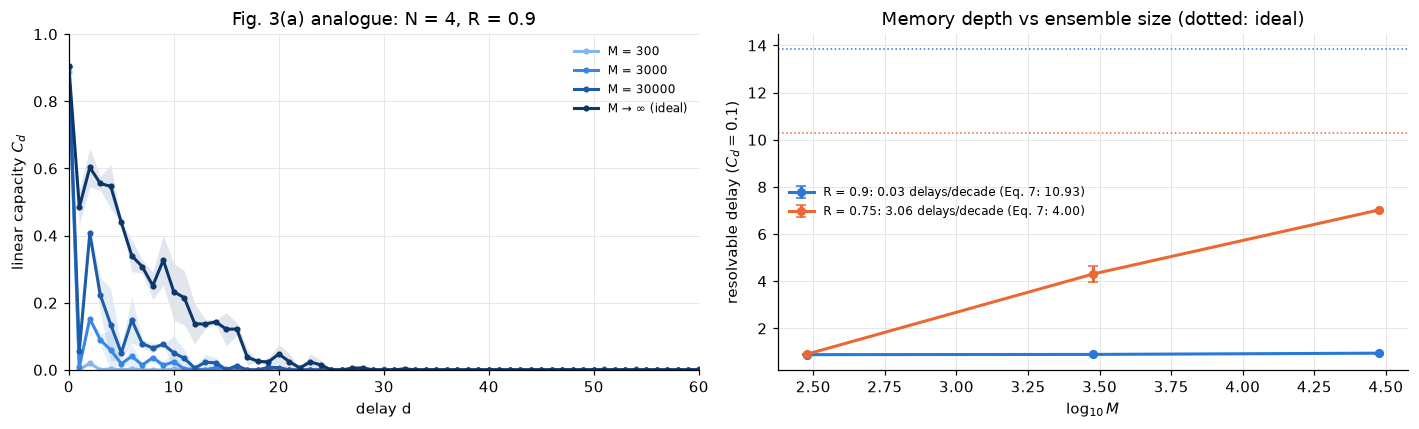

,R,d1/2 at M=300,d1/2 at M=3000,d1/2 at M=30000,d1_2_ideal,d(C=0.1) at M=300,d(C=0.1) at M=3000,d(C=0.1) at M=30000,d01_ideal,slope_per_decade,slope_se,theory_Eq7
0,0.90,0.437,0.450,0.478,2.745,0.887,0.897,0.950,13.830,0.031,0.012,10.927
1,0.75,0.436,0.527,0.799,5.471,0.905,4.306,7.027,10.307,3.061,0.157,4.002


In [20]:
FS_SUMMARY = {}
if FS_RUNS:
    Ms = sorted(CFG.M_fs)
    keys = Ms + ["ideal"]
    colors = dict(zip(keys, ramp(len(keys))))
    R_main = CFG.R_fs[0]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for key in keys:
        C = np.array([r["linear"][key] for r in FS_RUNS if r["R"] == R_main])
        lab = "M → ∞ (ideal)" if key == "ideal" else f"M = {key:g}"
        axes[0].plot(d_axis, C.mean(0), "o-", ms=3, color=colors[key], label=lab)
        axes[0].fill_between(d_axis, C.mean(0) - C.std(0), C.mean(0) + C.std(0), color=colors[key], alpha=0.12, lw=0)
    axes[0].set(xlim=(0, 60), ylim=(0, 1), xlabel="delay d", ylabel="linear capacity $C_d$",
                title=f"Fig. 3(a) analogue: N = {CFG.N_fs}, R = {R_main}")
    axes[0].legend(fontsize=8)
    rows = []
    for i, R in enumerate(CFG.R_fs):
        half = np.array([[r["depth"][M] for M in Ms] for r in FS_RUNS if r["R"] == R])
        depth = np.array([[r["resolve"][M] for M in Ms] for r in FS_RUNS if r["R"] == R])
        fit = sst.linregress(np.repeat(np.log10(Ms)[None, :], len(depth), 0).ravel(), depth.ravel())
        axes[1].errorbar(np.log10(Ms), depth.mean(0), yerr=depth.std(0), marker="o", color=PALETTE[i], capsize=3,
                         label=f"R = {R}: {fit.slope:.2f} delays/decade (Eq. 7: {1 / (2 * np.log10(1 / R)):.2f})")
        ideal_depth = np.mean([r["resolve"]["ideal"] for r in FS_RUNS if r["R"] == R])
        axes[1].axhline(ideal_depth, ls=":", color=PALETTE[i], lw=1)
        rows.append(dict(R=R, **{f"d1/2 at M={M:g}": half.mean(0)[j] for j, M in enumerate(Ms)},
                         d1_2_ideal=np.mean([r["depth"]["ideal"] for r in FS_RUNS if r["R"] == R]),
                         **{f"d(C=0.1) at M={M:g}": depth.mean(0)[j] for j, M in enumerate(Ms)},
                         d01_ideal=ideal_depth, slope_per_decade=fit.slope, slope_se=fit.stderr,
                         theory_Eq7=1 / (2 * np.log10(1 / R))))
        FS_SUMMARY[R] = rows[-1]
        record_check("10.3", f"larger M resolves longer delays (R={R})", "d(C=0.1) increasing in M",
                     np.round(depth.mean(0), 2).tolist(), np.all(np.diff(depth.mean(0)) > 0))
    axes[1].set(xlabel=r"$\log_{10}M$", ylabel=r"resolvable delay ($C_d=0.1$)",
                title="Memory depth vs ensemble size (dotted: ideal)")
    axes[1].legend(fontsize=8)
    fig.tight_layout(); savefig(fig, "fig10_3_finite_shot_capacity"); plt.show()
    display(pd.DataFrame(rows).round(3))

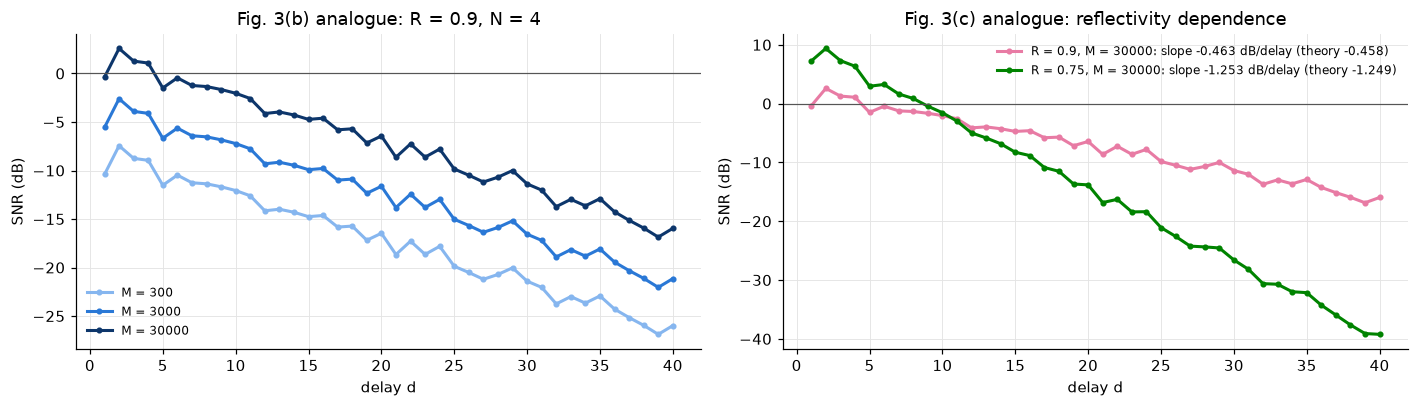

OK    [10.4] SNR slope per delay, R=0.9: expected -0.458 dB; observed -0.463 dB
OK    [10.4] SNR gain per decade of M, R=0.9: expected 5.0 dB (Eq. G9); observed 5.01 ± 0.26 dB
OK    [10.4] SNR slope per delay, R=0.75: expected -1.249 dB; observed -1.253 dB
OK    [10.4] SNR gain per decade of M, R=0.75: expected 5.0 dB (Eq. G9); observed 4.99 ± 0.16 dB


,R,slope_dB_per_delay,slope_se,theory_10log10R,shift_dB_per_decade,shift_se,theory_shift,delta_d_per_decade,theory_delta_d
0,0.90,-0.463,0.01,-0.458,5.007,0.260,5.0,10.820,10.927
1,0.75,-1.253,0.01,-1.249,4.992,0.156,5.0,3.985,4.002


SNR offset at d=1, M=30000: R=0.75 minus R=0.9 = 7.62 dB; Eq. (G10) predicts 7.96 dB (assuming C_SNR independent of R)
M'/M = R^(-2 Delta d): each decade of M buys Delta d = 1/(2 log10(1/R)) delays; measured values in the table.


In [21]:
SNR_RESULTS = {}
if FS_RUNS:
    d_snr = np.arange(1, CFG.snr_d_max + 1)
    Ms = sorted(CFG.M_fs)
    for R in CFG.R_fs:
        runs = [r for r in FS_RUNS if r["R"] == R]
        gam = np.mean([r["gamma_mean"] for r in runs], 0)
        xi = {M: np.mean([r["xi_mean"][M] for r in runs]) for M in Ms}
        snr = {M: 10 * np.log10(gam / xi[M]) for M in Ms}
        slopes = [sst.linregress(d_snr, snr[M]) for M in Ms]
        per_net_xi = np.array([[r["xi_mean"][M] for M in Ms] for r in runs])
        shift = sst.linregress(np.repeat(np.log10(Ms)[None, :], len(runs), 0).ravel(),
                               -10 * np.log10(per_net_xi).ravel())
        SNR_RESULTS[R] = dict(snr=snr, gamma=gam, xi=xi, slope=slopes[0].slope, slope_se=slopes[0].stderr,
                              shift=shift.slope, shift_se=shift.stderr, snr1={M: snr[M][0] for M in Ms})
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
    R_main = CFG.R_fs[0]
    for M, col in zip(Ms, ramp(len(Ms))):
        axes[0].plot(d_snr, SNR_RESULTS[R_main]["snr"][M], "o-", ms=3, color=col, label=f"M = {M:g}")
    axes[0].axhline(0, color="#555", lw=0.8)
    axes[0].set(xlabel="delay d", ylabel="SNR (dB)", title=f"Fig. 3(b) analogue: R = {R_main}, N = {CFG.N_fs}")
    axes[0].legend(fontsize=8)
    for i, R in enumerate(CFG.R_fs):
        axes[1].plot(d_snr, SNR_RESULTS[R]["snr"][max(Ms)], "o-", ms=3, color=PALETTE[[4, 5][i % 2]],
                     label=f"R = {R}, M = {max(Ms):g}: slope {SNR_RESULTS[R]['slope']:.3f} dB/delay "
                           f"(theory {10 * np.log10(R):.3f})")
    axes[1].axhline(0, color="#555", lw=0.8)
    axes[1].set(xlabel="delay d", ylabel="SNR (dB)", title="Fig. 3(c) analogue: reflectivity dependence")
    axes[1].legend(fontsize=8)
    fig.tight_layout(); savefig(fig, "fig10_4_snr"); plt.show()

    rows = []
    for R, d in SNR_RESULTS.items():
        dd = d["shift"] / abs(d["slope"])
        rows.append(dict(R=R, slope_dB_per_delay=d["slope"], slope_se=d["slope_se"], theory_10log10R=10 * np.log10(R),
                         shift_dB_per_decade=d["shift"], shift_se=d["shift_se"], theory_shift=5.0,
                         delta_d_per_decade=dd, theory_delta_d=1 / (2 * np.log10(1 / R))))
        record_check("10.4", f"SNR slope per delay, R={R}", f"{10 * np.log10(R):.3f} dB", f"{d['slope']:.3f} dB",
                     abs(d["slope"] - 10 * np.log10(R)) <= 0.1 * abs(10 * np.log10(R)) + 3 * d["slope_se"])
        record_check("10.4", f"SNR gain per decade of M, R={R}", "5.0 dB (Eq. G9)",
                     f"{d['shift']:.2f} ± {d['shift_se']:.2f} dB", abs(d["shift"] - 5) <= max(0.5, 3 * d["shift_se"]))
    SNR_TABLE = pd.DataFrame(rows)
    display(SNR_TABLE.round(3))
    if len(CFG.R_fs) >= 2:
        R1, R2 = CFG.R_fs[1], CFG.R_fs[0]
        off = SNR_RESULTS[R1]["snr1"][max(Ms)] - SNR_RESULTS[R2]["snr1"][max(Ms)]
        SNR_RESULTS["offset"] = dict(R_small=R1, R_large=R2, measured=off,
                                     theory=20 * np.log10((1 - R1) / (1 - R2)))
        print(f"SNR offset at d=1, M={max(Ms):g}: R={R1} minus R={R2} = {off:.2f} dB; Eq. (G10) predicts "
              f"{SNR_RESULTS['offset']['theory']:.2f} dB (assuming C_SNR independent of R)")
        print("M'/M = R^(-2 Delta d): each decade of M buys Delta d = 1/(2 log10(1/R)) delays; measured values in the table.")

## 11. Reservoir-size scaling strategy (Fig. 4)

Four resource strategies are compared as $N$ grows (Eq. 9, Fig. 4). The paper chooses the constants at its smallest
size: $R(6)=0.72$ and $M(6)=3\cdot6^6\simeq1.4\cdot10^5$. Here the constants are $R(N_0)$ and $M(N_0)$ at the smallest
$N_0$ of the active mode, which reproduces the paper's values exactly in paper mode.

| case | reflectivity | ensemble |
|---|---|---|
| 1 | $R(N_0)$ constant | $M(N_0)$ constant |
| 2 | $R(N)=1-10/N^2$ | $M(N_0)$ constant |
| 3 | $R(N_0)$ constant | $M(N)=3N^6$ |
| 4 | $R(N)=1-10/N^2$ | $M(N)=3N^6$ |

Two facts motivate the strategy. The ideal delay depth grows roughly $\propto N^2$. Keeping the SNR of the
$(d+\Delta d)$-th term fixed then needs $\sqrt{M}\,(1-R)^2R^{d-1}=$ const (App. G3). With $R(N)=1-\mathcal C/N^2$,
$R^{d(N)}\to e^{-\mathcal C\alpha}$ stays constant, so only a *polynomial* growth of $M$ is required. Eq. (G15) gives
$M\propto N^8$; the paper's numerics use $3N^6$.

In [22]:
def R_of_N(N):
    return 1.0 - CFG.scaling_C / N ** 2

def M_of_N(N):
    return int(round(CFG.scaling_M_coeff * N ** CFG.scaling_M_power))

N0 = min(CFG.N_size)
R_CONST, M_CONST = R_of_N(N0), M_of_N(N0)
print(f"N0 = {N0}: constant R = R(N0) = {R_CONST:.4f}, constant M = M(N0) = {M_CONST:,}")
display(pd.DataFrame({"R(N)": {N: R_of_N(N) for N in CFG.N_size}, "M(N)": {N: M_of_N(N) for N in CFG.N_size},
                      "N(N+1)/2": {N: feature_dim(N) for N in CFG.N_size}}).round(4))

def size_scaling_run(N, net_id):
    L, L_test = CFG.L_train_size, CFG.L_test_size

    def compute():
        nets, iu = networks_for(N, net_id), np.triu_indices(N)
        Ms = sorted({M_CONST, M_of_N(N)})
        results = {}
        for R in sorted({R_CONST, R_of_N(N)}):
            res = NativePiquassoCVReservoir(N, R, nets)
            Lm = washout_length(R, CFG.washout_tol_capacity, CFG.d_max)
            strings, feats = {}, {}
            for part, length in (("train", L), ("test", L_test)):
                s = np.random.default_rng(child_seed("size-inputs", part, N, R, net_id)).uniform(
                    CFG.input_low, CFG.input_high, Lm + length)
                run = res.run(s, keep_output=True)
                est = FiniteShotEstimator(N, seed=child_seed("size-shots", part, N, R, net_id))
                F = {M: np.empty((length, feature_dim(N))) for M in Ms}
                for k, cov in enumerate(run["output_cov"][Lm:]):
                    for M, snap in est.estimate(cov, Ms).items():
                        F[M][k] = snap["cov"][iu]
                strings[part], feats[part] = s, F
            for M in Ms:
                ipc = IPCAnalyzer(child_seed("size-surrogates", N, R, net_id, M)).capacities(
                    feats["train"][M], strings["train"], Lm, feats["test"][M], strings["test"], Lm)
                results[(R, M)] = {k: ipc[k] for k in ("total", "normalized", "D_out")}
        cases = {1: (R_CONST, M_CONST), 2: (R_of_N(N), M_CONST), 3: (R_CONST, M_of_N(N)), 4: (R_of_N(N), M_of_N(N))}
        return {c: results[rm] for c, rm in cases.items()}

    return checkpointed(("size-scaling", N, net_id, L, L_test, R_CONST, M_CONST), compute)

SIZE_RUNS = {}
if ENABLE_FINITE_SHOTS:
    steps, shots, calls = {}, {}, {}
    for N in CFG.N_size:
        nR = len({R_CONST, R_of_N(N)})
        n_tot = CFG.n_networks_size * nR
        steps[N] = n_tot * (2 * washout_length(min(R_CONST, R_of_N(N)), CFG.washout_tol_capacity, CFG.d_max)
                            + CFG.L_train_size + CFG.L_test_size)
        shots[N] = n_tot * (CFG.L_train_size + CFG.L_test_size) * M_of_N(N)
        calls[N] = n_tot * (CFG.L_train_size + CFG.L_test_size) * (2 + M_of_N(N) // CFG.shot_chunk)
    announce_cost("11 size scaling (Fig. 4)", steps, shots, calls)
    jobs = [(N, n) for N in CFG.N_size for n in range(CFG.n_networks_size)]
    for N, n in tqdm(jobs, desc="11 size scaling", mininterval=10, file=sys.stdout):
        SIZE_RUNS[(N, n)] = size_scaling_run(N, n)

N0 = 4: constant R = R(N0) = 0.3750, constant M = M(N0) = 12,288


,R(N),M(N),N(N+1)/2
4,0.375,12288,10
5,0.600,46875,15


[cost] 11 size scaling (Fig. 4): ~2.1 min on this machine | Piquasso round trips: 14,400 | homodyne shot vectors: 477,171,000 | peak extra memory ~8 MB



11 size scaling:   0%|          | 0/4 [00:00<?, ?it/s]


11 size scaling:  50%|█████     | 2/4 [00:13<00:13,  6.91s/it]


11 size scaling:  50%|█████     | 2/4 [00:33<00:13,  6.91s/it]


11 size scaling:  75%|███████▌  | 3/4 [01:00<00:23, 23.63s/it]


11 size scaling: 100%|██████████| 4/4 [01:47<00:00, 32.34s/it]


11 size scaling: 100%|██████████| 4/4 [01:47<00:00, 26.96s/it]

total        normalized       
         mean    std       mean    std
case N                                
1    4  5.627  0.179      0.563  0.018
     5  6.057  0.324      0.404  0.022
2    4  5.627  0.179      0.563  0.018
     5  5.946  0.002      0.396  0.000
3    4  5.627  0.179      0.563  0.018
     5  6.698  0.239      0.447  0.016
4    4  5.627  0.179      0.563  0.018
     5  6.831  0.011      0.455  0.001

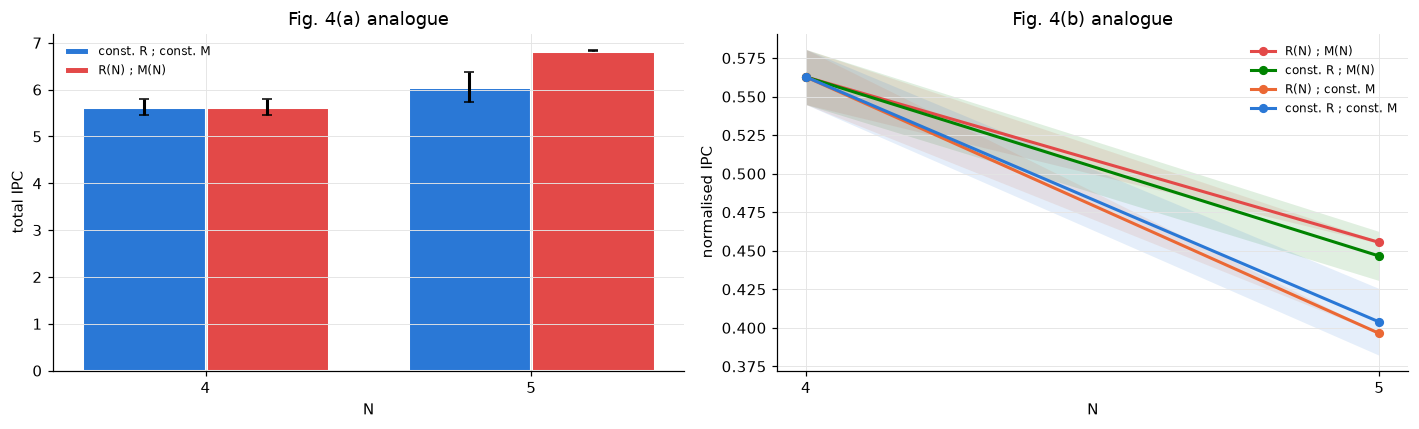

OK    [11] R(N),M(N) strategy beats constant resources at N=5: expected case 4 > case 1; observed 0.455 vs 0.404
OK    [11] normalised IPC loss from N0 to Nmax is smaller with R(N),M(N): expected drop4 > drop1; observed -0.107 vs -0.159


In [23]:
SIZE_SUMMARY = None
if SIZE_RUNS:
    rows = [dict(N=N, net=n, case=c, total=v["total"], normalized=v["normalized"])
            for (N, n), cases in SIZE_RUNS.items() for c, v in cases.items()]
    SIZE_DF = pd.DataFrame(rows)
    SIZE_SUMMARY = SIZE_DF.groupby(["case", "N"])[["total", "normalized"]].agg(["mean", "std"])
    display(SIZE_SUMMARY.round(3))
    labels = {1: "const. R ; const. M", 2: "R(N) ; const. M", 3: "const. R ; M(N)", 4: "R(N) ; M(N)"}
    case_colors = {1: PALETTE[0], 2: PALETTE[1], 3: PALETTE[5], 4: PALETTE[7]}
    Ns = sorted(CFG.N_size)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    w = 0.38
    for off, c in ((-w / 2, 1), (w / 2, 4)):
        m, s = SIZE_SUMMARY.loc[c]["total"]["mean"], SIZE_SUMMARY.loc[c]["total"]["std"]
        axes[0].bar(np.array(Ns) + off, m.values, width=w, yerr=s.values, color=case_colors[c], capsize=3,
                    edgecolor="white", linewidth=2, label=labels[c])
    axes[0].set(xlabel="N", ylabel="total IPC", title="Fig. 4(a) analogue", xticks=Ns)
    axes[0].legend(fontsize=8)
    for c in (4, 3, 2, 1):
        m, s = SIZE_SUMMARY.loc[c]["normalized"]["mean"], SIZE_SUMMARY.loc[c]["normalized"]["std"]
        axes[1].plot(Ns, m.values, "o-", color=case_colors[c], label=labels[c])
        axes[1].fill_between(Ns, (m - s).values, (m + s).values, color=case_colors[c], alpha=0.12, lw=0)
    axes[1].set(xlabel="N", ylabel="normalised IPC", title="Fig. 4(b) analogue", xticks=Ns)
    axes[1].legend(fontsize=8)
    fig.tight_layout(); savefig(fig, "fig11_size_scaling"); plt.show()

    Nmax = max(Ns)
    n4, n1 = SIZE_SUMMARY.loc[(4, Nmax), ("normalized", "mean")], SIZE_SUMMARY.loc[(1, Nmax), ("normalized", "mean")]
    record_check("11", f"R(N),M(N) strategy beats constant resources at N={Nmax}", "case 4 > case 1",
                 f"{n4:.3f} vs {n1:.3f}", n4 > n1)
    if len(Ns) > 1:
        drop4 = n4 - SIZE_SUMMARY.loc[(4, N0), ("normalized", "mean")]
        drop1 = n1 - SIZE_SUMMARY.loc[(1, N0), ("normalized", "mean")]
        record_check("11", "normalised IPC loss from N0 to Nmax is smaller with R(N),M(N)", "drop4 > drop1",
                     f"{drop4:+.3f} vs {drop1:+.3f}", drop4 > drop1)

**Why both resources are needed.** At constant $R$ and $M$ (case 1), the extra observables of a larger reservoir can
only hold information about deeper delays, and those are buried under the $M^{-1/2}$ noise floor. The normalised IPC
therefore falls. Raising $R$ alone (case 2) extends the ideal memory, but it also weakens the injected signal
$\propto(1-R)^2$, so at fixed $M$ the benefit is lost. Raising $M$ alone (case 3) lowers the noise floor, but at constant
$R$ the ideal delayed terms decay as $R^{d}$ with the same rate, so the depth gained is only logarithmic in $M$. Only
when $R(N)$ and $M(N)$ grow together (case 4) does the SNR of the $\propto N^2$ deeper terms stay constant, so the
normalised IPC can stay roughly flat. The automated checks above state which of these trends the active run shows.

## 12. Santa Fe chaotic-laser one-step prediction (Fig. 5)

**Dataset.** The paper uses "the so-called Santa Fe dataset of experimental measurements of a chaotic laser" (Sec. III D,
Refs. 55–56). This is data set A of the Santa Fe time-series competition: intensity of a far-infrared NH$_3$ laser.
The notebook downloads the standard 10 093-sample laser series ($1000$ points of `A.dat` followed by the continuation)
from a tag-pinned mirror, verifies its SHA-256, and caches it only in the temporary runtime directory. The paper says
the dataset "contains a total of 4000 input points"; we use the **first 4000 samples**.

**Preprocessing.** The paper does not state it. We use $s=(x-\bar x)/(\max x-\bar x)$ over the 4000 samples, which gives
zero mean and $s\in[-0.296,1]$. This was *inferred* from Fig. 5(a), whose signal spans about $[-0.29,0.93]$. The cell
below checks the inference automatically: it searches the normalised series for the window plotted in Fig. 5(a), using
approximate peak values read off the figure, and compares the fit with other common normalisations.

**Task and protocol (Sec. III D).** Target $y_k=s_{k+1}$. Encoding $\phi_k=3\pi s_k/4$ with $r_k=1$. Washout
$R^{L_m}<10^{-8}$ ($L_m=27$ for $R=0.5$ and $175$ for $R=0.9$), $L=3000$ training steps, and all remaining valid steps
for testing. Observables $\langle X_iX_j\rangle$, $\langle X_i^2X_j^2\rangle$ and $\langle X_i^3X_j\rangle$ for $j\ge i$,
i.e. $3N(N+1)/2$ features. In the ideal case the fourth moments follow from Wick/Isserlis:
$\langle X_i^2X_j^2\rangle=\sigma_{ii}\sigma_{jj}+2\sigma_{ij}^2$ and $\langle X_i^3X_j\rangle=3\sigma_{ii}\sigma_{ij}$
(zero mean). With finite $M$ they are estimated directly from the Piquasso homodyne samples. NMSE follows Eq. (A5)
(normalised by $\sum y^2$). The variance-normalised NMSE is also reported.

source URL : runtime cache C:\Users\TONMOY~1\AppData\Local\Temp\garcia_beni_cv_qrc\data\santafe_laser.npy (originally https://raw.githubusercontent.com/reservoirpy/reservoirpy/v0.4.0/reservoirpy/datasets/santafe_laser.npy)
SHA-256    : 8c07281200935596f8e28bc94e1bb25e9964ab7d7f63c5e27ac87b810ac3b33a (verified)
series: Santa Fe competition data set A (NH3 laser), 10093 samples; first 4000 used
normalised: mean -1.2e-17, min -0.2962, max 1.0000


,0,1,2,3,4,5,6,7,8,9
raw intensity,86.0000,141.0000,95.0000,41.0000,22.0000,21.0000,32.0000,72.0000,138.0000,111.0000
normalised s_k,0.1342,0.4159,0.1803,-0.0964,-0.1937,-0.1989,-0.1425,0.0624,0.4006,0.2622


,normalisation,best_offset,mean_abs_peak_error
0,(x - mean)/(max - mean) [used],3165,0.0155
1,(x - min)/(max - min),1461,0.0401
2,z-score,3680,0.3320
3,(x - mean)/(max - min),3679,0.1184


Fig. 5(a) window found at index 3165 = test start for R=0.75 (65 + 3000) + 100; mean peak error 0.015


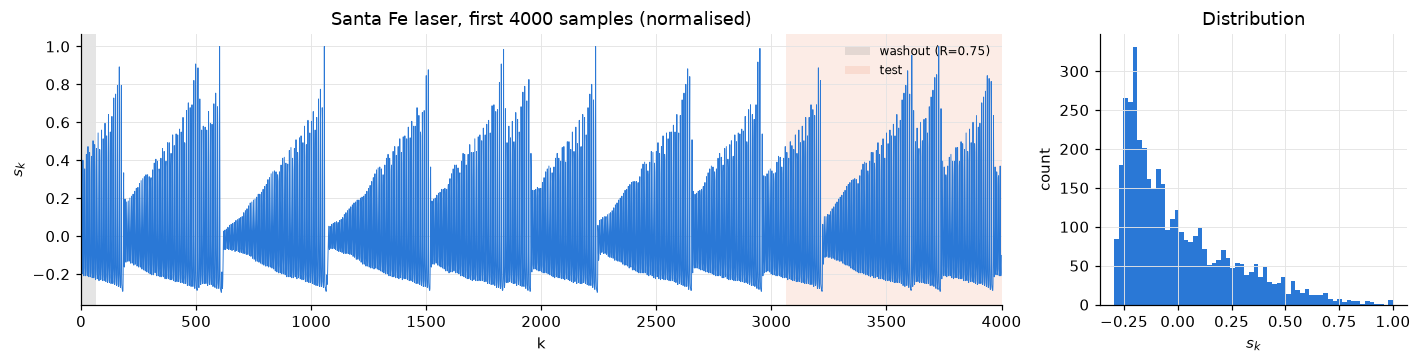

In [24]:
SANTA_FE_SOURCES = [
    "https://raw.githubusercontent.com/reservoirpy/reservoirpy/v0.4.0/reservoirpy/datasets/santafe_laser.npy",
    "https://raw.githubusercontent.com/reservoirpy/reservoirpy/v0.3.13/reservoirpy/datasets/santafe_laser.npy",
]
SANTA_FE_SHA256 = "8c07281200935596f8e28bc94e1bb25e9964ab7d7f63c5e27ac87b810ac3b33a"
A_DAT_HEAD = [86, 141, 95, 41, 22, 21, 32, 72, 138, 111]      # first values of the competition file A.dat

def load_santa_fe():
    cache = Path(tempfile.gettempdir()) / "garcia_beni_cv_qrc" / "data" / "santafe_laser.npy"
    blob, source = None, None
    if cache.exists() and hashlib.sha256(cache.read_bytes()).hexdigest() == SANTA_FE_SHA256:
        blob, source = cache.read_bytes(), f"runtime cache {cache} (originally {SANTA_FE_SOURCES[0]})"
    else:
        for url in SANTA_FE_SOURCES:
            try:
                r = requests.get(url, timeout=60)
                r.raise_for_status()
            except requests.RequestException as exc:
                print(f"download failed from {url}: {exc}")
                continue
            digest = hashlib.sha256(r.content).hexdigest()
            if digest != SANTA_FE_SHA256:
                print(f"checksum mismatch from {url}: {digest}")
                continue
            blob, source = r.content, url
            cache.parent.mkdir(parents=True, exist_ok=True)
            cache.write_bytes(blob)
            break
    if blob is None:
        raise RuntimeError("Could not obtain the Santa Fe laser data with the expected checksum.")
    return np.load(io.BytesIO(blob), allow_pickle=False).ravel().astype(float), source

SF_ENABLED = ENABLE_SANTA_FE
if SF_ENABLED:
    SF_RAW, SF_SOURCE = load_santa_fe()
    print("source URL :", SF_SOURCE)
    print("SHA-256    :", SANTA_FE_SHA256, "(verified)")
    assert len(SF_RAW) == 10093, len(SF_RAW)
    assert np.array_equal(SF_RAW[:10], A_DAT_HEAD), "series does not start with Santa Fe A.dat"
    assert np.all(SF_RAW == np.round(SF_RAW)) and SF_RAW.min() >= 0 and SF_RAW.max() <= 255
    x = SF_RAW[:CFG.santafe_n_points]
    SF = (x - x.mean()) / (x.max() - x.mean())
    assert len(SF) == 4000 and abs(SF.mean()) < 1e-12 and SF.max() == 1.0
    print(f"series: Santa Fe competition data set A (NH3 laser), {len(SF_RAW)} samples; first {len(SF)} used")
    print(f"normalised: mean {SF.mean():.1e}, min {SF.min():.4f}, max {SF.max():.4f}")
    display(pd.DataFrame({"raw intensity": x[:10], "normalised s_k": SF[:10]}).T.round(4))

    # Automated check of the inferred normalisation against Fig. 5(a) (peak values read off the figure, +-0.03)
    fig5a_t = np.array([7, 15, 23, 31, 39, 48]); fig5a_v = np.array([0.72, 0.66, 0.64, 0.69, 0.93, 0.83])
    candidates = {"(x - mean)/(max - mean)  [used]": SF, "(x - min)/(max - min)": (x - x.min()) / (x.max() - x.min()),
                  "z-score": (x - x.mean()) / x.std(), "(x - mean)/(max - min)": (x - x.mean()) / (x.max() - x.min())}
    rows = []
    for name, series in candidates.items():
        errs = [np.abs(series[o + fig5a_t] - fig5a_v).mean() for o in range(len(series) - 60)]
        o = int(np.argmin(errs))
        rows.append(dict(normalisation=name, best_offset=o, mean_abs_peak_error=errs[o]))
    SF_ALIGN = pd.DataFrame(rows)
    display(SF_ALIGN.round(4))
    best_offset = int(SF_ALIGN.iloc[0].best_offset)
    Lm75 = washout_length(0.75, CFG.washout_tol_santafe)
    print(f"Fig. 5(a) window found at index {best_offset} = test start for R=0.75 ({Lm75} + {CFG.santafe_L_train}) "
          f"+ {best_offset - Lm75 - CFG.santafe_L_train}; mean peak error {SF_ALIGN.iloc[0].mean_abs_peak_error:.3f}")

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[3, 1]))
    axes[0].plot(np.arange(len(SF)), SF, lw=0.6, color=PALETTE[0])
    axes[0].axvspan(0, Lm75, color="#999", alpha=0.25, lw=0, label="washout (R=0.75)")
    axes[0].axvspan(Lm75 + CFG.santafe_L_train, len(SF), color=PALETTE[1], alpha=0.12, lw=0, label="test")
    axes[0].set(xlabel="k", ylabel="$s_k$", title="Santa Fe laser, first 4000 samples (normalised)", xlim=(0, len(SF)))
    axes[0].legend(fontsize=8, loc="upper right")
    axes[1].hist(SF, bins=60, color=PALETTE[0])
    axes[1].set(xlabel="$s_k$", ylabel="count", title="Distribution")
    fig.tight_layout(); savefig(fig, "fig12_1_santafe_data"); plt.show()
else:
    print("ENABLE_SANTA_FE = False: Section 12 skipped.")

### 12.2 Wick/Isserlis fourth moments versus Piquasso samples

Before the ideal Wick features are used, they are checked against fourth moments estimated from Piquasso homodyne
samples of a real reservoir output state. The check runs through the public API (small $M$) and through the kernel
(large $M$), and uses standard errors computed from the sampled products themselves.

In [25]:
def santafe_features(cov_x, m22, m31):
    iu = np.triu_indices(len(cov_x))
    return np.concatenate([cov_x[iu], m22[iu], m31[iu]])

def features_to_xblock(f, N):
    X = np.zeros((N, N))
    X[np.triu_indices(N)] = f
    return X + np.triu(X, 1).T

if SF_ENABLED:
    N_w = CFG.N_sf
    res_w = NativePiquassoCVReservoir(N_w, 0.75, networks_for(N_w, 0, "networks-sf"))
    cov_w = res_w.run(SF[:100], keep_output=True)["output_cov"][-1]
    Sx = x_block(cov_w)
    w22, w31 = wick_fourth_moments(Sx)
    rows = []
    for smp, m in (("public", 3000), ("kernel", 400000)):
        X = FiniteShotEstimator(N_w, seed=child_seed("wick-check", smp), sampler=smp).sample(cov_w, m)
        X2 = X * X
        p22 = X2[:, :, None] * X2[:, None, :]
        p31 = (X2 * X)[:, :, None] * X[:, None, :]
        z22 = np.abs(p22.mean(0) - w22) / (p22.std(0) / np.sqrt(m))
        z31 = np.abs(p31.mean(0) - w31) / (p31.std(0) / np.sqrt(m))
        rows.append(dict(sampler=smp, M=m, max_z_X2X2=z22.max(), max_z_X3X=z31.max(),
                         rel_err_X2X2=np.abs(p22.mean(0) - w22).max() / np.abs(w22).max(),
                         rel_err_X3X=np.abs(p31.mean(0) - w31).max() / np.abs(w31).max()))
        # Bonferroni-style bound over N^2 entries: |z| < 5 is a > 5-sigma failure criterion
        assert z22.max() < 5.5 and z31.max() < 5.5, rows[-1]
    display(pd.DataFrame(rows).round(4))
    print("Wick/Isserlis fourth moments agree with Piquasso homodyne samples within statistical error.")

,sampler,M,max_z_X2X2,max_z_X3X,rel_err_X2X2,rel_err_X3X
0,public,3000,1.7077,1.8164,0.0572,0.0572
1,kernel,400000,1.6930,1.6018,0.0067,0.0067


Wick/Isserlis fourth moments agree with Piquasso homodyne samples within statistical error.


### 12.3 Prediction experiments

For each reflectivity and network, one Piquasso trajectory over the 3999 usable inputs provides the ideal output
covariances. The ideal features are built with the Wick relations. With finite ensembles, one nested stream of
$\max(M)$ Piquasso homodyne shots per round trip gives the estimated covariance and fourth moments for every $M$. The
readout (Eq. A6) is trained on steps $L_m\ldots L_m+2999$ and tested on the rest.

In [26]:
def santafe_run(N, R, net_id, with_shots):
    Ms = sorted(CFG.M_sf) if with_shots else []

    def compute():
        nets = networks_for(N, net_id, "networks-sf")
        res = NativePiquassoCVReservoir(N, R, nets)
        Lm, L = washout_length(R, CFG.washout_tol_santafe), CFG.santafe_L_train
        inputs, targets = SF[:-1], SF[1:]                       # y_k = s_{k+1}
        run = res.run(inputs, keep_output=with_shots)
        T = len(inputs)
        F = {"ideal": np.array([santafe_features(Sx, *wick_fourth_moments(Sx))
                                for Sx in (features_to_xblock(f, N) for f in run["features"][Lm:])])}
        if with_shots:
            est = FiniteShotEstimator(N, seed=child_seed("sf-shots", N, R, net_id))
            for M in Ms:
                F[M] = np.empty_like(F["ideal"])
            for k, cov in enumerate(run["output_cov"][Lm:]):
                for M, snap in est.estimate(cov, Ms, fourth_order=True).items():
                    F[M][k] = santafe_features(snap["cov"], snap["m22"], snap["m31"])
        y_tr, y_te = targets[Lm:Lm + L], targets[Lm + L:T]
        out = dict(N=N, R=R, net=net_id, washout=Lm, n_test=len(y_te), results={})
        for key, feats in F.items():
            ro = LinearReadout().fit(feats[:L], y_tr[:, None])
            p_tr, p_te = ro.predict(feats[:L])[:, 0], ro.predict(feats[L:])[:, 0]
            out["results"][key] = dict(
                nmse_train=float(nmse(y_tr, p_tr)), nmse_test=float(nmse(y_te, p_te)),
                nmse_test_var=float(((p_te - y_te) ** 2).mean() / y_te.var()),
                prediction=p_te if net_id == 0 else None)
        out["y_test"] = y_te if net_id == 0 else None
        return out

    return checkpointed(("santafe", N, R, net_id, with_shots, tuple(Ms)), compute)

SF_RUNS = []
if SF_ENABLED:
    N_sf = CFG.N_sf
    n_fs = CFG.n_networks_sf_fs if ENABLE_FINITE_SHOTS else 0
    steps = len(CFG.R_sf) * CFG.n_networks_sf * (len(SF) - 1)
    shot_steps = sum(n_fs * (len(SF) - 1 - washout_length(R, CFG.washout_tol_santafe)) for R in CFG.R_sf)
    announce_cost("12 Santa Fe", {N_sf: steps}, {N_sf: shot_steps * max(CFG.M_sf)} if n_fs else None,
                  {N_sf: shot_steps * (len(CFG.M_sf) + max(CFG.M_sf) // CFG.shot_chunk)} if n_fs else None)
    jobs = [(N_sf, R, n, n < n_fs) for R in CFG.R_sf for n in range(CFG.n_networks_sf)]
    SF_RUNS = [santafe_run(*job) for job in tqdm(jobs, desc="12 Santa Fe", mininterval=10, file=sys.stdout)]
    SF_DF = pd.DataFrame([dict(R=r["R"], net=r["net"], M=("ideal" if k == "ideal" else k), **{
        q: v[q] for q in ("nmse_train", "nmse_test", "nmse_test_var")}) for r in SF_RUNS for k, v in r["results"].items()])
    q = SF_DF.groupby(["R", "M"], sort=False)["nmse_test"]
    SF_SUMMARY = pd.DataFrame({"median test NMSE": q.median(), "IQR low (25%)": q.quantile(0.25),
                               "IQR high (75%)": q.quantile(0.75), "median train NMSE":
                               SF_DF.groupby(["R", "M"], sort=False)["nmse_train"].median(),
                               "median test NMSE (variance-normalised)":
                               SF_DF.groupby(["R", "M"], sort=False)["nmse_test_var"].median(), "networks": q.size()})
    display(SF_SUMMARY)
    if SAVE_RESULTS:
        SF_DF.to_csv(RESULTS_DIR / "santafe_runs.csv", index=False)

[cost] 12 Santa Fe: ~2.5 min on this machine | Piquasso round trips: 35,991 | homodyne shot vectors: 351,900,000 | peak extra memory ~6 MB



12 Santa Fe:   0%|          | 0/9 [00:00<?, ?it/s]


12 Santa Fe:  11%|█         | 1/9 [00:15<02:00, 15.05s/it]


12 Santa Fe:  22%|██▏       | 2/9 [00:30<01:46, 15.26s/it]


12 Santa Fe:  33%|███▎      | 3/9 [00:45<01:31, 15.18s/it]

...


12 Santa Fe:  78%|███████▊  | 7/9 [01:44<00:29, 14.80s/it]


12 Santa Fe:  89%|████████▉ | 8/9 [01:59<00:14, 14.71s/it]


12 Santa Fe: 100%|██████████| 9/9 [02:13<00:00, 14.70s/it]


12 Santa Fe: 100%|██████████| 9/9 [02:13<00:00, 14.87s/it]

median test NMSE  IQR low (25%)  IQR high (75%)  \
R    M                                                        
0.50 ideal          0.022010       0.021333        0.022033   
     100            0.539020       0.537171        0.547881   
     1000           0.426262       0.418103        0.428358   
     10000          0.202828       0.188226        0.203984   
0.75 ideal          0.023482       0.021574        0.029669   
     100            0.603923       0.601516        0.612039   
     1000           0.487853       0.475066        0.502788   
     10000          0.339877       0.315221        0.380095   
0.90 ideal          0.068495       0.064327        0.068671   
     100            0.685531       0.680316        0.696059   
     1000           0.651743       0.637864        0.659837   
     10000          0.550579       0.546801        0.576675   

            median train NMSE  median test NMSE (variance-normalised)  \
R    M                                                                  
0.50 ideal           0.022069                                0.022011   
     100             0.530854                                0.539024   
     1000            0.399797                                0.426265   
     10000           0.190901                                0.202829   
0.75 ideal           0.023605                                0.023482   
     100             0.592387                                0.603926   
     1000            0.469028                                0.487855   
     10000           0.318929                                0.339878   
0.90 ideal           0.057607                                0.068497   
     100             0.660453                                0.685554   
     1000            0.612265                                0.651765   
     10000           0.525855                                0.550597   

            networks  
R    M                
0.50 ideal         3  
     100           3  
     1000          3  
     10000         3  
0.75 ideal         3  
     100           3  
     1000          3  
     10000         3  
0.90 ideal         3  
     100           3  
     1000          3  
     10000         3

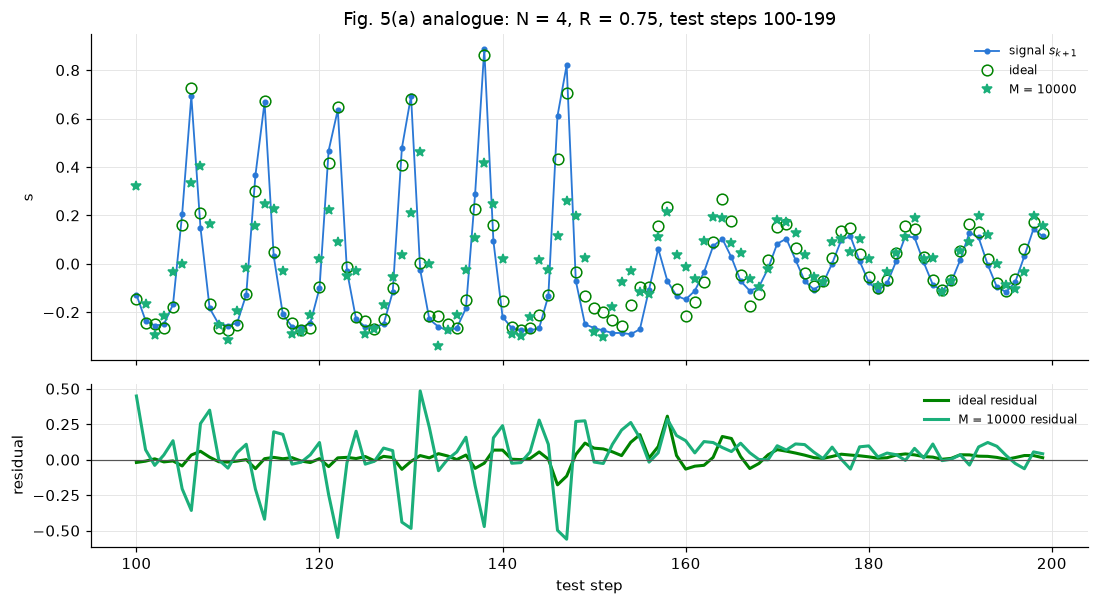

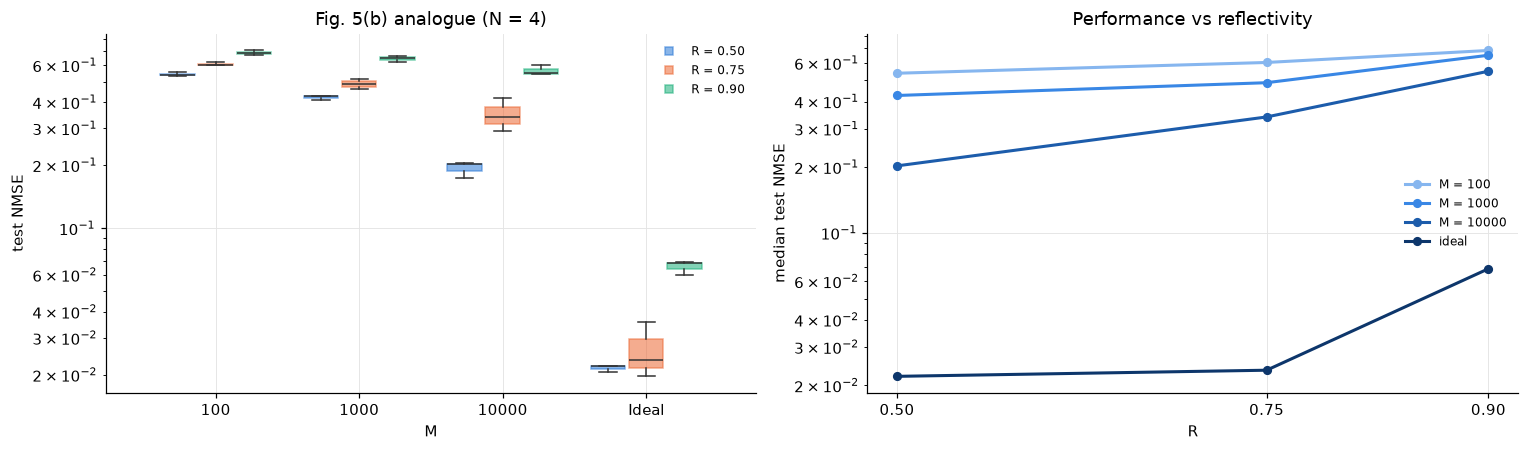

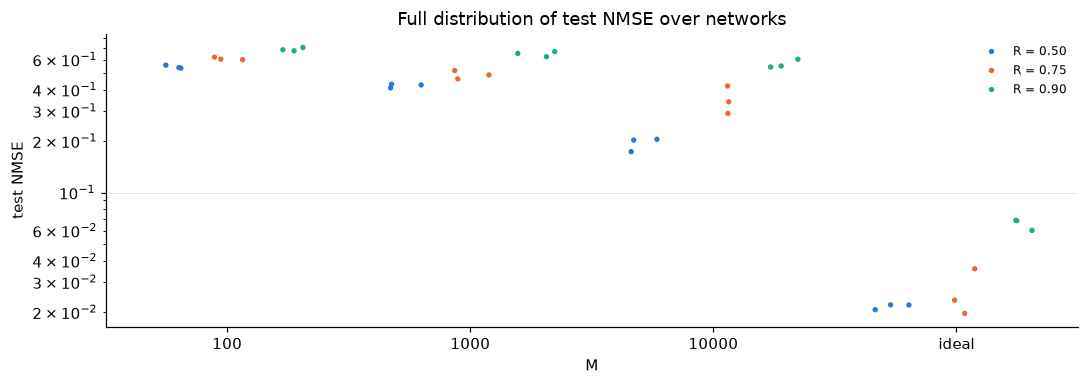

best R at smallest M (100): R = 0.5   medians: R=0.5: 0.5390, R=0.75: 0.6039, R=0.9: 0.6855
best R at largest M (10000): R = 0.5   medians: R=0.5: 0.2028, R=0.75: 0.3399, R=0.9: 0.5506
best R at ideal (ideal): R = 0.5   medians: R=0.5: 0.0220, R=0.75: 0.0235, R=0.9: 0.0685
MISS  [12] Santa Fe reaches the paper's NMSE ~ 1e-2 regime (best ideal median): expected <= 2e-2 (paper-scale target, N=12); observed 0.0220 (N=4)


In [27]:
if SF_RUNS:
    Ms_sf = sorted(CFG.M_sf) if ENABLE_FINITE_SHOTS else []
    R_tr = 0.75 if 0.75 in CFG.R_sf else CFG.R_sf[0]
    r0 = next(r for r in SF_RUNS if r["R"] == R_tr and r["net"] == 0)
    y = r0["y_test"]
    win = slice(100, 200) if len(y) >= 200 else slice(0, min(100, len(y)))
    t = np.arange(len(y))[win]
    fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    axes[0].plot(t, y[win], "o-", ms=3, lw=1.2, color=PALETTE[0], label="signal $s_{k+1}$")
    axes[0].plot(t, r0["results"]["ideal"]["prediction"][win], "o", mfc="none", ms=7, color=PALETTE[5], label="ideal")
    if Ms_sf and max(Ms_sf) in r0["results"]:
        axes[0].plot(t, r0["results"][max(Ms_sf)]["prediction"][win], "*", ms=7, color=PALETTE[2],
                     label=f"M = {max(Ms_sf):g}")
    axes[0].set(ylabel="s", title=f"Fig. 5(a) analogue: N = {CFG.N_sf}, R = {R_tr}, test steps {win.start}-{win.stop - 1}")
    axes[0].legend(fontsize=8)
    axes[1].plot(t, r0["results"]["ideal"]["prediction"][win] - y[win], color=PALETTE[5], label="ideal residual")
    if Ms_sf and max(Ms_sf) in r0["results"]:
        axes[1].plot(t, r0["results"][max(Ms_sf)]["prediction"][win] - y[win], color=PALETTE[2],
                     label=f"M = {max(Ms_sf):g} residual")
    axes[1].axhline(0, color="#555", lw=0.8)
    axes[1].set(xlabel="test step", ylabel="residual")
    axes[1].legend(fontsize=8)
    fig.tight_layout(); savefig(fig, "fig12_3_santafe_trace"); plt.show()

    keys = Ms_sf + ["ideal"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    width = 0.8 / len(CFG.R_sf)
    for i, R in enumerate(CFG.R_sf):
        data = [SF_DF[(SF_DF.R == R) & (SF_DF.M.astype(str) == str(k))]["nmse_test"].values for k in keys]
        pos = np.arange(len(keys)) + (i - (len(CFG.R_sf) - 1) / 2) * width
        bp = axes[0].boxplot(data, positions=pos, widths=width * 0.9, patch_artist=True, showfliers=False)
        for box in bp["boxes"]:
            box.set(facecolor=PALETTE[i], alpha=0.55, edgecolor=PALETTE[i])
        for part in ("medians", "whiskers", "caps"):
            for line in bp[part]:
                line.set(color="#333")
        axes[0].plot([], [], "s", color=PALETTE[i], alpha=0.55, label=f"R = {R:.2f}")
    axes[0].set_yscale("log")
    axes[0].set_xticks(range(len(keys)), [f"{k:g}" if k != "ideal" else "Ideal" for k in keys])
    axes[0].set(xlabel="M", ylabel="test NMSE", title=f"Fig. 5(b) analogue (N = {CFG.N_sf})")
    axes[0].legend(fontsize=8)
    for j, k in enumerate(keys):
        med = [SF_DF[(SF_DF.R == R) & (SF_DF.M.astype(str) == str(k))]["nmse_test"].median() for R in CFG.R_sf]
        axes[1].semilogy(CFG.R_sf, med, "o-", color=(ramp(len(keys))[j]),
                         label="ideal" if k == "ideal" else f"M = {k:g}")
    axes[1].set(xlabel="R", ylabel="median test NMSE", title="Performance vs reflectivity", xticks=CFG.R_sf)
    axes[1].legend(fontsize=8)
    fig.tight_layout(); savefig(fig, "fig12_4_santafe_nmse"); plt.show()

    fig, ax = plt.subplots(figsize=(10, 3.6))
    plot_df = SF_DF.assign(M=SF_DF.M.astype(str), R=SF_DF.R.map(lambda v: f"R = {v:.2f}"))
    sns.stripplot(data=plot_df, x="M", y="nmse_test", hue="R", order=[str(k) for k in keys], dodge=True, size=3.5,
                  palette=PALETTE[:len(CFG.R_sf)], ax=ax, log_scale=True, jitter=0.25)
    ax.set(xlabel="M", ylabel="test NMSE", title="Full distribution of test NMSE over networks")
    ax.legend(fontsize=8)
    fig.tight_layout(); savefig(fig, "fig12_5_santafe_distributions"); plt.show()

    SF_BEST = {}
    for label, k in (("smallest M", Ms_sf[0] if Ms_sf else None), ("largest M", Ms_sf[-1] if Ms_sf else None),
                     ("ideal", "ideal")):
        if k is None:
            continue
        med = {R: SF_DF[(SF_DF.R == R) & (SF_DF.M.astype(str) == str(k))]["nmse_test"].median() for R in CFG.R_sf}
        SF_BEST[label] = (min(med, key=med.get), k, med)
        print(f"best R at {label} ({k}): R = {SF_BEST[label][0]}   medians: " +
              ", ".join(f"R={R}: {v:.4f}" for R, v in med.items()))
    best_ideal = SF_SUMMARY.xs("ideal", level="M")["median test NMSE"].min()
    record_check("12", "Santa Fe reaches the paper's NMSE ~ 1e-2 regime (best ideal median)",
                 "<= 2e-2 (paper-scale target, N=12)",
                 f"{best_ideal:.4f} (N={CFG.N_sf})", best_ideal <= 2e-2)

## 13. Direct comparison with the paper

**Where the paper numbers come from.** The paper publishes no data tables. Every "paper result" below is either:
- a **theoretical formula** stated in the paper (exact);
- a value stated in the **text** (e.g. $L_m$);
- a value **read off a figure** from the arXiv v2 PDF, labelled *approx.*, with an uncertainty that includes the
  reading resolution.

**Visual estimates are never presented as author data.**

**Status rules.**
* *exact reproduction*: a deterministic quantity equal to machine precision.
* *statistically consistent*: $|\text{ours}-\text{paper}|\le2\sqrt{u_{\rm ours}^2+u_{\rm paper}^2}$ at the paper's
  configuration, or for a configuration-independent law.
* *qualitative reproduction*: the paper's trend or ordering holds, but the configuration differs or the comparison is
  not strictly quantitative.
* *unresolved discrepancy*: none of the above.
* *not executed in the current run mode*: the paper's configuration was not run. The value from the nearest executed
  configuration is shown in the Note column.

In [28]:
COMPARISON = []

def classify(ours, ours_unc, paper, paper_unc, executed, kind, trend_ok=None):
    if not executed or ours is None or (isinstance(ours, float) and not np.isfinite(ours)):
        return "not executed in the current run mode"
    if kind == "exact":
        return "exact reproduction" if abs(ours - paper) <= 1e-9 * max(1.0, abs(paper)) else "unresolved discrepancy"
    if kind == "trend":
        return "qualitative reproduction" if trend_ok else "unresolved discrepancy"
    unc = math.hypot(ours_unc or 0.0, paper_unc or 0.0)
    if unc > 0 and abs(ours - paper) <= 2 * unc:
        return "statistically consistent"
    return "qualitative reproduction" if trend_ok else "unresolved discrepancy"

def add_row(quantity, paper_text, paper, paper_unc, ours, ours_unc, executed, kind, note="", trend_ok=None):
    rel = (ours - paper) / abs(paper) if (executed and kind != "trend" and ours is not None
                                          and paper not in (None, 0) and isinstance(ours, (int, float))) else np.nan
    COMPARISON.append({"Quantity": quantity, "Paper result": paper_text,
                       "Piquasso result": (f"{ours:.4g}" if isinstance(ours, (int, float)) and ours is not None else
                                           ("—" if ours is None else str(ours))),
                       "Uncertainty": (f"± {ours_unc:.2g}" if ours_unc else "—"),
                       "Relative deviation": (f"{rel:+.1%}" if np.isfinite(rel) else "—"),
                       "Reproduction status": classify(ours, ours_unc, paper, paper_unc, executed, kind, trend_ok),
                       "Note": note})

nets_note = f"{CFG.n_networks} networks, L={CFG.L_train}, L'={CFG.L_test}"
# --- exact / structural quantities
add_row("Washout L_m for R=0.5 (R^Lm<1e-8)", "27 (text)", 27, 0, washout_length(0.5, 1e-8), 0, True, "exact")
add_row("Washout L_m for R=0.9 (R^Lm<1e-8)", "≃175 (text)", 175, 0, washout_length(0.9, 1e-8), 0, True, "exact")
add_row("Feature dimension N(N+1)/2 (N=10)", "55", 55, 0,
        NativePiquassoCVReservoir(10, 0.5, networks_for(10, 0)).run([0.0])["features"].shape[1], 0, True, "exact")
add_row("Spectral radius rho(A) for R=0.9 (App. F)", "sqrt(R) = 0.9487", np.sqrt(0.9), 0,
        float(np.abs(np.linalg.eigvals(np.sqrt(0.9) * networks_for(6, 0)[0]["S"])).max()), 0, True, "exact")

# --- ideal memory and IPC
paper_depth = {(8, 0.75): (21.5, 1.5), (8, 0.9): (22.5, 2.0), (10, 0.75): (36.0, 1.5), (10, 0.9): (38.0, 2.0)}
for (N, R), (pv, pu) in paper_depth.items():
    have = (N, R) in IDEAL_SUMMARY.index
    ours = IDEAL_SUMMARY.loc[(N, R), "depth_C05"] if have else None
    unc = IDEAL_SUMMARY.loc[(N, R), "depth_C05_sem"] if have else None
    Nn = max(CFG.N_ipc)
    alt = f"nearest executed: N={Nn}, R={R}: {IDEAL_SUMMARY.loc[(Nn, R), 'depth_C05']:.2f}" if (Nn, R) in IDEAL_SUMMARY.index else ""
    add_row(f"Ideal linear memory depth d(C=0.5), N={N}, R={R}", f"≈{pv} (approx., Fig. 2a)", pv, pu, ours, unc, have,
            "stat", alt if not have else nets_note)
Nl = max(CFG.N_ipc)
C0 = np.array([r["linear"][:3].mean() for r in IDEAL_RUNS if r["N"] == Nl and r["R"] == 0.75])
add_row("Linear-capacity plateau (d<=2), R=0.75, N>=8", "≈0.90 (approx., Fig. 2a, N=8,10)", 0.90, 0.01,
        float(C0.mean()) if Nl >= 8 else None, float(C0.std(ddof=1) / np.sqrt(len(C0))) if len(C0) > 1 else 0.0,
        Nl >= 8, "stat", f"N={Nl}" if Nl >= 8 else f"N={Nl} only: {C0.mean():.3f} (plateau grows with N)")
row9 = IDEAL_SUMMARY.loc[(Nl, 0.9)]
add_row(f"Normalised ideal IPC, R=0.9, N={Nl}", "≈0.985 (approx., Fig. 2b; ~1 for all N)", 0.985, 0.02,
        row9["normalized_IPC"], row9["normalized_IPC_sem"], True, "stat", nets_note, trend_ok=row9["normalized_IPC"] > 0.9)
frac = IDEAL_DF[(IDEAL_DF.N == Nl) & (IDEAL_DF.R == 0.9)]
for name, cols, pv in (("linear (D=1)", ["linear"], 0.633), ("quadratic (D=2)", ["quadratic"], 0.287),
                       ("cubic+ (D>=3)", deg_cols[2:], 0.065)):
    f = frac[cols].sum(axis=1) / frac["total_IPC"]
    add_row(f"IPC fraction {name}, R=0.9, N={Nl}", f"≈{pv} (approx., Fig. 2b, N=10)", pv, 0.02, float(f.mean()),
            float(f.std(ddof=1) / np.sqrt(len(f))) if len(f) > 1 else 0.0, True, "stat", "degree split, paper N=10",
            trend_ok=abs(f.mean() - pv) < 0.08)

# --- finite ensembles
fs_exec = bool(FS_RUNS)
if fs_exec:
    s9 = FS_SUMMARY.get(0.9)
    Mmax = max(CFG.M_fs)
    paper_fs = {3000: 1.0, 30000: 7.0, 300000: 15.0, 3000000: 24.0}
    match = CFG.N_fs == 10
    for M, pv in paper_fs.items():
        have = match and M in CFG.M_fs
        ours = s9.get(f"d1/2 at M={M:g}") if s9 and M in CFG.M_fs else None
        add_row(f"Finite-shot memory depth d(C=0.5), N=10, R=0.9, M={M:g}", f"≈{pv:g} (approx., Fig. 3a)", pv, 3.0,
                ours if have else None, 0.5, have, "stat",
                (f"N={CFG.N_fs}: d1/2 = {ours:.2f}" if ours is not None else "") if not have else "")
    add_row("Delay-resolution gain per decade of M, R=0.9", "1/(2 log10(1/R)) = 10.93 (Eq. 7)", 10.93, 0,
            SNR_RESULTS[0.9]["shift"] / abs(SNR_RESULTS[0.9]["slope"]) if 0.9 in SNR_RESULTS else None,
            SNR_RESULTS[0.9]["shift_se"] / abs(SNR_RESULTS[0.9]["slope"]) if 0.9 in SNR_RESULTS else None,
            0.9 in SNR_RESULTS, "stat", "from SNR slope and M-shift (N-independent law)",
            trend_ok=0.9 in SNR_RESULTS and SNR_RESULTS[0.9]["shift"] > 0)
    if 0.9 in FS_SUMMARY:
        add_row("Resolvable-delay gain per decade of M (C_d=0.1, capacity curves), R=0.9",
                "≈8–11 (Fig. 3a, N=10); 10.93 (Eq. 7)", 10.93, 2.5, FS_SUMMARY[0.9]["slope_per_decade"],
                FS_SUMMARY[0.9]["slope_se"], True, "stat", f"N={CFG.N_fs}; smaller N saturates earlier",
                trend_ok=FS_SUMMARY[0.9]["slope_per_decade"] > 0)
else:
    add_row("Finite-shot memory depth (Fig. 3a)", "≈24 at M=3e6 (approx.)", 24, 3, None, None, False, "stat")
if SCALING:
    d = SCALING["public"]
    add_row("Finite-shot error exponent (public Piquasso homodyne)", "-1/2 (Eqs. 6, G2)", -0.5, 0, d["slope"],
            d["se"], True, "stat", f"M = {CFG.M_public[0]}..{CFG.M_public[-1]}")
    d = SCALING["kernel"]
    add_row("Finite-shot error exponent (Piquasso kernel)", "-1/2 (Eqs. 6, G2)", -0.5, 0, d["slope"], d["se"],
            True, "stat", f"M = {CFG.M_kernel[0]:g}..{CFG.M_kernel[-1]:g}")
for R in (0.9, 0.75):
    ex = R in SNR_RESULTS
    add_row(f"SNR slope per delay, R={R}", f"10 log10 R = {10 * np.log10(R):.3f} dB (Eq. G7)", 10 * np.log10(R), 0,
            SNR_RESULTS[R]["slope"] if ex else None, SNR_RESULTS[R]["slope_se"] if ex else None, ex, "stat",
            "N-independent law", trend_ok=ex and SNR_RESULTS[R]["slope"] < 0)
    add_row(f"SNR gain per decade of M, R={R}", "5 dB (Eq. G9)", 5.0, 0, SNR_RESULTS[R]["shift"] if ex else None,
            SNR_RESULTS[R]["shift_se"] if ex else None, ex, "stat", "", trend_ok=ex and SNR_RESULTS[R]["shift"] > 0)
if "offset" in SNR_RESULTS:
    o = SNR_RESULTS["offset"]
    add_row("SNR(d=1) offset R=0.75 vs R=0.9 (reflectivity-dependent SNR)", "20 log10(2.5) = 7.96 dB (Eq. G10)",
            o["theory"], 0.5, o["measured"], None, True, "stat", "assumes C_SNR independent of R",
            trend_ok=o["measured"] > 0)

# --- size scaling
if SIZE_SUMMARY is not None:
    Nmax = max(CFG.N_size)
    n4 = SIZE_SUMMARY.loc[(4, Nmax), ("normalized", "mean")]; n1 = SIZE_SUMMARY.loc[(1, Nmax), ("normalized", "mean")]
    s4 = SIZE_SUMMARY.loc[(4, Nmax), ("normalized", "std")]; s1 = SIZE_SUMMARY.loc[(1, Nmax), ("normalized", "std")]
    k = CFG.n_networks_size
    have12 = Nmax == 12 and N0 == 6
    add_row("Normalised IPC, case 4 R(N),M(N), N=12", "≈0.62 (approx., Fig. 4b)", 0.62, 0.04,
            n4 if have12 else None, s4 / np.sqrt(k), have12, "stat", "" if have12 else f"N={Nmax}: {n4:.3f}")
    add_row("Normalised IPC, case 1 const R,M, N=12", "≈0.28 (approx., Fig. 4b)", 0.28, 0.02,
            n1 if have12 else None, s1 / np.sqrt(k), have12, "stat", "" if have12 else f"N={Nmax}: {n1:.3f}")
    add_row(f"Size-scaling: case 4 minus case 1 normalised IPC at N={Nmax}", "> 0 (≈+0.34 at N=12)", 0.34, 0.05,
            n4 - n1, math.hypot(s4, s1) / np.sqrt(k), True, "stat" if have12 else "trend", f"N0={N0}, Nmax={Nmax}",
            trend_ok=n4 > n1)
else:
    add_row("Size-scaling behaviour (Fig. 4)", "case 4 flat, case 1 decays", 0, 0, None, None, False, "trend")

# --- Santa Fe
if SF_RUNS:
    paper_sf = {("ideal", 0.5): 0.0063, ("ideal", 0.75): 0.0062, ("ideal", 0.9): 0.0086,
                (10 ** 6, 0.75): 0.0135, (10 ** 6, 0.5): 0.016, (10 ** 6, 0.9): 0.034}
    for (M, R), pv in paper_sf.items():
        sel = SF_DF[(SF_DF.R == R) & (SF_DF.M.astype(str) == str(M))]["nmse_test"]
        have = CFG.N_sf == 12 and len(sel) > 0
        ours = float(sel.median()) if len(sel) else None
        iqr = float(sel.quantile(0.75) - sel.quantile(0.25)) / 1.349 / np.sqrt(len(sel)) * 1.25 if len(sel) > 1 else None
        add_row(f"Santa Fe test NMSE, N=12, R={R}, M={M if M == 'ideal' else f'{M:g}'}", f"≈{pv} (approx., Fig. 5b)",
                pv, 0.25 * pv, ours if have else None, iqr, have, "stat",
                "" if have else (f"N={CFG.N_sf}: median {ours:.4f}" if ours is not None else ""))
    # paper's best reflectivity per ensemble size, read from Fig. 5(b) (medians; ties within the box widths)
    PAPER_BEST_R = {100: (0.5,), 1000: (0.5,), 10 ** 4: (0.5,), 10 ** 5: (0.5, 0.75), 10 ** 6: (0.75,)}
    for label in ("smallest M", "largest M"):
        if label in SF_BEST:
            bestR, k, med = SF_BEST[label]
            allowed = PAPER_BEST_R.get(k)
            add_row(f"Best R at {label} (M={k:g})",
                    f"{' ≈ '.join(map(str, allowed)) if allowed else 'n/a'} (Fig. 5b at M={k:g})",
                    allowed[0] if allowed else 0, 0, bestR, None, allowed is not None, "trend",
                    f"N={CFG.N_sf}; paper overall: R=0.5 best at small M, R=0.75 at M=1e6",
                    trend_ok=allowed is not None and bestR in allowed)
else:
    add_row("Santa Fe testing NMSE (Fig. 5b)", "≈6e-3 ideal (approx.)", 0.0062, 0.001, None, None, False, "stat")

COMPARISON_TABLE = pd.DataFrame(COMPARISON)
with pd.option_context("display.max_colwidth", 70, "display.width", 250):
    display(COMPARISON_TABLE)
display(COMPARISON_TABLE["Reproduction status"].value_counts().to_frame("count"))
if SAVE_RESULTS:
    COMPARISON_TABLE.to_csv(RESULTS_DIR / "paper_comparison.csv", index=False)
    pd.DataFrame(TREND_CHECKS).to_csv(RESULTS_DIR / "trend_checks.csv", index=False)

,Quantity,Paper result,Piquasso result,Uncertainty,Relative deviation,Reproduction status,Note
0,Washout L_m for R=0.5 (R^Lm<1e-8),27 (text),27,—,+0.0%,exact reproduction,
1,Washout L_m for R=0.9 (R^Lm<1e-8),≃175 (text),175,—,+0.0%,exact reproduction,
2,Feature dimension N(N+1)/2 (N=10),55,55,—,+0.0%,exact reproduction,
3,Spectral radius rho(A) for R=0.9 (App. F),sqrt(R) = 0.9487,0.9487,—,+0.0%,exact reproduction,
4,"Ideal linear memory depth d(C=0.5), N=8, R=0.75","≈21.5 (approx., Fig. 2a)",—,—,—,not executed in the current run mode,"nearest executed: N=4, R=0.75: 5.70"
5,"Ideal linear memory depth d(C=0.5), N=8, R=0.9","≈22.5 (approx., Fig. 2a)",—,—,—,not executed in the current run mode,"nearest executed: N=4, R=0.9: 0.90"
6,"Ideal linear memory depth d(C=0.5), N=10, R=0.75","≈36.0 (approx., Fig. 2a)",—,—,—,not executed in the current run mode,"nearest executed: N=4, R=0.75: 5.70"
7,"Ideal linear memory depth d(C=0.5), N=10, R=0.9","≈38.0 (approx., Fig. 2a)",—,—,—,not executed in the current run mode,"nearest executed: N=4, R=0.9: 0.90"
8,"Linear-capacity plateau (d<=2), R=0.75, N>=8","≈0.90 (approx., Fig. 2a, N=8,10)",—,± 0.0027,—,not executed in the current run mode,N=4 only: 0.836 (plateau grows with N)
9,"Normalised ideal IPC, R=0.9, N=4","≈0.985 (approx., Fig. 2b; ~1 for all N)",0.9455,± 0.021,-4.0%,statistically consistent,"3 networks, L=2000, L'=1000"


,count
Reproduction status,
not executed in the current run mode,17
statistically consistent,12
exact reproduction,4
qualitative reproduction,4


## 14. Final scientific conclusions

The summary below is generated from the results of this run; nothing in it is hand-written.

In [29]:
status = COMPARISON_TABLE["Reproduction status"]
ok = COMPARISON_TABLE[status.isin(["exact reproduction", "statistically consistent"])]
qual = COMPARISON_TABLE[status == "qualitative reproduction"]
bad = COMPARISON_TABLE[status == "unresolved discrepancy"]
skip = COMPARISON_TABLE[status == "not executed in the current run mode"]
checks = pd.DataFrame(TREND_CHECKS)
elapsed = time.time() - NOTEBOOK_T0

def bullets(df, col="Quantity", extra=None):
    if len(df) == 0:
        return "- (none)\n"
    return "".join(f"- {r[col]}" + (f" — {r[extra]}" if extra and r[extra] else "") + "\n" for _, r in df.iterrows())

paper_cost = sum(c["estimated_seconds"] for c in COST_LOG)
lines = [
    f"### Run summary — `RUN_MODE = \"{RUN_MODE}\"` (config fingerprint `{CONFIG_FINGERPRINT}`)",
    f"- Wall time of this run: **{fmt_seconds(elapsed)}** on {ENV['CPU']} ({ENV['Runtime type']}); "
    f"Piquasso {pq.__version__}, NumPy {np.__version__}, SciPy {scipy.__version__}.",
    f"- Physics validation: **{int(TEST_TABLE.passed.sum())}/{len(TEST_TABLE)} tests passed** "
    "(conventions, symplecticity, stability, native-vs-oracle agreement, reductions, sampling).",
    f"- Automated trend/target checks: **{int(checks.passed.sum())}/{len(checks)} satisfied**.",
    f"- Finite shots {'enabled' if ENABLE_FINITE_SHOTS else 'DISABLED'}; Santa Fe {'enabled' if ENABLE_SANTA_FE else 'DISABLED'}.",
    "",
    "### Reproduced exactly or statistically consistent with the paper",
    bullets(ok, extra="Note"),
    "### Qualitative reproductions (trend holds; configuration or precision differs)",
    bullets(qual, extra="Note"),
    "### Unresolved discrepancies",
    bullets(bad, extra="Note"),
    "### Paper-scale quantities not executed in this run mode",
    bullets(skip, extra="Note"),
    "### Trend / target checks that were not met",
    ("".join(f"- [{r.section}] {r.check}: expected {r.expected}, observed {r.observed}\n"
             for r in checks[~checks.passed].itertuples()) or "- (none)\n"),
    "### Piquasso conventions that differ from the paper (all verified by executable tests)",
    "- Piquasso's covariance is ⟨{Y_i,Y_j}⟩ − 2⟨Y_i⟩⟨Y_j⟩ (no factor 1/2) with default ħ = 2. With `hbar=1` it equals "
    "the paper's σ (vacuum = 1, x = a + a†); homodyne outcomes then have the paper's statistics (test 01).",
    "- Squeezing phase: Piquasso φ = φ_paper + π (test 03). Beam splitter: `Beamsplitter(θ, φ=π)` with R = cos²θ "
    "reproduces B_R of Eq. (C14), including signs (test 05).",
    "- `GaussianTransform(P, A)` with P, A the blocks of exp(−iKΔt) implements S = exp(2ΩH₁Δt) (test 06); the paper's "
    "App. F normalises H₁ differently (same map).",
    "- Piquasso's covariance accessor leaves round-off asymmetry that grows when fed back through the loop; the loop "
    "state is symmetrised every round trip (exact for physical states), which keeps it within 1e-14 of the oracle (test 10).",
    "- `Result.samples` returns shots in a seeded shuffled order and costs ~0.3–0.4 ms per shot; long sequences use the "
    "Piquasso sampling kernel, which gives the same outcomes (test 15).",
    "",
    "### Numerical limitations",
    "- Finite ensembles are drawn from the unconditional output state at each round trip. Correlations between "
    "successive estimates of the same pulse (conditional displacements, Eq. C22) are not modelled, consistent with the "
    "paper's App. E treatment.",
    "- The paper averages ⟨|γ_d/ξ_M|⟩ element-wise; here the SNR is a ratio of mean magnitudes, because the "
    "element-wise ratio has no finite mean for Gaussian noise. Slopes and shifts are unaffected.",
    "- The input distribution for IPC (U(−1,1)) and the Santa Fe normalisation are not stated in the paper. They were "
    "inferred (Legendre orthogonality; automated match of the Fig. 5(a) trace).",
    "- Values attributed to the paper that come from figures are visual readings with stated uncertainties, not "
    "author data.",
    "- At N = 2 the model is exchange-symmetric, so only 2 of 3 observables are independent (normalised IPC ≤ 2/3).",
    "",
    "### How to run the complete paper-scale reproduction",
    "Set `RUN_MODE = \"paper\"` (and keep `ENABLE_FINITE_SHOTS = True`, `ENABLE_SANTA_FE = True`) in the first code "
    "cell, then **Runtime → Run all**. Paper mode uses 100 networks, N up to 10 (IPC) / 12 (size scaling, Santa Fe), "
    "M up to 3·10⁶, L = 10⁴, L' = 5000, and checkpoints every realisation under "
    f"`{Path(tempfile.gettempdir()) / 'garcia_beni_cv_qrc' / 'paper'}`, so an interrupted run resumes where it stopped. "
    "Its cost is dominated by 10⁶–10⁷ homodyne shots per round trip over ~10⁴ round trips per realisation (Sections "
    "10–12). The per-cell estimates printed in paper mode give the expected hours or days on the machine used; "
    "a multi-core machine or a long-running Colab Pro session is advisable.",
]
display(Markdown("\n".join(lines)))

print(f"Seeds used in this run ({len(SEED_REGISTRY)}; master seed {CFG.master_seed}):")
SEED_TABLE = pd.DataFrame([(" / ".join(map(str, k)), v) for k, v in SEED_REGISTRY.items()], columns=["tags", "seed"])
with pd.option_context("display.max_rows", None, "display.max_colwidth", 80):
    display(SEED_TABLE if len(SEED_TABLE) <= 400 else SEED_TABLE.head(400))
if SAVE_RESULTS:
    SEED_TABLE.to_csv(RESULTS_DIR / "seeds.csv", index=False)
    (RESULTS_DIR / "summary.md").write_text("\n".join(lines), encoding="utf-8")
    print("All results, figures and tables written to", RESULTS_DIR)

### Run summary — `RUN_MODE = "smoke"` (config fingerprint `78101d110571`)
- Wall time of this run: **7.0 min** on Intel64 Family 6 Model 151 Stepping 2, GenuineIntel (local Jupyter kernel); Piquasso 8.0.1, NumPy 2.5.3, SciPy 1.18.1.
- Physics validation: **18/18 tests passed** (conventions, symplecticity, stability, native-vs-oracle agreement, reductions, sampling).
- Automated trend/target checks: **24/27 satisfied**.
- Finite shots enabled; Santa Fe enabled.

### Reproduced exactly or statistically consistent with the paper
- Washout L_m for R=0.5 (R^Lm<1e-8)
- Washout L_m for R=0.9 (R^Lm<1e-8)
- Feature dimension N(N+1)/2 (N=10)
- Spectral radius rho(A) for R=0.9 (App. F)
- Normalised ideal IPC, R=0.9, N=4 — 3 networks, L=2000, L'=1000
- IPC fraction linear (D=1), R=0.9, N=4 — degree split, paper N=10
- IPC fraction quadratic (D=2), R=0.9, N=4 — degree split, paper N=10
- IPC fraction cubic+ (D>=3), R=0.9, N=4 — degree split, paper N=10
- Delay-resolution gain per decade of M, R=0.9 — from SNR slope and M-shift (N-independent law)
- Finite-shot error exponent (public Piquasso homodyne) — M = 10..3000
- Finite-shot error exponent (Piquasso kernel) — M = 100..1e+06
- SNR slope per delay, R=0.9 — N-independent law
- SNR gain per decade of M, R=0.9
- SNR slope per delay, R=0.75 — N-independent law
- SNR gain per decade of M, R=0.75
- SNR(d=1) offset R=0.75 vs R=0.9 (reflectivity-dependent SNR) — assumes C_SNR independent of R

### Qualitative reproductions (trend holds; configuration or precision differs)
- Resolvable-delay gain per decade of M (C_d=0.1, capacity curves), R=0.9 — N=4; smaller N saturates earlier
- Size-scaling: case 4 minus case 1 normalised IPC at N=5 — N0=4, Nmax=5
- Best R at smallest M (M=100) — N=4; paper overall: R=0.5 best at small M, R=0.75 at M=1e6
- Best R at largest M (M=10000) — N=4; paper overall: R=0.5 best at small M, R=0.75 at M=1e6

### Unresolved discrepancies
- (none)

### Paper-scale quantities not executed in this run mode
- Ideal linear memory depth d(C=0.5), N=8, R=0.75 — nearest executed: N=4, R=0.75: 5.70
- Ideal linear memory depth d(C=0.5), N=8, R=0.9 — nearest executed: N=4, R=0.9: 0.90
- Ideal linear memory depth d(C=0.5), N=10, R=0.75 — nearest executed: N=4, R=0.75: 5.70
- Ideal linear memory depth d(C=0.5), N=10, R=0.9 — nearest executed: N=4, R=0.9: 0.90
- Linear-capacity plateau (d<=2), R=0.75, N>=8 — N=4 only: 0.836 (plateau grows with N)
- Finite-shot memory depth d(C=0.5), N=10, R=0.9, M=3000 — N=4: d1/2 = 0.45
- Finite-shot memory depth d(C=0.5), N=10, R=0.9, M=30000 — N=4: d1/2 = 0.48
- Finite-shot memory depth d(C=0.5), N=10, R=0.9, M=300000
- Finite-shot memory depth d(C=0.5), N=10, R=0.9, M=3e+06
- Normalised IPC, case 4 R(N),M(N), N=12 — N=5: 0.455
- Normalised IPC, case 1 const R,M, N=12 — N=5: 0.404
- Santa Fe test NMSE, N=12, R=0.5, M=ideal — N=4: median 0.0220
- Santa Fe test NMSE, N=12, R=0.75, M=ideal — N=4: median 0.0235
- Santa Fe test NMSE, N=12, R=0.9, M=ideal — N=4: median 0.0685
- Santa Fe test NMSE, N=12, R=0.75, M=1e+06
- Santa Fe test NMSE, N=12, R=0.5, M=1e+06
- Santa Fe test NMSE, N=12, R=0.9, M=1e+06

### Trend / target checks that were not met
- [9] normalised ideal IPC >= 0.95 target, N=3, R=0.9: expected >= 0.95, observed 0.936 ± 0.025
- [9] normalised ideal IPC >= 0.95 target, N=4, R=0.9: expected >= 0.95, observed 0.946 ± 0.021
- [12] Santa Fe reaches the paper's NMSE ~ 1e-2 regime (best ideal median): expected <= 2e-2 (paper-scale target, N=12), observed 0.0220 (N=4)

### Piquasso conventions that differ from the paper (all verified by executable tests)
- Piquasso's covariance is ⟨{Y_i,Y_j}⟩ − 2⟨Y_i⟩⟨Y_j⟩ (no factor 1/2) with default ħ = 2. With `hbar=1` it equals the paper's σ (vacuum = 1, x = a + a†); homodyne outcomes then have the paper's statistics (test 01).
- Squeezing phase: Piquasso φ = φ_paper + π (test 03). Beam splitter: `Beamsplitter(θ, φ=π)` with R = cos²θ reproduces B_R of Eq. (C14), including signs (test 05).
- `GaussianTransform(P, A)` with P, A the blocks of exp(−iKΔt) implements S = exp(2ΩH₁Δt) (test 06); the paper's App. F normalises H₁ differently (same map).
- Piquasso's covariance accessor leaves round-off asymmetry that grows when fed back through the loop; the loop state is symmetrised every round trip (exact for physical states), which keeps it within 1e-14 of the oracle (test 10).
- `Result.samples` returns shots in a seeded shuffled order and costs ~0.3–0.4 ms per shot; long sequences use the Piquasso sampling kernel, which gives the same outcomes (test 15).

### Numerical limitations
- Finite ensembles are drawn from the unconditional output state at each round trip. Correlations between successive estimates of the same pulse (conditional displacements, Eq. C22) are not modelled, consistent with the paper's App. E treatment.
- The paper averages ⟨|γ_d/ξ_M|⟩ element-wise; here the SNR is a ratio of mean magnitudes, because the element-wise ratio has no finite mean for Gaussian noise. Slopes and shifts are unaffected.
- The input distribution for IPC (U(−1,1)) and the Santa Fe normalisation are not stated in the paper. They were inferred (Legendre orthogonality; automated match of the Fig. 5(a) trace).
- Values attributed to the paper that come from figures are visual readings with stated uncertainties, not author data.
- At N = 2 the model is exchange-symmetric, so only 2 of 3 observables are independent (normalised IPC ≤ 2/3).

### How to run the complete paper-scale reproduction
Set `RUN_MODE = "paper"` (and keep `ENABLE_FINITE_SHOTS = True`, `ENABLE_SANTA_FE = True`) in the first code cell, then **Runtime → Run all**. Paper mode uses 100 networks, N up to 10 (IPC) / 12 (size scaling, Santa Fe), M up to 3·10⁶, L = 10⁴, L' = 5000, and checkpoints every realisation under `C:\Users\TONMOY~1\AppData\Local\Temp\garcia_beni_cv_qrc\paper`, so an interrupted run resumes where it stopped. Its cost is dominated by 10⁶–10⁷ homodyne shots per round trip over ~10⁴ round trips per realisation (Sections 10–12). The per-cell estimates printed in paper mode give the expected hours or days on the machine used; a multi-core machine or a long-running Colab Pro session is advisable.

Seeds used in this run (265; master seed 20230714):


,tags,seed
0,networks / 4 / 0,3107300587690981944
1,test / vacuum-homodyne,1739401978747968413
2,example-network / 4,5372329418853495981
3,test / symplectic,8168320800153835851
4,test / networks / 2,7809170108769896601
5,test / networks / 4,7490021347007116066
6,test / networks / 6,8418470640220089167
7,test / stability / 2,4082222156220373988
8,test / stability / 4,660077208444240350
9,test / stability / 8,9134098980402510637


All results, figures and tables written to C:\Users\TONMOY~1\AppData\Local\Temp\garcia_beni_cv_qrc\smoke


The notebook is a strong implementation of the **ideal Gaussian García-Beni reservoir**, but it is not yet a faithful full reproduction of the paper. The principal weakness is the finite-\(M\) model: it reproduces single-timestep sampling statistics but not the persistent conditional pulse trajectories of the physical ensemble.

I inspected all 56 cells, their saved outputs, and the notebook structure in :chatgpt-content-reference{index="0"}[garcia_beni_cv_qrc_piquasso_colab.ipynb](sandbox:/workspace/scratch/ab7b96398df2/upload/garcia_beni_cv_qrc_piquasso_colab.ipynb). The notebook JSON is valid and all 29 code cells are syntactically valid. I could not independently rerun Piquasso here because it is not installed in this workspace, so runtime conclusions below use the saved execution record plus static code inspection.

## Overall assessment

| Component | Assessment |
|---|---|
| Ideal Gaussian architecture | Strong and largely correct |
| Fading-memory demonstration | Correct |
| Mathematical derivation | Detailed and mostly sound |
| Native Piquasso validation | Strong for ideal dynamics |
| Ideal memory/IPC reproduction | Promising but only smoke-scale |
| Finite-\(M\) reproduction | Important approximation, not faithful |
| Santa Fe reproduction | Incomplete and preprocessing uncertain |
| Full paper comparison | Not yet executed |
| Practical Colab paper mode | Not realistically feasible |
| Publication-ready status | Not yet |

My overall rating is approximately:

- **Ideal Gaussian implementation:** 8.5/10
- **Full García-Beni reproduction:** 5.5/10
- **Evidence that it matches paper-scale performance:** 3.5/10

# What is implemented well

## 1. The optical-loop architecture is genuinely recurrent

The implementation does not append past inputs manually. Every timestep:

- prepares fresh squeezed ancillary modes;
- combines them with the retained loop state;
- applies paired beam splitters;
- sends the loop subsystem through \(S_1\);
- sends the measured subsystem through \(S_2\);
- reduces the joint state to obtain the next loop state.

That is the correct physical structure.

The central recurrence,

\[
\sigma_{k+1}
=
R S_1\sigma_kS_1^T
+
(1-R)S_1\sigma_{\mathrm{anc}}(s_k)S_1^T,
\]

is implemented through Piquasso operations and independently checked against an analytic covariance oracle.

The saved tests report relative native-versus-oracle errors around \(10^{-15}\), which is excellent.

## 2. Piquasso conventions are handled carefully

The notebook correctly investigates rather than assumes:

- Piquasso’s covariance normalization;
- \(\hbar\);
- `xpxp` versus `xxpp` ordering;
- squeezing phase;
- beam-splitter phase and reflectivity.

The derived mapping

\[
\phi_{\mathrm{PQ}}=\phi_{\mathrm{paper}}+\pi
\]

is verified numerically.

The beam-splitter mapping

\[
R=\cos^2\theta,\qquad \phi_{\mathrm{BS}}=\pi
\]

is tested using covariance and first-moment transformations.

This is one of the strongest parts of the notebook.

## 3. The quadratic Hamiltonian implementation is substantial

The notebook correctly constructs:

- \(W\), the passive coupling matrix;
- \(V\), the pairing matrix;
- the doubled Bogoliubov generator;
- passive and active blocks \(P,A\);
- the real symplectic matrix \(S\).

It verifies:

\[
S\Omega S^T=\Omega,
\]

\[
PP^\dagger-AA^\dagger=I,
\]

and agreement between `pq.GaussianTransform` and

\[
\sigma\mapsto S\sigma S^T.
\]

Unstable Hamiltonian draws are rejected rather than artificially clipped. That is scientifically appropriate.

## 4. Fading memory is convincingly demonstrated

The notebook independently examines:

- first-moment forgetting;
- covariance forgetting;
- output-feature forgetting;
- impulse-response decay;
- delayed-input reconstruction.

The fitted contraction rates match the predictions:

\[
\|\delta\mu_k\|\sim R^{k/2},
\qquad
\|\delta\sigma_k\|\sim R^k.
\]

For example, the saved smoke results give covariance rates:

- \(R=0.5\): \(0.5001\);
- \(R=0.75\): \(0.7500\);
- \(R=0.9\): \(0.9000\).

These are very strong validation results.

## 5. The test suite is unusually thorough

The 18 validation tests cover most major failure modes:

- covariance conventions;
- phase conventions;
- symplecticity;
- physical uncertainty;
- beam-splitter routing;
- state reduction;
- oracle agreement;
- deterministic seeds;
- homodyne statistics;
- online covariance aggregation;
- loss;
- Legendre orthogonality.

All stored tests pass. These tests validate the **ideal unconditional Gaussian engine** very convincingly.

# Major problem 1: finite-\(M\) dynamics are not faithfully reproduced

This is the most important issue.

The paper’s physical ensemble contains \(M\) persistent reservoir pulses. Pulse \(m\) at timestep \(k\) is entangled with its detector output. Homodyne measurement produces a record-dependent conditional loop state:

\[
\rho_{k+1|m_k}^{(m)}.
\]

That conditional state then recirculates and becomes the initial state of the same physical pulse at timestep \(k+1\).

The notebook instead:

1. propagates one unconditional reservoir covariance;
2. calculates the unconditional output covariance;
3. draws \(M\) fresh samples from that covariance;
4. discards the samples as far as future reservoir dynamics are concerned;
5. repeats with independent sampling at the next timestep.

The code states this explicitly:

> “it ignores the correlations between successive estimates of the same physical pulse.”

This approximation gives the correct marginal distribution of homodyne outcomes at an individual timestep. Therefore it can correctly reproduce:

\[
\operatorname{error}\propto M^{-1/2}
\]

and much of the single-timestep SNR analysis.

But it does not reproduce the complete joint process

\[
\left\{
X^{(k,m)},X^{(k+1,m)},X^{(k+2,m)},\ldots
\right\}.
\]

Consequently, the following results are not fully faithful:

- finite-\(M\) memory curves;
- finite-\(M\) IPC;
- finite-\(M\) size scaling;
- finite-\(M\) Santa Fe forecasting;
- noise correlations across training samples.

The notebook’s statement that this is “consistent with the paper’s App. E treatment” is too strong. Appendix E justifies the unconditional state in the limit of ensemble averaging; it does not prove that independently resampling each timestep is equivalent for finite \(M\).

### Required correction

Implement a persistent finite ensemble:

\[
\left\{
\mu_k^{(m)},\sigma_k^{(m)}
\right\}_{m=1}^{M}.
\]

For each pulse \(m\):

1. combine its conditional loop state with the new ancilla;
2. apply the two Gaussian networks and beam splitter;
3. measure the detector modes;
4. retain the conditional loop state produced by that same measurement;
5. propagate it to the next timestep.

The covariance of a Gaussian conditional state may be outcome-independent, while the conditional mean is outcome-dependent. Those stochastic means must still be retained because they affect subsequent measured outcomes and temporal correlations.

# Major problem 2: the main sampler uses a private Piquasso API

The notebook imports:

```python
from piquasso._simulators.gaussian.simulation_steps \
    import _get_generaldyne_samples
```

The leading underscore and `_simulators` path indicate a private internal API.

The notebook’s default modes use:

```python
homodyne_sampler="kernel"
```

Therefore, the main finite-shot, size-scaling and Santa Fe results are not produced entirely through Piquasso’s public interface.

The internal routine is still Piquasso code, and the notebook carefully verifies it against the public measurement operation. However, this contradicts the original requirement that public Piquasso functionality be used.

It is also fragile: a minor Piquasso release can move or change this function.

### Required correction

Choose one of two honest positions:

1. Use only `pq.HomodyneMeasurement` and accept a much smaller simulation; or
2. retain the internal accelerated sampler but label it clearly:
   > “Piquasso-internal accelerated sampling, validated against the public API.”

Do not call the latter a fully public native-Piquasso reproduction.

# Major problem 3: paper mode is not realistically Colab-runnable

The notebook is Colab-compatible in format, but the complete paper mode is much too expensive for an ordinary Colab session.

For finite memory alone, approximately:

\[
2\text{ reflectivities}
\times100\text{ networks}
\times15000\text{ timesteps}
\times3\times10^6\text{ shots}
\]

gives roughly

\[
9\times10^{12}
\]

homodyne shot vectors.

The size-scaling experiment is even more demanding. At \(N=12\),

\[
M(12)=3(12)^6=8\,957\,952
\]

shots per timestep.

The notebook’s saved smoke execution already reports:

- 240 million shots for its reduced finite-memory test;
- 477 million shots for only \(N=4,5\) size scaling;
- 352 million shots for the reduced Santa Fe test.

The full configuration would require days or weeks, not one normal Colab session.

There is another practical problem: checkpoints are stored under the temporary runtime directory. Colab deletes that directory when the runtime is recycled, so the calculation is not truly resumable across sessions.

### Required correction

For a realistic Colab notebook:

- make `validation` the largest supported Colab mode;
- label `paper` as workstation/HPC mode;
- save checkpoints to mounted Google Drive;
- parallelize independent networks;
- avoid billions of explicitly generated samples by deriving statistically equivalent batched estimators—while disclosing that this is no longer direct shot-by-shot Piquasso execution.

# Major problem 4: IPC is not calculated exactly as in the paper

The notebook introduces a new surrogate-threshold procedure:

\[
C_{D,d}=0
\quad\text{if}\quad
C_{D,d}\leq\max C_{\mathrm{surrogate}}.
\]

This is a reasonable robustness technique, but it is not the paper’s published IPC definition. The thresholded IPC is then used as the headline result.

Therefore this is not an exact reproduction of Fig. 2.

The capacity-bound test is also too permissive. For one run it reports:

\[
\mathrm{IPC}=5.38,\qquad
D_{\mathrm{out}}=6,\qquad
\text{bound tolerance}=0.93.
\]

Elsewhere the smoke result reaches normalized IPC \(1.012\), which is above the theoretical bound. The code accepts this through a large tolerance rather than treating it as an estimator-bias warning.

### Required correction

Calculate two separate quantities:

1. **Paper IPC**
   \[
   \mathrm{IPC}_{\mathrm{paper}}
   \]
   using precisely the paper’s definition.

2. **Bias-controlled IPC**
   \[
   \mathrm{IPC}_{\mathrm{robust}}
   \]
   using independent test data and surrogate thresholding.

Only the first should be compared directly with Fig. 2. The second should be presented as a methodological extension.

The paper estimator should also undergo convergence checks versus \(L,L'\) until normalized IPC no longer exceeds one appreciably.

# Major problem 5: the Santa Fe normalization is inferred circularly

The paper does not provide its precise normalization. The notebook chooses:

\[
s_k=\frac{x_k-\bar x}{x_{\max}-\bar x}
\]

by scanning the dataset for a segment resembling approximate peak values visually read from Fig. 5(a).

This is clever, but it is not independent validation. It selects preprocessing partly because it matches the result being reproduced.

It also uses the mean and maximum of all 4000 samples, including the eventual test section. That introduces a small amount of preprocessing leakage, although it may match what the authors did.

### Required correction

Use one of these approaches:

- obtain the authors’ original code or preprocessing description;
- contact the authors;
- reproduce results under several plausible normalization conventions;
- report the performance sensitivity;
- label the normalization unresolved unless independently confirmed.

The current notebook should not describe the Santa Fe preprocessing as faithful—only plausible.

# Major problem 6: the saved results are smoke tests, not paper reproduction

The stored execution used:

- \(N\le4\) for ideal IPC;
- \(N=4\) for finite measurements;
- \(N=4,5\) for size scaling;
- \(N=4\) and three networks for Santa Fe.

The paper uses configurations such as:

- \(N=8,10\) for memory;
- \(N=10\) for finite-\(M\) capacity;
- \(N=6,\ldots,12\) for scaling;
- \(N=12\) for Santa Fe;
- averages over 100 realizations.

Accordingly:

- Fig. 2 is only a small-system analogue;
- Fig. 3 is not reproduced at the paper’s \(N\);
- Fig. 4 uses only two points and cannot establish scaling;
- Fig. 5 does not establish paper-level performance.

The notebook generally labels these correctly as unexecuted, which is good. But the headline claim “native-Piquasso reproduction” is presently stronger than the evidence.

## Actual stored performance

The best ideal Santa Fe smoke result is:

\[
\mathrm{NMSE}=0.0220
\]

at \(N=4,R=0.5\).

The comparison table assigns approximate paper ideal results near:

\[
0.006-0.009.
\]

Thus the executed notebook is currently approximately 2.5–3.5 times worse than the paper’s ideal result.

At finite \(M=10^4\), the best smoke result is:

\[
\mathrm{NMSE}\approx0.203,
\]

which is far from the paper regime.

This is not necessarily a model failure because the smoke run uses \(N=4\), but it means “performs as well as García-Beni” has not been demonstrated.

# Lesser issues

## Comparison values are manually estimated

The notebook contains approximate values read from figures, but it does not embed:

- the source figure;
- digitized coordinates;
- digitization method;
- calibration points.

The uncertainties are manually assigned.

These comparisons are useful orientation, but not audit-quality quantitative reproduction.

## Fresh-Colab execution may require two passes

The installation cell replaces pinned numerical packages and raises `SystemExit` when stale NumPy or SciPy was previously imported. In Colab, these packages can already be loaded by the runtime.

Therefore “Runtime → Run all” from a clean session may stop after installation and require:

1. restart runtime;
2. run all again.

The notebook should state this before execution or automate a controlled restart.

## Private-package pins are unusually strict

Pinning every scientific dependency to an exact recent version improves reproducibility but increases the chance of conflicts with Colab’s preinstalled packages. Only packages essential to Piquasso compatibility need strict pins.

# Status of each scientific claim

| Claim | Current status |
|---|---|
| Correct squeezed input encoding | Validated |
| Correct Gaussian Hamiltonian evolution | Validated |
| Correct beam-splitter recurrence | Validated |
| Correct ideal covariance evolution | Validated |
| Fading memory/echo-state property | Demonstrated |
| Ideal linear memory | Demonstrated only at small \(N\) |
| Ideal IPC saturation | Promising, but estimator modified |
| \(M^{-1/2}\) sampling noise | Demonstrated |
| Finite-\(M\) memory reproduction | Approximate |
| Paper Fig. 3 reproduction | Not demonstrated |
| Paper Fig. 4 scaling | Not demonstrated |
| Paper Fig. 5 performance | Not demonstrated |
| Fully public native Piquasso | No, private sampler used |
| Full Colab paper reproduction | Not practically feasible |

# Recommended verdict

The notebook should currently be described as:

> A carefully validated native-Piquasso implementation of the ideal unconditional Gaussian García-Beni reservoir, with smoke-scale demonstrations of fading memory, IPC and forecasting, plus an approximate independently sampled finite-shot model.

It should not yet be described as:

> A faithful full reproduction of García-Beni et al., including the physical finite ensemble and paper-level task performance.

The ideal reservoir core is worth keeping. The highest-priority correction is the persistent measurement-conditioned ensemble. After that, separate exact paper IPC from robust thresholded IPC, resolve the Santa Fe preprocessing, and run at least the ideal paper-scale \(N=8,10,12\) experiments before investing in the extraordinarily expensive finite-shot calculations.